In [2]:
import pandas as pd
from astropy.io import fits
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt
import subprocess
import os
from math import sin, cos, tan, radians, sqrt, pi
from os.path import join
from matplotlib.pylab import *
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import ks_2samp
import seaborn as sns
from numpy.random import *

In [627]:
# Initialisation and parameters
# Defines inputs
# Run fearlessly

cat_csv = pd.read_csv("/Users/kyriakos.trakakis/Downloads/Other_Stuff/ATLASGAL_CSC_distances.csv")  # Example CSV

cat_csv = cat_csv[
    (cat_csv['gal_long_peak'] >= 17) & 
    (cat_csv['gal_long_peak'] <= 47)
].reset_index(drop=True)

dataset      = "FGN"
region       = "037"
isotopologue = "13CO"
SNR_lim      = 3
v_lim        = 3
v_lim2       = 5
minor_lim    = 69

if dataset == "CHIMPS" or dataset == "COHRS":
    if isotopologue == "12CO":
        dataset = "COHRS"
    elif isotopologue == "13CO":
        dataset = "CHIMPS"


mult_path = f"/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/{isotopologue}/"

cat_csv['vlsr'] = pd.to_numeric(cat_csv['vlsr'], errors='coerce')
cat_csv = cat_csv.dropna(subset=['gal_long_peak', 'gal_lat_peak', 'vlsr']).reset_index(drop=True)

base_prefix     = f"FGN_{region}_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster"
input_filename  = base_prefix + "s.fits"
mult_file       = mult_path +f"{dataset}_{region}_{isotopologue}_23arcsec_aligned"
mult_filename   = mult_file + '.fits'
mult_sdf        = mult_file + '.sdf'
SNR_filename    = mult_path + f"{dataset}_{region}_{isotopologue}_23arcsec_aligned_SNR.fits"
COLTE_N13_file  = f"/Users/kyriakos.trakakis/COLTE/colte_{dataset}_{region}_23arcsec_aligned_N13CO.fits"

clusters_path     = '/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/'
clusters_file     = f"FGN_{region}_23arcsec_aligned_SNR_min_del_2_parallel_clusters_table.fits"
csv_output        = mult_path +f"{dataset}_{isotopologue}_{region}_vrms_3_X_factor_masses_SNR{SNR_lim}.csv"
csv_output_sub    = mult_path +f"{dataset}_{isotopologue}_{region}_vrms_5_X_factor_masses_SNR{SNR_lim}.csv"
table             = Table.read(clusters_path + clusters_file, format='fits')

df = table.to_pandas()
df = df[(df["minor_arcsec"] > minor_lim / 2.354) & (df["sigv_kms"] > v_lim / 2.354)]
df = df.drop(['luminosity', 'volume', 'flux'], axis = 1)


l_atlasgal = cat_csv['gal_long_peak']
b_atlasgal = cat_csv['gal_lat_peak']
v_atlasgal = cat_csv['vlsr']
d_atlasgal = cat_csv['distance']


# FITS (GRS) example
l_fgn = df['x_cen']
b_fgn = df['y_cen']
v_fgn = df['v_cen'] / 1000
angle = df['position_angle']

dl = np.maximum(df['major_arcsec'] / 3600 * abs(np.cos(angle*np.pi/180)), df['minor_arcsec'] * abs(np.sin(angle*np.pi/180)) / 3600) / 2 * 2.354
db = np.maximum(df['major_arcsec'] / 3600 * abs(np.sin(angle*np.pi/180)), df['minor_arcsec'] * abs(np.cos(angle*np.pi/180)) / 3600) / 2 * 2.354
dv = df['sigv_kms'] / 2 * 2.354  # Or define your own constant window like ±1 km/s

# Run part 1 of big code, AGAL matches rectangle

In [628]:
# Runs section 1, Atlasgal matcher rectangles
# Saves an output

# --- Match sources ---
matches = []

for i in range(len(df)):
    for j in range(len(cat_csv)):
        if (abs(l_atlasgal.iloc[j] - l_fgn.iloc[i]) <= dl.iloc[i] and
            abs(b_atlasgal.iloc[j] - b_fgn.iloc[i]) <= db.iloc[i] and
            abs(v_atlasgal.iloc[j] - v_fgn.iloc[i]) <= dv.iloc[i]):
            matches.append({
                'fgn_index': df['_idx'].iloc[i],
                'atlasgal_name': cat_csv['atlas_name'].iloc[j],  # or gname_jps
                'l_atlasgal': l_atlasgal.iloc[j],
                'b_atlasgal': b_atlasgal.iloc[j],
                'v_atlasgal': v_atlasgal.iloc[j],
                'l_fgn': round(l_fgn.iloc[i],2),
                'b_fgn': round(b_fgn.iloc[i],2),
                'v_fgn': round(v_fgn.iloc[i],2),
                'l_distance': round((l_atlasgal.iloc[j] - l_fgn.iloc[i]) / dl.iloc[i],2),
                'b_distance': round((b_atlasgal.iloc[j] - b_fgn.iloc[i]) / db.iloc[i],2),
                'v_distance': round((v_atlasgal.iloc[j] - v_fgn.iloc[i]) / dv.iloc[i],2),
                'distance': d_atlasgal.iloc[j]
            })

# Now extract all matched _idx values
matched_ids = {match['fgn_index'] for match in matches}

# Add a 'has_match' column to df
df['has_match'] = df['_idx'].isin(matched_ids)

df_matches = pd.DataFrame(matches)
print(df_matches)
#df_matches.to_csv("FGN_37_47_matched_sources_test.csv", index=False)

if df_matches.empty:
    most_common_distances = pd.DataFrame(columns=['fgn_index','most_common_distance'])
else:
    most_common_distances = (
        df_matches.groupby('fgn_index')['distance']
        .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
        .reset_index()
        .rename(columns={'distance': 'most_common_distance'})
    )

#most_common_distances = (
#    df_matches.groupby('fgn_index')['distance']
#    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
#    .reset_index()
#    .rename(columns={'distance': 'most_common_distance'})
#)

print(most_common_distances)

# Merge most_common_distance into the main DataFrame on 'fgn_index' and '_idx'
df = df.merge(most_common_distances, how='left', left_on='_idx', right_on='fgn_index')

# Fill NaN (i.e., unmatched sources) with 0
df['AGAL_distance'] = df['most_common_distance'].fillna(0)

# Optionally drop the 'fgn_index' and 'most_common_distance' columns if not needed
df = df.drop(columns=['fgn_index', 'most_common_distance'])


   fgn_index       atlasgal_name  l_atlasgal  b_atlasgal  v_atlasgal  l_fgn  \
0        269  AGAL036.853-00.134      36.853      -0.134        79.4  36.92   
1        269  AGAL036.896-00.136      36.896      -0.136        78.9  36.92   
2        269  AGAL037.031-00.039      37.031      -0.039        80.9  36.92   
3        269  AGAL037.043-00.036      37.043      -0.036        81.2  36.92   

   b_fgn  v_fgn  l_distance  b_distance  v_distance distance  
0  -0.09  79.98       -0.39       -0.53       -0.30      5.8  
1  -0.09  79.98       -0.12       -0.56       -0.56      5.8  
2  -0.09  79.98        0.73        0.76        0.47      5.8  
3  -0.09  79.98        0.80        0.80        0.63      5.8  
   fgn_index most_common_distance
0        269                  5.8


# Part 2 of big code, Bayesian

In [100]:
# Convert to Pandas DataFrame and add distance inputs
# Run fearlessly


cluster_ids = df['_idx']
cluster_ids = cluster_ids.to_numpy()

df_inp = pd.DataFrame({
    'Source'       : df['_idx'],
    'Long (deg)'   : df['x_cen'],
    'Lat (deg)'    : df['y_cen'],
    'vlsr (km/s)'  : df['v_cen']/1000,
    'v_rms (km/s)' : df['v_rms']/1000,
    'P': 0.5
})

In [101]:
# Creates the sources.info file in v2.4.1
# Saves necessary file

# Save to .inp file with space-separated columns
output_path = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
output_file = 'sources_info.inp'

with open(output_path+output_file, 'w') as f:
    f.write('! Source Long(deg) Lat(deg) vlsr(km/s) v_rms(km/s) P\n')  # comment line
    df_inp.to_csv(f, sep=' ', index=False, header=False, float_format='%.4f')


# Path to the Fortran executable
exe_path = "/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/distance_calculator"
distance_dir='/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
os.chdir(distance_dir)

try:
    result = subprocess.run([exe_path], check=True, capture_output=True, text=True)
    print("Program output:")
    print(result.stdout)
except subprocess.CalledProcessError as e:
    print("Error running Fortran program:")
    print(e.stderr)

Program output:
 Bayesian distance estimator: 2019: September 24, 2019

 Reading in file "probability_controls.inp                        "
 Max Prob_SA = 0.85
 Max Prob_KD = 0.85
 Max Prob_GL = 0.85
 Max Prob_PS = 0.15
 Max Prob_PM = 0.85


 Openning input ascii file "galaxy_data_Univ.inp            "
 Comment lines follow:
 ! Galactic and Solar Motion parameters                                          
 ! for use with 2-parameter Persic "Universal" rotation curve                    
 End of Comment lines

 Galaxy model:
  Ro, a1, a2, a3:                         8.15   236.000     0.960     1.620
  Solar Motion (Uo,Vo,Wo):               10.60     10.70      7.60
  Source Peculiar Motion (Us,Vs,Ws):      0.00      0.00      0.00

 Getting Spiral arm segment data:
 

  Read file Out_lbvRBD.2019      containing 176 (l,b,v,R,beta,D) values.
       Spanning longitude range:    0.0 to  252.0 deg.

  Read file Per_lbvRBD.2019      containing 272 (l,b,v,R,beta,D) values.
       Spanning long

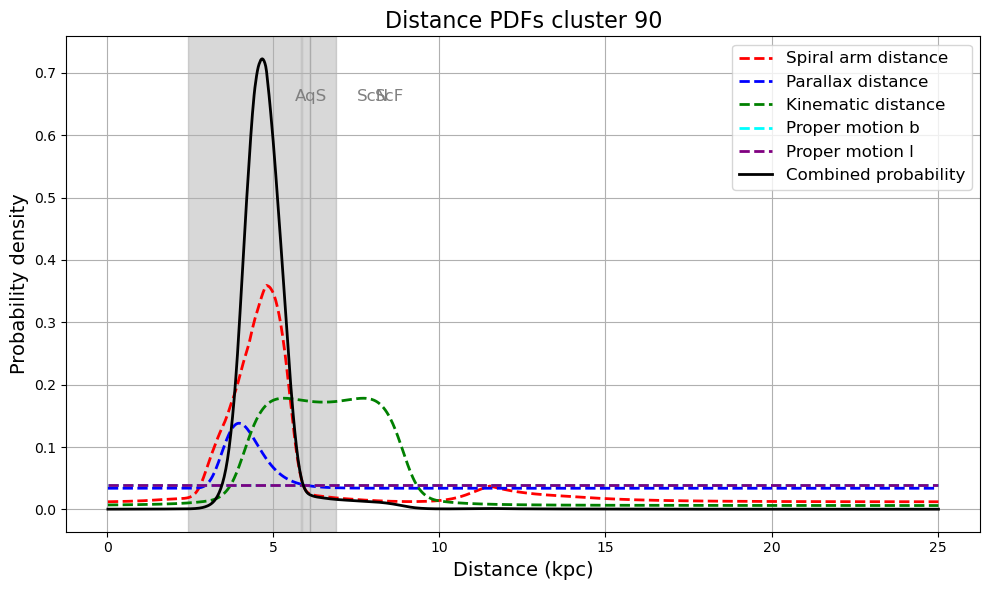

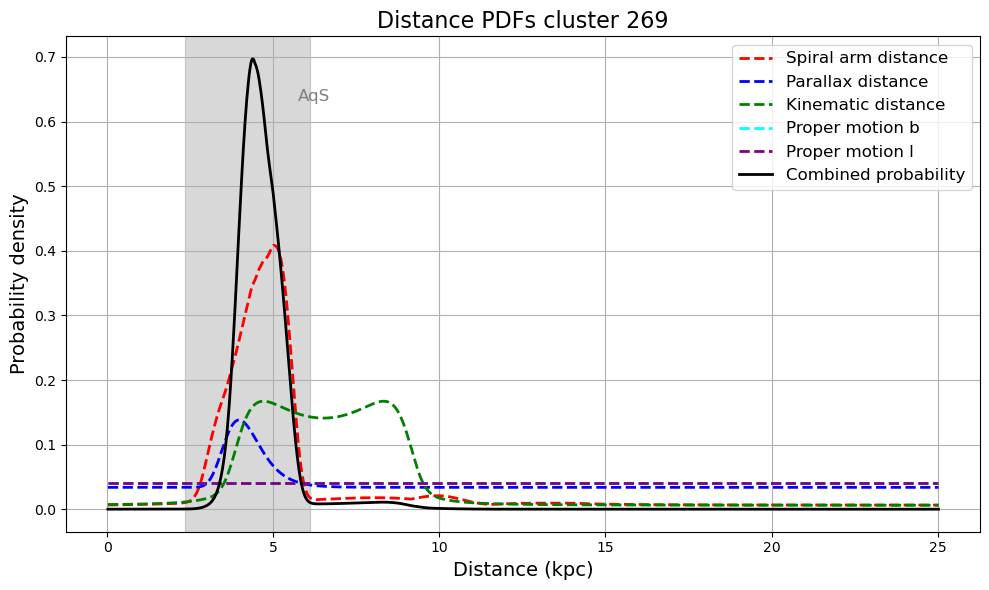

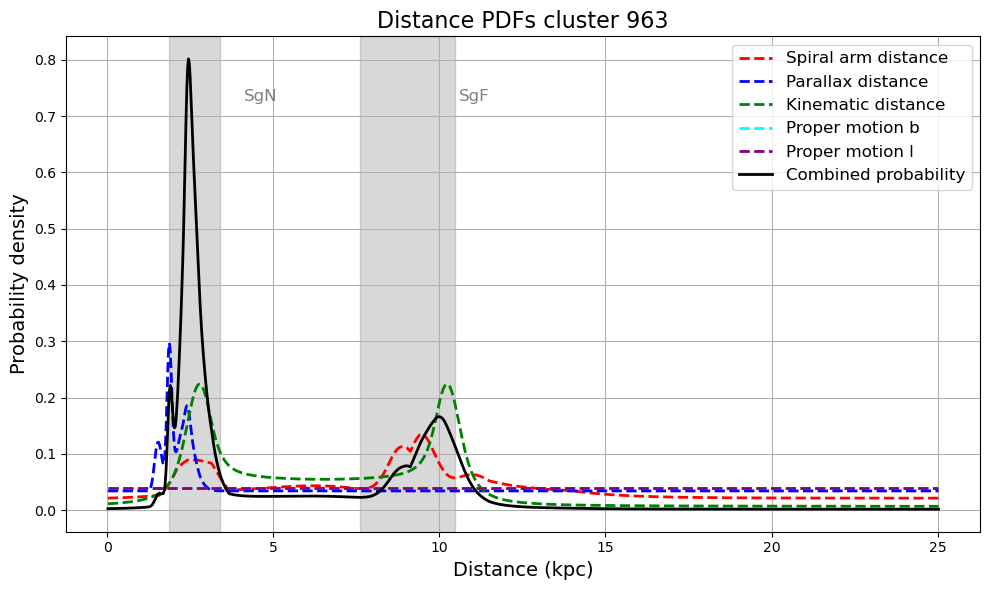

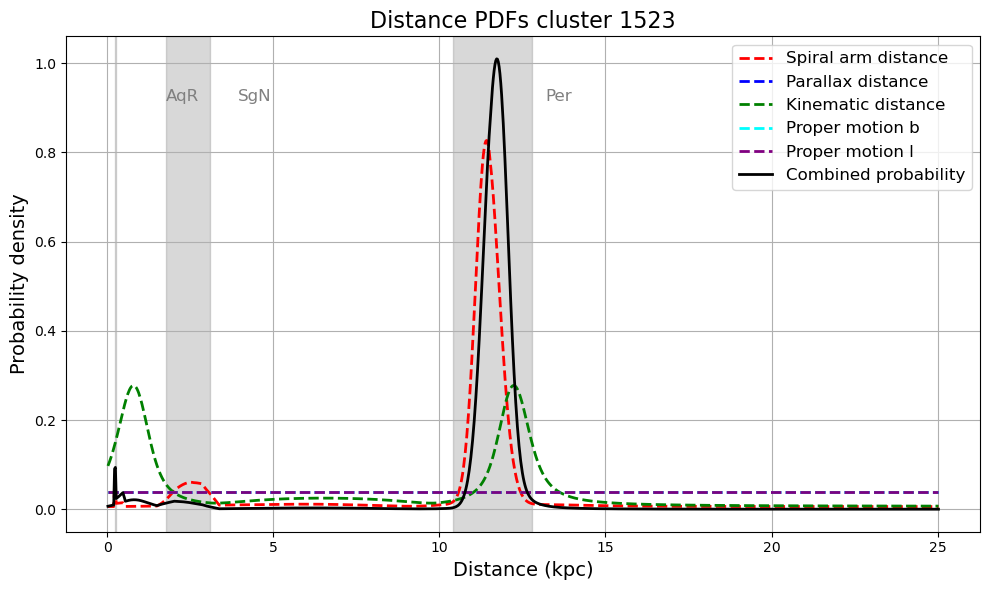

In [631]:
# Plots the distances
# Run fearlessly and optionally

def plot_distance_pdf(cluster_number,distance_dir):

    data_final     = np.loadtxt(distance_dir + f'{cluster_number}_final_distance_pdf.dat', skiprows=2)  # Skip header: "D(kpc) Probability"
    distances1     = data_final[:, 0]   # Column 1: D(kpc)
    probabilities1 = data_final[:, 1]  # Column 2: Probability

    data_spiral    = np.loadtxt(distance_dir + str(cluster_number)+'_arm_latitude_pdf.dat', skiprows=2, usecols=(0, 1))
    distances2     = data_spiral[:, 0]
    probabilities2 = data_spiral[:, 1]

    data_parallax  = np.loadtxt(distance_dir + str(cluster_number)+'_parallaxes_pdf.dat', skiprows=2)
    distances3     = data_parallax[:, 0]
    probabilities3 = data_parallax[:, 1]

    data_kinematic = np.loadtxt(distance_dir + str(cluster_number)+'_kinematic_distance_pdf.dat', skiprows=2)
    distances4     = data_kinematic[:, 0]
    probabilities4 = data_kinematic[:, 1]

    data_latitude  = np.loadtxt(distance_dir + str(cluster_number)+'_pm_bee_distance_pdf.dat', skiprows=2)
    distances5     = data_latitude[:, 0]
    probabilities5 = data_latitude[:, 1]

    data_longitude = np.loadtxt(distance_dir + str(cluster_number)+'_pm_ell_distance_pdf.dat', skiprows=2)
    distances6     = data_longitude[:, 0]
    probabilities6 = data_longitude[:, 1]
    
    arm_ranges = []
    arm_file = distance_dir + str(cluster_number) + '_arm_ranges.dat'
    with open(arm_file, 'r') as f:
        for line in f:
            if line.strip().startswith('!') or not line.strip():
                continue
            parts = line.split()
            start, end, name = float(parts[0]), float(parts[1]), parts[2]
            if start > 0 and end > 0:
                arm_ranges.append((start, end, name))

# Plotting
    plt.figure(figsize=(10, 6))
    
    ymax = max(probabilities1)  # Adjust if you'd rather base it on other curves or overall max

    for start, end, name in arm_ranges:
    # Shading (transparent and no legend entry)
        plt.axvspan(start, end, color='gray', alpha=0.3, zorder=0)

    # Label the spiral arm at the midpoint
        midpoint = (start + end) / 2
        plt.text(midpoint+2, ymax * 0.9, name, fontsize=12, ha='center', va='bottom', color='gray')
    
    plt.plot(distances2, probabilities2, label='Spiral arm distance', color='red', lw=2, linestyle='--')
    plt.plot(distances3, probabilities3, label='Parallax distance', color='blue', lw=2, linestyle='--')
    plt.plot(distances4, probabilities4, label='Kinematic distance', color='green', lw=2, linestyle='--')
    plt.plot(distances5, probabilities5, label='Proper motion b', color='cyan', lw=2, linestyle='--')
    plt.plot(distances6, probabilities6, label='Proper motion l', color='purple', lw=2, linestyle='--')
    plt.plot(distances1, probabilities1, label='Combined probability', color='black', lw=2)

    plt.xlabel('Distance (kpc)', fontsize=14)
    plt.ylabel('Probability density', fontsize=14)
    plt.title(f'Distance PDFs cluster {cluster_number}', fontsize=16)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for id in cluster_ids:
    plot_distance_pdf(id, distance_dir)

# Part 3 of big code, rotation curve

In [632]:
# Initialisess stuff
# Run fearlessly

os.chdir(clusters_path)

# Constants
a1, a2, a3 = 1.0077, 0.0394, 0.0071  # Brand & Blitz (1993)
theta0     = 236.0              # km/s
R0         = 8.15               # kpc
omega0     = theta0 / R0
dtor       = pi / 180

# Initialize outputs
n              = len(df)
R              = np.zeros(n)
Vcalc          = np.zeros(n)
d_near         = np.zeros(n)
d_far          = np.zeros(n)
distance       = np.full(n, np.nan)
dist_method    = np.zeros(n, dtype=int)

In [633]:
# Full rotation curve code
# Run fearlessly

# Step 1: Rotation Curve + Near/Far Distance Calculation
for i in range(n):
    l, b, V = df['x_cen'][i], df['y_cen'][i], df['v_cen'][i]/1000
    
    Ri = 0.5
    while True:
        Ri += 0.01
        wi = omega0 * ((a1 * (Ri/R0)**(a2 - 1)) + a3 * (R0 / Ri))
        Vtest = R0 * (wi - omega0) * sin(radians(l)) * cos(radians(b))
        if abs(Vtest - V) < 0.4:
            break
    
    R[i] = Ri
    Vcalc[i] = Vtest

    A = cos(radians(b))**2
    B = 2 * R0 * cos(radians(b)) * cos(radians(l))
    C = R0**2 - Ri**2
    delta = B**2 - 4 * A * C

    if delta <= 0:
        d1 = d2 = R0 * cos(radians(l)) / cos(radians(b))
    else:
        sqrt_delta = sqrt(delta)
        d1 = -( -B + sqrt_delta ) / (2 * A)
        d2 = -( -B - sqrt_delta ) / (2 * A)

    d_near[i], d_far[i] = min(d1, d2), max(d1, d2)

    # Outer Galaxy check
    if R[i] >= R0 or d_near[i] <= 0:
        distance[i] = d_far[i]
        dist_method[i] = 2  # Outer Galaxy

# Step 2: Tangent Point Method
# Apply only to unresolved sources (dist_method = 0)
for i in range(n):
    if dist_method[i] != 0:
        continue
    l = df['x_cen'][i]
    V = df['v_cen'][i]
    tan_vel = theta0 * sin(radians(l))
    if abs(V - tan_vel) < 10 and (d_far[i] - d_near[i]) <= 1.0:
        distance[i] = (d_near[i] + d_far[i]) / 2
        dist_method[i] = 3  # Tangent method

# Step 3: Scale Height Method
# Still unresolved sources
for i in range(n):
    if dist_method[i] != 0:
        continue
    b = df['y_cen'][i]
    z = d_far[i] * 1000 * tan(radians(b))  # pc
    if abs(z) > 120:
        distance[i] = d_near[i]
        dist_method[i] = 4  # Scale height method

# Step 4: Append Results
df['R_GC'] = R
df['d_near'] = d_near
df['d_far'] = d_far
df['distance'] = distance
df['dist_method'] = dist_method

# Part 4 of big code, selecting the right distance

In [95]:
# Function definition
# Run fearlessly

def determine_distance_assignment(txt_path, d_near, d_far):
    components = []

    with open(txt_path, 'r') as f:
        lines = f.readlines()

    # Filter lines that contain "Probability component"
    prob_lines = [line.strip() for line in lines if line.strip().startswith("Probability component")]

    for line in prob_lines:
        parts = line.split()
        try:
            dist = float(parts[3])
            prob = float(parts[5])
            components.append((dist, prob))
        except (IndexError, ValueError):
            continue

    if not components:
        raise ValueError("No valid probability components found.")

    # Get distance of component with highest probability
    best_dist, _ = max(components, key=lambda x: x[1])
    
    all_distances = [comp[0] for comp in components]
    min_distance = min(all_distances)
    max_distance = max(all_distances)

    if abs(best_dist - d_near) <= abs(best_dist - d_far):
            return 'near'
    else:
            return 'far'

prt_dir = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'  # Update if needed
final_distances = []
distance_flags = []  # Optional: stores 'near' or 'far'

In [635]:
# Selects near or far distances
# Run fearlessly

for idx, row in df.iterrows():
    obj_id = int(row['_idx'])
    prt_file = os.path.join(prt_dir, f"{obj_id}.prt")

    try:
        choice = determine_distance_assignment(prt_file, row['d_near'], row['d_far'])
        if choice == 'near':
            final_distances.append(row['d_near'])
            distance_flags.append('near')
        else:
            final_distances.append(row['d_far'])
            distance_flags.append('far')
    except Exception as e:
        print(f"Warning: Failed to process {prt_file} due to {e}")
        final_distances.append(np.nan)
        distance_flags.append('error')

df['distance'] = final_distances
df['distance_flag'] = distance_flags  # Optional for debugging
#df['structure_type'] = df['structure_type'].str.decode('utf-8').str.strip() 

# Part 5 of big code: Fluxes and pixels

In [636]:
# Initialise stuff and 
# Run fearlessly

def run_command(command, cwd=None):
    print(f"Running command: {command}")
    result = subprocess.run(command, shell=True, cwd=cwd, text=True, capture_output=True)
    if result.returncode != 0:
        print(f"Error: {result.stderr}")
    else:
        print(result.stdout)
        
# --- Get the numbers of the clusters we work with ---
cluster_numbers = df['_idx']


# --- Load original data ---
with fits.open(os.path.join(clusters_path, input_filename)) as hdul:
    data = hdul[0].data
    header = hdul[0].header


# --- Grab the SNR mask ---
try:
    if os.path.exists(SNR_filename):
        with fits.open(SNR_filename) as hdul_SNR:
            data_SNR = hdul_SNR[0].data
            header_SNR = hdul_SNR[0].header
        mask_SNR = (data_SNR > SNR_lim)
    else:
        raise FileNotFoundError
except FileNotFoundError:
    print(f"Warning: {SNR_filename} not found. Using all-True mask.")
    # Create a dummy all-True mask of compatible shape
    # You must already have a known shape, e.g., from another array
    mask_SNR = np.ones_like(data, dtype=bool)

# --- Load COLTE densities ---
has_COLTE = False
try:
    if os.path.exists(COLTE_N13_file):
        with fits.open(COLTE_N13_file) as hdul_COLTE_N13:
            data_COLTE_N13 = hdul_COLTE_N13[0].data
            header_COLTE_N13 = hdul_COLTE_N13[0].header
        has_COLTE = True
    else:
        raise FileNotFoundError
except FileNotFoundError:
    print(f"Warning: {COLTE_N13_file} not found. Using all-True mask.")
    # Create a dummy all-True mask of compatible shape
    # You must already have a known shape, e.g., from another array
    colte_masked = np.ones_like(data, dtype=bool)

starlink_path=  '/usr/local/star-2023A/bin/convert/fits2ndf'
source_command = f"source {starlink_path}"

In [637]:
# Create the integrated files (not save) and the flux and pixel columns
# Modified version that calculates masses from COLTE N13. Will replace the original
# Run fearlessly

run_command(f"/usr/local/star-2023A/bin/convert/fits2ndf {mult_filename} {mult_sdf}")

#has_COLTE = False

nonzero_pixels = []
total_flux     = []
COLTE_Mass     = []

# --- Loop over each number and create individual FITS files ---
for num in cluster_numbers:
    mask = (data == num)
    if num == 0:
        # Replace cluster 0 voxels with 1, keep background (-1) untouched
        new_data = np.where(mask, 1, 0)
    else:
        new_data = np.where(mask, data, 0)
    new_data = np.where(mask_SNR, new_data, 0)
    
    
    if has_COLTE:
        # Only calculate COLTE-based mass if we have the file
        colte_masked = np.where(mask, data_COLTE_N13, 0)
        colte_mass   = np.nansum(colte_masked) * np.abs(header_COLTE_N13['CDELT3'])
        if header_COLTE_N13['CUNIT3'] == 'm/s':
            colte_mass = colte_mass / 1000
    else:
        colte_mass = 0

    COLTE_Mass.append(colte_mass)

    # Apply COLTE masking only if available (currently just a test anyway)
    if has_COLTE:
        mask_COLTE = (~np.isnan(colte_masked)) & (colte_masked > 0) # Temporary test, remove!
        new_data   = np.where(mask_COLTE, new_data, 0) # Temporary test, remove!

    output_filename = f"{base_prefix}_{num}.fits"
    output_filename = os.path.join(clusters_path, output_filename)
    
    hdu = fits.PrimaryHDU(new_data, header=header)
    hdu.writeto(output_filename, overwrite=True)
    print(f"Written: {output_filename}")
    
    ndffile         = f"{base_prefix}_{num}.sdf"
    run_command(f"/usr/local/star-2023A/bin/convert/fits2ndf {output_filename} {ndffile}")
    os.system('rm -rf ' + output_filename)
    
    ndffile_2       = f"{base_prefix}_{num}_masked.sdf"
    run_command(f"/usr/local/star-2023A/bin/kappa/mult IN1={mult_sdf} IN2={ndffile} OUT={ndffile_2}")
    os.system('rm -rf '+ndffile)

    if num ==0:
        num = 1
    ndffile_3       = f"{base_prefix}_{num}_data.sdf"
    run_command(f"/usr/local/star-2023A/bin/kappa/cdiv {ndffile_2} SCALAR={num} OUT={ndffile_3}")
    os.system('rm -rf '+ndffile_2)
    
    #run_command(f"/usr/local/star-2023A/bin/convert/ndf2fits {ndffile_3} OUT={'*'}")
    
    ndffile_4           = f"{base_prefix}_{num}_integ.sdf"
    fits_file_int       = f"{base_prefix}_{num}_integ.fit"
    run_command(f"/usr/local/star-2023A/bin/kappa/collapse estimator=integ {ndffile_3} AXIS={'VRAD'} OUT={ndffile_4}")
    run_command(f"/usr/local/star-2023A/bin/convert/ndf2fits {ndffile_4} OUT={'*'}")
    os.system('rm -rf '+ndffile_3)
    os.system('rm -rf '+ndffile_4)

    print(num)
    
    clust_data, headerr = fits.getdata(fits_file_int, 0, header=True)
    clust_good          = clust_data[~isnan(clust_data)]
    clust_good          = clust_good[clust_good>=0]
    pixels_nonzero      = np.count_nonzero(clust_good)
    integ_flux          = np.sum(clust_good)
    os.system('rm -rf '+fits_file_int)

    if header['CUNIT3'] == 'm/s':
        integ_flux = integ_flux / 1000

    total_flux.append(integ_flux)
    nonzero_pixels.append(pixels_nonzero)
    print("cluster pixels sum:", new_data.sum()) # Number of valid voxels (pre-integration, not pixels!) multiplied by cluster number
    print("integrated flux:", integ_flux)
    print("number of pixels:", pixels_nonzero)
    print("colte total density:", colte_mass)

os.system('rm -rf ' +mult_sdf) 

Running command: /usr/local/star-2023A/bin/convert/fits2ndf /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned.fits /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned.sdf
1 file selected.



Written: /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster_90.fits
Running command: /usr/local/star-2023A/bin/convert/fits2ndf /Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster_90.fits FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster_90.sdf
1 file selected.

Running command: /usr/local/star-2023A/bin/kappa/mult IN1=/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned.sdf IN2=FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster_90.sdf OUT=FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster_90_masked.sdf

Running command: /usr/local/star-2023A/bin/kappa/cdiv FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster_90_masked.sdf SCALAR=90 OUT=FGN_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_cluster_90_data.sdf

Running command: /usr/local/star-2023A/bin/kappa/collapse estimator=integ FGN_037_13CO_

0

In [ ]:
# Create the integrated files (not save) and the flux and pixel columns
# Run fearlessly

run_command(f"/usr/local/star-2023A/bin/convert/fits2ndf {mult_filename} {mult_sdf}")

nonzero_pixels = []
total_flux     = []

# --- Loop over each number and create individual FITS files ---
for num in cluster_numbers:
    mask = (data == num)
    if num == 0:
        # Replace cluster 0 voxels with 1, keep background (-1) untouched
        new_data = np.where(mask, 1, 0)
    else:
        new_data = np.where(mask, data, 0)
    new_data = np.where(mask_SNR, new_data, 0)

    
    output_filename = f"{base_prefix}_{num}.fits"
    output_filename = os.path.join(clusters_path, output_filename)
    
    hdu = fits.PrimaryHDU(new_data, header=header)
    hdu.writeto(output_filename, overwrite=True)
    print(f"Written: {output_filename}")
    
    ndffile         = f"{base_prefix}_{num}.sdf"
    run_command(f"/usr/local/star-2023A/bin/convert/fits2ndf {output_filename} {ndffile}")
    os.system('rm -rf ' + output_filename)
    
    ndffile_2       = f"{base_prefix}_{num}_masked.sdf"
    run_command(f"/usr/local/star-2023A/bin/kappa/mult IN1={mult_sdf} IN2={ndffile} OUT={ndffile_2}")
    os.system('rm -rf '+ndffile)

    if num == 0:
        num = 1
    ndffile_3       = f"{base_prefix}_{num}_data.sdf"
    run_command(f"/usr/local/star-2023A/bin/kappa/cdiv {ndffile_2} SCALAR={num} OUT={ndffile_3}")
    os.system('rm -rf '+ndffile_2)
    
    #run_command(f"/usr/local/star-2023A/bin/convert/ndf2fits {ndffile_3} OUT={'*'}")
    
    ndffile_4           = f"{base_prefix}_{num}_integ.sdf"
    fits_file_int       = f"{base_prefix}_{num}_integ.fit"
    run_command(f"/usr/local/star-2023A/bin/kappa/collapse estimator=integ {ndffile_3} AXIS={'VRAD'} OUT={ndffile_4}")
    run_command(f"/usr/local/star-2023A/bin/convert/ndf2fits {ndffile_4} OUT={'*'}")
    os.system('rm -rf '+ndffile_3)
    os.system('rm -rf '+ndffile_4)

    print(num)
    
    clust_data, headerr = fits.getdata(fits_file_int, 0, header=True)
    clust_good          = clust_data[~isnan(clust_data)]
    clust_good          = clust_good[clust_good>=0]
    pixels_nonzero      = np.count_nonzero(clust_good)
    integ_flux          = np.sum(clust_good)
    os.system('rm -rf '+fits_file_int)

    if header['CUNIT3'] == 'm/s':
        integ_flux = integ_flux / 1000

    total_flux.append(integ_flux)
    nonzero_pixels.append(pixels_nonzero)
    print(integ_flux, pixels_nonzero)

os.system('rm -rf ' +mult_sdf) 

In [638]:
# Append the columns to the df and verify it

df['total_flux']   = total_flux # actually integrated
df['pixel_number'] = nonzero_pixels 
df['COLTE_Density']   = COLTE_Mass
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,AGAL_distance,R_GC,d_near,d_far,distance,dist_method,distance_flag,total_flux,pixel_number,COLTE_Density
0,90,4624.813273,8031.0,41.711077,25.459206,-137.997467,32.587282,86917.517870,5.244042,36.882046,...,0,5.03,5.346319,7.691799,5.346319,0,near,13058.92400,5271,0
1,269,13741.396697,25821.0,82.658104,38.172227,170.668183,56.171558,79983.359254,3.285489,36.915112,...,5.8,5.19,4.791713,8.240583,4.791713,0,near,149963.42400,25224,0
2,963,1352.045523,3077.0,20.493931,15.148447,78.249722,17.619626,48941.348452,5.997127,37.014968,...,0,6.07,2.933921,10.081314,2.933921,0,near,2084.18025,1110,0
3,1523,4814.052029,9761.0,45.144060,24.485684,47.372031,33.247303,14676.756414,3.018051,36.903489,...,0,7.45,0.899930,12.134397,12.134397,0,far,6328.54900,4008,0


# Part 6 of big code: Final mass estimations

In [639]:
# Chooses between AGAL distance for clusters with matches and best distance for those without
# Looks like AGAL distances are strings! turn them to floats first.
# Run fearlessly

final_distance = []
for i in range(len(df)):
    if df['has_match'][i] and df['AGAL_distance'][i] != '---':
        final_distance.append(float(df['AGAL_distance'][i]))
    else:
        final_distance.append(df['distance'][i])

In [640]:
# Append the distances
df['final_distance'] = final_distance
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,R_GC,d_near,d_far,distance,dist_method,distance_flag,total_flux,pixel_number,COLTE_Density,final_distance
0,90,4624.813273,8031.0,41.711077,25.459206,-137.997467,32.587282,86917.517870,5.244042,36.882046,...,5.03,5.346319,7.691799,5.346319,0,near,13058.92400,5271,0,5.346319
1,269,13741.396697,25821.0,82.658104,38.172227,170.668183,56.171558,79983.359254,3.285489,36.915112,...,5.19,4.791713,8.240583,4.791713,0,near,149963.42400,25224,0,5.800000
2,963,1352.045523,3077.0,20.493931,15.148447,78.249722,17.619626,48941.348452,5.997127,37.014968,...,6.07,2.933921,10.081314,2.933921,0,near,2084.18025,1110,0,2.933921
3,1523,4814.052029,9761.0,45.144060,24.485684,47.372031,33.247303,14676.756414,3.018051,36.903489,...,7.45,0.899930,12.134397,12.134397,0,far,6328.54900,4008,0,12.134397


In [641]:
# Spreadsheet calculations
# Run fearlesly

df['distance_cm'] = df['final_distance'] * 3.086 * pow(10,21)
df['Mean_flux']   =df['total_flux'] / df['pixel_number'] # actually integrated, not mean

# Constants
if isotopologue == "13CO":
    if dataset == "CHIMPS" or dataset == "COHRS":
        X_factor = 4.3 * pow(10,21)
    elif dataset == "FGN":
        X_factor = 2 * pow(10,20) * 3.26
elif isotopologue == "12CO":
    if dataset == "CHIMPS" or dataset == "COHRS":
        X_factor = 4 * pow(10,20)
    elif dataset == "FGN":
        X_factor = 2 * pow(10,20)
elif isotopologue == "C18O":
    X_factor       = 2 * pow(10,20) * 3.26 * 6.5
    
mH2            = 1.67 * 2.33 * pow(10,-24)
Msol           = 2 * pow(10,33)
pixel_area_arc = pow(1.66*3.6,2)
arc_2_sr       = pow(np.pi/180/3600,2)

df['density']=X_factor*df['Mean_flux']

# Ellipse masses
df['semi_major_deg']= df['major_arcsec'] / 7200  # Divide by 7200 to turn major to semi-major too
df['semi_minor_deg']= df['minor_arcsec'] / 7200
df['semi_major_cm'] = df['semi_major_deg'] * df['distance_cm'] * np.pi / 180 * 2.354
df['semi_minor_cm'] = df['semi_minor_deg'] * df['distance_cm'] * np.pi / 180 * 2.354
df['NH2_ellipse']   = df['density'] * np.pi * df['semi_major_cm'] * df['semi_minor_cm']
df['M_ellipse_g']   = df['NH2_ellipse'] * mH2


# Pixel area masses
df['angular_size_sr']       = df['pixel_number'] * pixel_area_arc * arc_2_sr
df['area_cm2_pixel_method'] = df['angular_size_sr'] * pow(df['distance_cm'],2)
df['NH2_pixel']             = df['area_cm2_pixel_method'] * df['density']
df['M_pixel_g']             = df['NH2_pixel'] * mH2

df['M_ellipse_Sol'] = df['M_ellipse_g'] / Msol   
df['M_pixel_Sol']   = df['M_pixel_g'] / Msol
df['M_COLTE_Sol_CO']   = df['COLTE_Density'] / Msol * pixel_area_arc * arc_2_sr * pow(df['distance_cm'],2) * mH2

In [642]:
# Formatting the df
# Run fearlessly

df['area_ellipse']   = df['area_ellipse'].round(1)  # Round to 1 decimal place
df['area_exact']     = df['area_exact'].round(1)
df['major_sigma']    = df['major_sigma'].round(1)
df['minor_sigma']    = df['minor_sigma'].round(1)
df['position_angle'] = df['position_angle'].round(1)
df['radius']         = df['radius'].round(1)
df['v_cen']          = df['v_cen'].round(2)
df['v_rms']          = df['v_rms'].round(2)
df['x_cen']          = df['x_cen'].round(3)
df['y_cen']          = df['y_cen'].round(3)
df['radius_arcsec']  = df['radius_arcsec'].round(1)
df['sigv_kms']       = df['sigv_kms'].round(2)
df['xcens']          = df['xcens'].round(3)
df['ycens']          = df['ycens'].round(3)
df['vcens']          = df['vcens'].round(3)
df['major_arcsec']   = df['major_arcsec'].round(1)
df['minor_arcsec']   = df['minor_arcsec'].round(1)
df['R_GC']           = df['R_GC'].round(2)
df['d_near']         = df['d_near'].round(2)
df['d_far']          = df['d_far'].round(2)
df['distance']       = df['distance'].round(2)
df['final_distance'] = df['final_distance'].round(2)


df['distance_cm']           = df['distance_cm'].apply(lambda x: f'{x:.2e}') # Write to format 1e7
df['Mean_flux']             = df['Mean_flux'].round(2)
df['density']               = df['density'].apply(lambda x: f'{x:.2e}')
df['semi_major_deg']        = df['semi_major_deg'].round(3)
df['semi_minor_deg']        = df['semi_minor_deg'].round(3)
df['semi_major_cm']         = df['semi_major_cm'].apply(lambda x: f'{x:.2e}')
df['semi_minor_cm']         = pd.to_numeric(df['semi_minor_cm']).apply(lambda x: f'{x:.2e}')
df['NH2_ellipse']           = df['NH2_ellipse'].apply(lambda x: f'{x:.2e}')
df['M_ellipse_g']           = df['M_ellipse_g'].apply(lambda x: f'{x:.2e}')
df['M_ellipse_Sol']         = df['M_ellipse_Sol'].apply(lambda x: f'{x:.2e}')
df['angular_size_sr']       = df['angular_size_sr'].apply(lambda x: f'{x:.2e}')
df['area_cm2_pixel_method'] = df['area_cm2_pixel_method'].apply(lambda x: f'{x:.2e}')
df['NH2_pixel']             = df['NH2_pixel'].apply(lambda x: f'{x:.2e}')
df['M_COLTE_Sol_CO']        = df['M_COLTE_Sol_CO'].apply(lambda x: f'{x:.2e}')
df['COLTE_Density']         = df['COLTE_Density'].apply(lambda x: f'{x:.2e}')
df['M_pixel_g']             = df['M_pixel_g'].apply(lambda x: f'{x:.2e}')
df['M_pixel_Sol']           = df['M_pixel_Sol'].apply(lambda x: f'{x:.2e}')

In [643]:
# Save final result with proper structure types
csv_output        = mult_path +f"{dataset}_{isotopologue}_{region}_X-factor_masses_SNR{SNR_lim}.csv"
df.to_csv(csv_output, index= False)

#df.to_csv(f'{dataset}_{region}_{isotopologue}_X_factor_masses_COLTE_pixelv2.csv', index= False)
#df.to_csv(f'{dataset}_{region}_{isotopologue}_sphere1_doubled_halfsigma_044noise_3D.csv', index= False)
#df.to_csv('out_01_mass.csv', index= False)
df_sub = df[df["sigv_kms"] > v_lim2 / 2.354]

#df_sub.to_csv(csv_output_sub, index= False)

# End of big distance main code

In [54]:
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

mass = df_2['M_Sol_X 13CO 1-0']
distance_cm = df_2['final_distance'] * 3.086 * pow(10,21)

semi_major_deg= df_2['major_arcsec'] / 3600  # Divide by 3600, major arcsec is semi, actually!
semi_minor_deg= df_2['minor_arcsec'] / 3600
semi_major_cm = semi_major_deg * distance_cm * np.pi / 180 * 2.354
semi_minor_cm = semi_minor_deg * distance_cm * np.pi / 180 * 2.354


rad_pc= (semi_major_cm/3.086E18*semi_minor_cm/3.086E18)**(1/2) / 2
surface_density = mass / np.pi / rad_pc ** 2
m = df_2['M_Sol_X 13CO 1-0'].dropna()
destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
df_2['radius(pc)']=rad_pc
R = np.asarray(rad_pc, dtype=float)

In [20]:
os.path.isfile(mult_filename)

True

In [21]:
np.shape(data)

(438, 607, 5590)

In [22]:
np.shape(mask_SNR)

(438, 607, 5590)

In [23]:
np.shape(cluster_numbers)

(279,)

In [24]:
np.shape(total_flux)

(279,)

In [25]:
if isotopologue == "13CO":
    if dataset == "CHIMPS" or dataset == "COHRS":
        X_factor = 4.3 * pow(10,21)
    elif dataset == "FGN":
        X_factor = 2.295 * pow(10,21)
elif isotopologue == "12CO":
    if dataset == "CHIMPS" or dataset == "COHRS":
        X_factor = 4 * pow(10,20)
    elif dataset == "FGN":
        X_factor = 2.295 * pow(10,21) / 8.5
elif isotopologue == "C18O":
    X_factor       = 2.295 * pow(10,21) * 6.5
X_factor

4.2e+20

In [26]:
X_factor

4.2e+20

In [45]:
df = pd.read_csv("CHIMPS_13CO_017_047_vrms_3_mass_catalogue.csv")  # Example CSV

In [46]:
df

,new_ID,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,...,semi_major_cm,semi_minor_cm,NH2_ellipse,M_ellipse_g,angular_size_sr,area_cm2_pixel_method,NH2_pixel,M_pixel_g,M_ellipse_Sol,M_pixel_Sol
0,1,23,10475.9,24269,77.5,31.0,-153.3,49.0,121215.69,4.18,...,7.530000e+19,3.010000e+19,4.550000e+61,1.770000e+38,1.890000e-05,1.540000e+40,9.800000e+61,3.810000e+38,88500.0,191000.0
1,2,58,1536.9,5938,24.5,14.4,51.3,18.8,120036.92,2.85,...,1.990000e+19,1.170000e+19,9.130000e+60,3.550000e+37,4.770000e-06,2.690000e+39,3.370000e+61,1.310000e+38,17800.0,65600.0
2,3,71,4837.6,8140,71.1,15.6,159.8,33.3,121537.93,4.02,...,6.940000e+19,1.520000e+19,6.260000e+60,2.440000e+37,5.970000e-06,4.900000e+39,9.220000e+60,3.590000e+37,12200.0,17900.0
3,4,187,1296.3,2454,20.2,14.7,164.3,17.3,116577.30,5.12,...,1.940000e+19,1.410000e+19,1.830000e+60,7.120000e+36,1.860000e-06,1.460000e+39,3.120000e+60,1.210000e+37,3560.0,6070.0
4,5,336,13732.9,24540,68.1,46.3,166.5,56.2,116260.00,4.73,...,6.680000e+19,4.540000e+19,3.580000e+61,1.390000e+38,1.880000e-05,1.560000e+40,5.840000e+61,2.270000e+38,69700.0,114000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
706,707,12141,567.3,1208,15.3,8.5,-162.6,11.4,8330.10,2.80,...,1.780000e+19,9.840000e+18,7.290000e+59,2.840000e+36,8.410000e-07,9.720000e+38,1.290000e+60,5.010000e+36,1420.0,2510.0
707,708,12177,255.0,684,8.6,6.8,-169.3,7.7,6563.56,2.80,...,1.060000e+19,8.270000e+18,3.180000e+60,1.240000e+37,5.440000e-07,6.970000e+38,8.080000e+60,3.140000e+37,6180.0,15700.0
708,709,12298,474.6,1448,13.8,7.9,60.9,10.4,4315.07,3.56,...,1.650000e+19,9.440000e+18,9.850000e+59,3.830000e+36,9.750000e-07,1.200000e+39,2.410000e+60,9.390000e+36,1920.0,4690.0
709,710,12332,8475.9,12112,72.3,26.9,105.8,44.1,1887.39,3.94,...,9.770000e+19,3.640000e+19,3.490000e+61,1.360000e+38,9.340000e-06,1.470000e+40,4.580000e+61,1.780000e+38,67900.0,89100.0


In [9]:
rad_pc= (df['semi_major_cm']/3.086E18*df['semi_minor_cm']/3.086E18)**(1/2)
df['radius(pc)']=rad_pc

Best-fit parameters: c = 0.0060, a = 0.4800


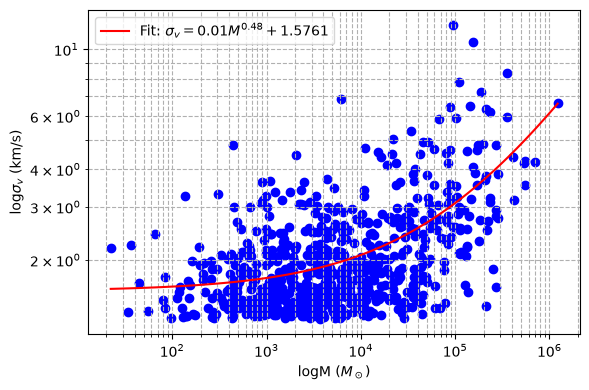

In [3]:
from scipy.optimize import curve_fit

# Extract your data (make sure they're numpy arrays and filtered for non-NaNs)
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

M = df_2['M_Sol_X 13CO 1-0'].values
s = df_2['sigv_kms'].values

# Optional: filter out zeros or NaNs
mask = (M > 0) & (s > 0)
M = M[mask]
s = s[mask]

# Define the model: power law
def power_law(M, c, a, b):
    return c * M**a +b

# Fit the model
popt, pcov = curve_fit(power_law, M, s)
c_fit, a_fit, b_fit = popt

# Print results
print(f"Best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}")

# Plot the data and the fit
M_fit = np.logspace(np.log10(min(M)), np.log10(max(M)), 100)
s_fit = power_law(M_fit, c_fit, a_fit, b_fit)

plt.figure(figsize=(6, 4))
plt.scatter(M, s, color='blue')
plt.plot(M_fit, s_fit, label=fr'Fit: $\sigma_v = {c_fit:.2f} M^{{{a_fit:.2f}}} +{b_fit:.4f}$', color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('logM ($M_\odot$)')
plt.ylabel(r'log$\sigma_v$ (km/s)')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.tight_layout()
#plt.show()
#plt.savefig('Larson_mass_v_sigma_big_code.png')

Best-fit parameters: c = 1.5105, a = 0.2554


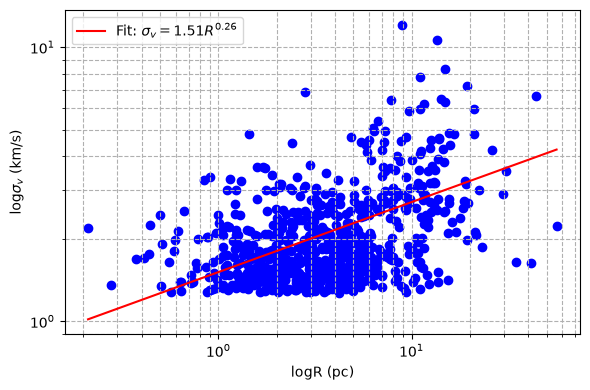

In [6]:
# Extract your data (make sure they're numpy arrays and filtered for non-NaNs)
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

R = np.asarray(rad_pc, dtype=float)
s = df_2['sigv_kms'].values

# Optional: filter out zeros or NaNs
mask = (R > 0) & (s > 0)
R = R[mask]
s = s[mask]

# Define the model: power law
def power_law(R, c, a):
    return c * R**a

# Fit the model
popt, pcov = curve_fit(power_law, R, s)
c_fit, a_fit = popt

# Print results
print(f"Best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}")

# Plot the data and the fit
R_fit = np.logspace(np.log10(min(R)), np.log10(max(R)), 100)
s_fit = power_law(R_fit, c_fit, a_fit)

plt.figure(figsize=(6, 4))
plt.scatter(R, s, color='blue')
plt.plot(R_fit, s_fit, label=fr'Fit: $\sigma_v = {c_fit:.2f} R^{{{a_fit:.2f}}}$', color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('logR (pc)')
plt.ylabel(r'log$\sigma_v$ (km/s)')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.tight_layout()
#plt.show()
#plt.savefig('Larson_radius_v_sigma_big_code.png')

Fit: log(2GM/σ^2R) = 0.7514 * log(R) + 2.1737


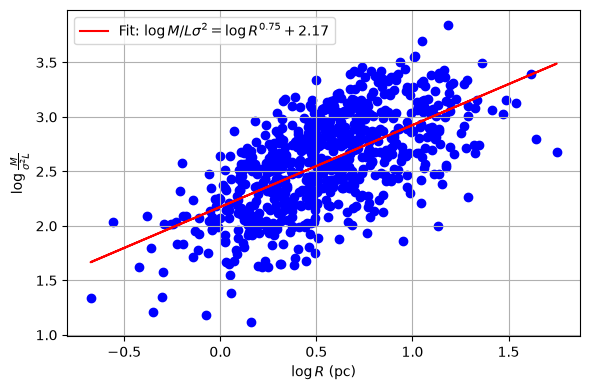

Best-fit parameters: c = 2992.8805, a = 0.1141


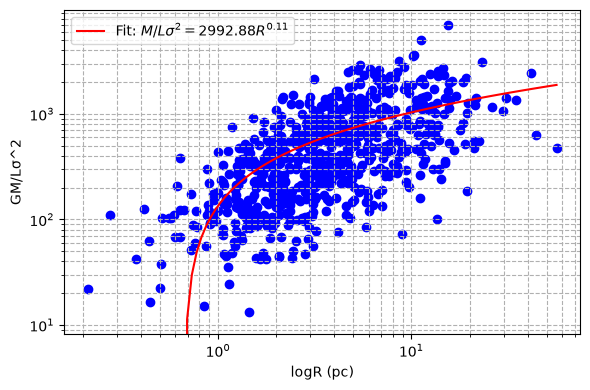

In [7]:
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

sigma = df_2['sigv_kms']
S = np.asarray(sigma, dtype = float)
R = np.asarray(rad_pc, dtype=float)
M = df_2['M_Sol_X 13CO 1-0'].values

#M = np.array([60000, 6, 300000, 40000, 30000, 20000, 10000, 100000, 10000, 5000, 500, 20000, 800, 14000, 30000, 1500, 2300, 4000, 8000, 600, 2500, 200, 100, 100, 15, 18, 31, 21, 1.6]) 
#R = np.array([25, 0.25, 130, 11, 5, 7, 3, 60, 8, 25, 3, 15, 1.8, 8, 15, 5, 4.5, 18, 7, 5, 2.3, 1.5, 0.8, 1.4, 1.1, 0.7, 0.63, 0.46, 0.22])
#S = np.array([1.9, 0.95, 3.7, 3.3, 2.8, 2, 3.5, 8.5, 3.1, 3, 2, 3.5, 1.9, 4.4, 2.8, 2.1, 2.2, 1.7, 2.6, 1.4, 1.3, 1.4, 0.75, 1.4, 0.7, 0.92, 0.67, 0.8, 0.53])

bruh = M/R/S/S

logbruh = np.log10(bruh)
logR = np.log10(R)

# Linear fit in log-log space
a_fit, c_fit = np.polyfit(logR, logbruh, 1)

print(f"Fit: log(2GM/σ^2R) = {a_fit:.4f} * log(R) + {c_fit:.4f}")

# Plot
plt.figure(figsize=(6, 4))
plt.scatter(logR, logbruh, color='blue')
plt.plot(logR, a_fit * logR + c_fit, color='red', label=fr'Fit: $\log M/Lσ^2 = \log R^{{{a_fit:.2f}}} + {c_fit:.2f}$')
plt.xlabel(r'$\log R$ (pc)')
plt.ylabel(r'$\log \frac{M}{\sigma^2L}$')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


def power_law(R, c, a, b):
    return c * R**a + b

# Fit the model
popt, pcov = curve_fit(power_law, R, bruh)
c_fit, a_fit, b_fit = popt

# Print results
print(f"Best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}")

# Plot the data and the fit
R_fit = np.logspace(np.log10(min(R)), np.log10(max(R)), 100)
bruh_fit = power_law(R_fit, c_fit, a_fit, b_fit)

plt.figure(figsize=(6, 4))
plt.scatter(R, bruh, color='blue')
plt.plot(R_fit, bruh_fit, label=fr'Fit: $M/Lσ^2 = {c_fit:.2f} R^{{{a_fit:.2f}}}$', color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('logR (pc)')
plt.ylabel(r'GM/Lσ^2')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.tight_layout()
#plt.show()
#plt.savefig('Larson_radius_v_sigma_big_code.png')

Weighted fit: log(M) = 2.1124 * log(R) + 2.5643
Parameter errors: 2.1124 ± 0.0294, 2.5643 ± 0.0194


c = 5310.5077 ± 764.4130
a = 1.0829 ± 0.0454
Power law with constant best-fit parameters: c = 5310.5077, a = 1.0829


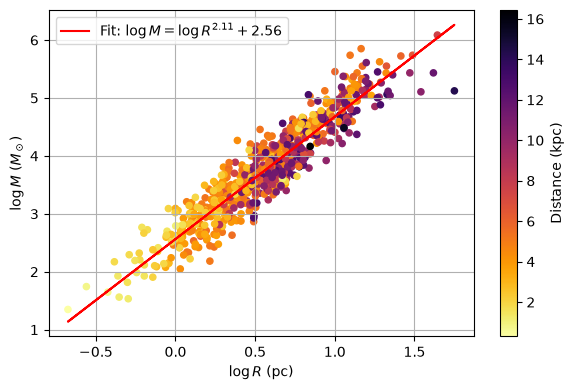

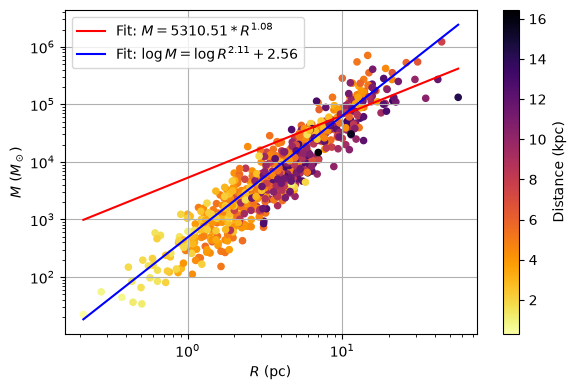

In [11]:
# import numpy as np
import matplotlib.pyplot as plt
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

# Extract and filter data
R = np.asarray(rad_pc, dtype=float)
M = np.asarray(mass, dtype=float)
W = df_2['final_distance'].values
mask = (R > 0) & (M > 0) & (W > 0)
R = R[mask]
M = M[mask]
W = W[mask]

logR = np.log10(R)
logM = np.log10(M)

# Define weights (e.g., directly or 1/W if you want inverse-distance weight)
weights = W  # or 1/W, or 1/W**2 depending on purpose

# Weighted polyfit
fit, cov = np.polyfit(logR, logM, 1, cov=True) # Add w=weights in this if you want weight
a1_fit, c1_fit = fit

a_err, c_err = np.sqrt(np.diag(cov))

C1 = 10**c1_fit
C1_err = C1 * np.log(10) * c_err  # error propagation

print(f"Weighted fit: log(M) = {a1_fit:.4f} * log(R) + {c1_fit:.4f}")
print(f"Parameter errors: {a1_fit:.4f} ± {a_err:.4f}, {c1_fit:.4f} ± {c_err:.4f}")
    
# Plot
plt.figure(figsize=(6, 4))
plt.scatter(logR, logM, c=W, cmap='inferno_r', s=20)#, edgecolor='k')
plt.plot(logR, a1_fit * logR + c1_fit, color='red', label=fr'Fit: $\log M = \log R^{{{a1_fit:.2f}}} + {c1_fit:.2f}$')

#plt.plot(logR, a_fit * logR + 1, '--', linewidth = 0.2, label=fr'Fit: $\log M = \log R^{{{a_fit:.2f}}} + 1$')
#plt.plot(logR, a_fit * logR + 2, '--', linewidth = 0.2, label=fr'Fit: $\log M = \log R^{{{a_fit:.2f}}} + 2$')
#plt.plot(logR, a_fit * logR + 3, '--', linewidth = 0.2, label=fr'Fit: $\log M = \log R^{{{a_fit:.2f}}} + 3$')
#plt.plot(logR, a_fit * logR + 4, '--', linewidth = 0.2, label=fr'Fit: $\log M = \log R^{{{a_fit:.2f}}} + 4$')

plt.xlabel(r'$\log R$ (pc)')
plt.ylabel(r'$\log M$ ($M_\odot$)')
plt.legend()
plt.grid(True)
plt.colorbar(label='Distance (kpc)')
plt.tight_layout()
#plt.show()
#plt.savefig(destination_path +'FUGIN_13CO_Mass_radius_python.png')

## And a power law with an extra term

def power_law(R, c, a):
    return c * R**a

# Fit the model
popt, pcov = curve_fit(power_law, R, M,sigma = 1/weights, absolute_sigma=False)
c_fit, a_fit = popt
c_err, a_err = np.sqrt(np.diag(pcov))
print("\n")
print(
    f"c = {c_fit:.4f} ± {c_err:.4f}\n"
    f"a = {a_fit:.4f} ± {a_err:.4f}"
)
C2_err, a2_err = np.sqrt(np.diag(pcov))

                       
# Print results
print(f"Power law with constant best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}")

# Plot the data and the fit
R_fit = np.logspace(np.log10(min(R)), np.log10(max(R)), 500)
M_fit = power_law(R_fit, c_fit, a_fit)

plt.figure(figsize=(6, 4))
plt.scatter(R, M, c=W, cmap='inferno_r', s=20)#, edgecolor='k')
plt.plot(R_fit, M_fit, color='red', label=fr'Fit: $M = {c_fit:.2f}*R^{{{a_fit:.2f}}}$')
plt.plot(R_fit, 10**2.69*R_fit**2.11,color='blue', label = fr'Fit: $\log M = \log R^{{{a1_fit:.2f}}} + {c1_fit:.2f}$')

plt.xlabel(r'$R$ (pc)')
plt.ylabel(r'$M$ ($M_\odot$)')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.colorbar(label='Distance (kpc)')
plt.tight_layout()

Fit: log(M) = 2.1124 * log(R) + 2.5643


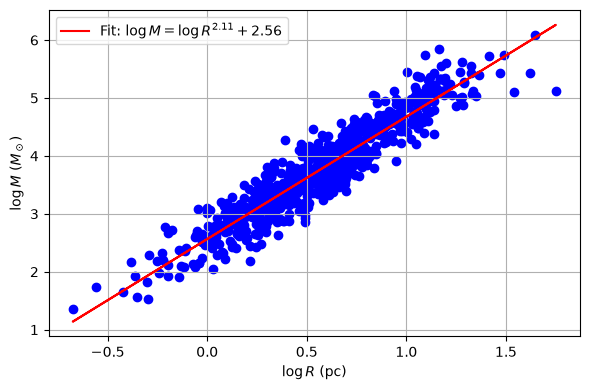

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Extract and filter data
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

R = np.asarray(rad_pc, dtype=float)
M = np.asarray(mass, dtype=float)
mask = (R > 0) & (M > 0)
R = R[mask]
M = M[mask]

# Take logs
logR = np.log10(R)
logM = np.log10(M)

# Linear fit in log-log space
a_fit, c_fit = np.polyfit(logR, logM, 1)

print(f"Fit: log(M) = {a_fit:.4f} * log(R) + {c_fit:.4f}")

# Plot
plt.figure(figsize=(6, 4))
plt.scatter(logR, logM, color='blue')
plt.plot(logR, a_fit * logR + c_fit, color='red', label=fr'Fit: $\log M = \log R^{{{a_fit:.2f}}} + {c_fit:.2f}$')
plt.xlabel(r'$\log R$ (pc)')
plt.ylabel(r'$\log M$ ($M_\odot$)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [397]:
np.nanmin(R)

0.2112867633406053

In [2]:
# Initialisation and parameters
# Defines inputs
# Run fearlessly

cat_csv = pd.read_csv("/Users/kyriakos.trakakis/Downloads/ATLASGAL_CSC_distances.csv")  # Example CSV

cat_csv = cat_csv[
    (cat_csv['gal_long_peak'] >= 17) & 
    (cat_csv['gal_long_peak'] <= 47)
].reset_index(drop=True)

dataset      = "FGN"
region       = "027"
isotopologue = "13CO"
SNR_lim      = 0
v_lim        = 3
v_lim2       = 5
minor_lim    = 69

if dataset == "CHIMPS" or dataset == "COHRS":
    if isotopologue == "12CO":
        dataset = "COHRS"
    elif isotopologue == "13CO":
        dataset = "CHIMPS"


mult_path = f"/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/{isotopologue}/"

cat_csv['vlsr'] = pd.to_numeric(cat_csv['vlsr'], errors='coerce')
cat_csv = cat_csv.dropna(subset=['gal_long_peak', 'gal_lat_peak', 'vlsr']).reset_index(drop=True)

#base_prefix     = f"FGN_{region}_{isotopologue}_23arcsec_aligned_SNR_sphereadded_min_del_2_parallel_cluster"
base_prefix     = "out_01_SNR_min_del_2_parallel_cluster"
input_filename  = base_prefix + "s.fits"
#mult_file       = mult_path +f"{dataset}_{region}_{isotopologue}_23arcsec_aligned_sphereadded"
mult_file       = mult_path +"out_01"
mult_filename   = mult_file + '.fits'
mult_sdf        = mult_file + '.sdf'
#SNR_filename    = mult_path + f"{dataset}_{region}_{isotopologue}_23arcsec_aligned_SNR_sphereadded.fits"
SNR_filename    = mult_path + "out_01_SNR.fits"
COLTE_N13_file  = f"/Users/kyriakos.trakakis/COLTE/colte_{dataset}_{region}_23arcsec_aligned_cTex_N13CO.fits"

clusters_path     = '/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/'
clusters_file     = "out_01_cluster.fits"
csv_output        = mult_path +f"{dataset}_{isotopologue}_{region}_vrms_3_X_factor_masses_SNR{SNR_lim}_inserted.csv"
csv_output_sub    = mult_path +f"{dataset}_{isotopologue}_{region}_vrms_5_X_factor_masses_SNR{SNR_lim}_inserted.csv"
table             = Table.read(clusters_path + clusters_file, format='fits')


df = table.to_pandas()
df = df[(df["minor_arcsec"] > minor_lim / 2.354) & (df["sigv_kms"] > v_lim / 2.354)]
df = df.drop(['luminosity', 'volume', 'flux'], axis = 1)


l_atlasgal = cat_csv['gal_long_peak']
b_atlasgal = cat_csv['gal_lat_peak']
v_atlasgal = cat_csv['vlsr']
d_atlasgal = cat_csv['distance']


# FITS (GRS) example
l_fgn = df['x_cen']
b_fgn = df['y_cen']
v_fgn = df['v_cen'] / 1000
angle = df['position_angle']

dl = np.maximum(df['major_arcsec'] / 3600 * abs(np.cos(angle*np.pi/180)), df['minor_arcsec'] * abs(np.sin(angle*np.pi/180)) / 3600) / 2 * 2.354
db = np.maximum(df['major_arcsec'] / 3600 * abs(np.sin(angle*np.pi/180)), df['minor_arcsec'] * abs(np.cos(angle*np.pi/180)) / 3600) / 2 * 2.354
dv = df['sigv_kms'] / 2 * 2.354  # Or define your own constant window like ±1 km/s

#df = df[23:27]

In [39]:
df.iloc[1, df.columns.get_loc('has_match')] = False

In [7]:
table

idx,_idx,area_ellipse,area_exact,flux,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,y_cen,radius_arcsec,sigv_kms,luminosity,volume,xcens,ycens,vcens,major_arcsec,minor_arcsec,parent,ancestor,n_leaves,structure_type
,,pix2,pix2,Jy,pix,pix,deg,pix,,pix,,,,,,,,,,,,,,,
int16,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,bytes1
1,1,48.39876764916404,151.0,6331.703926086426,3.7908353188821393,2.9315779717213366,128.28411531645264,3.3336360502097566,92817.58546948433,1.7098723012272943,27.69995809834291,-0.32971236317912334,19.921809036053507,0.8549361506136471,3165.851963043213,1477.7098309890357,27.69995809834291,-0.32971236317912334,92817.58546948433,22.654031865639663,17.51910995900671,0,0,3,B
8,8,201.2852039193838,764.0,46344.80009555817,6.9333908742794055,6.666044856796229,160.7163855037246,6.798403825726163,29524.411139190197,2.1659105559610574,26.5322645529209,-0.19535893686836922,40.627261262539555,1.0829552779805287,23172.400047779083,7784.7299531336175,26.5322645529209,-0.19535893686836922,29524.411139190197,41.433943864693724,39.83628406421426,7,7,4,B


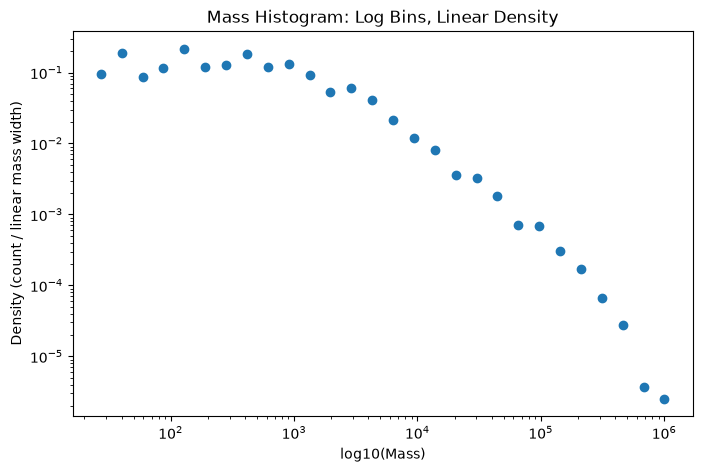

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

# Load CSV
df = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
#df = df[df['final_distance'] > 10 ]

col_name = "M_Sol_X 13CO 1-0"

# Extract values and drop missing or non-positive
values = df[col_name]
values = values[values > 0].dropna().values

# Number of bins = ceil(2 * N^0.4)
N = len(values)
num_bins = math.ceil(2 * (N ** 0.4))

# ----- 1. Make log-spaced bins -----
min_log = np.log10(values.min())
max_log = np.log10(values.max())

log_bin_edges = np.linspace(min_log, max_log, num_bins + 1)

# ----- 2. Convert log edges to linear space -----
linear_bin_edges = 10**log_bin_edges

# ----- 3. Histogram using these log bins -----
counts, _ = np.histogram(values, bins=linear_bin_edges)

# ----- 4. Compute linear bin widths -----
linear_bin_widths = linear_bin_edges[1:] - linear_bin_edges[:-1]

# ----- 5. Density = counts per linear-width bin -----
density = counts / linear_bin_widths

# ----- 6. Bin centers in log space (for plotting) -----
bin_centers_log = 0.5 * (log_bin_edges[:-1] + log_bin_edges[1:])
bin_centers_mass = 10 ** bin_centers_log

# Plot
plt.figure(figsize=(8,5))
#plt.bar(bin_centers_mass, density, 
     #   width=np.diff(log_bin_edges),
     #   align='center')
plt.scatter(bin_centers_mass, density)

# Optional: connect points with a line, if plt.scatter
#plt.plot(bin_centers_log, density)

plt.xlabel("log10(Mass)")
plt.ylabel("Density (count / linear mass width)")
plt.title("Mass Histogram: Log Bins, Linear Density")
plt.yscale('log')
plt.xscale('log')
plt.show()

In [14]:
linear_bin_edges

array([2.23200000e+01, 3.29535691e+01, 4.86531235e+01, 7.18321715e+01,
       1.06054051e+02, 1.56579727e+02, 2.31176562e+02, 3.41312402e+02,
       5.03918541e+02, 7.43992584e+02, 1.09844135e+03, 1.62175462e+03,
       2.39438185e+03, 3.53509981e+03, 5.21927222e+03, 7.70580860e+03,
       1.13769667e+04, 1.67971173e+04, 2.47995056e+04, 3.66143469e+04,
       5.40579485e+04, 7.98119328e+04, 1.17835486e+05, 1.73974007e+05,
       2.56857726e+05, 3.79228442e+05, 5.59898328e+05, 8.26641947e+05,
       1.22046606e+06])

In [15]:
log_bin_edges

array([1.34869419, 1.51790246, 1.68711073, 1.856319  , 2.02552726,
       2.19473553, 2.3639438 , 2.53315207, 2.70236034, 2.87156861,
       3.04077688, 3.20998514, 3.37919341, 3.54840168, 3.71760995,
       3.88681822, 4.05602649, 4.22523475, 4.39444302, 4.56365129,
       4.73285956, 4.90206783, 5.0712761 , 5.24048437, 5.40969263,
       5.5789009 , 5.74810917, 5.91731744, 6.08652571])

In [16]:
counts

array([ 1,  3,  2,  4, 11,  9, 14, 30, 29, 47, 49, 41, 69, 70, 54, 44, 44,
       29, 38, 32, 18, 26, 17, 14,  8,  5,  1,  1])

In [17]:
density

array([9.40418019e-02, 1.91088226e-01, 8.62848206e-02, 1.16884286e-01,
       2.17711090e-01, 1.20648551e-01, 1.27115751e-01, 1.84494880e-01,
       1.20796066e-01, 1.32600262e-01, 9.36341640e-02, 5.30656936e-02,
       6.04882209e-02, 4.15634407e-02, 2.17169556e-02, 1.19853188e-02,
       8.11785562e-03, 3.62391811e-03, 3.21629374e-03, 1.83448354e-03,
       6.98920980e-04, 6.83786704e-04, 3.02822372e-04, 1.68911338e-04,
       6.53751179e-05, 2.76747836e-05, 3.74891817e-06, 2.53920458e-06])

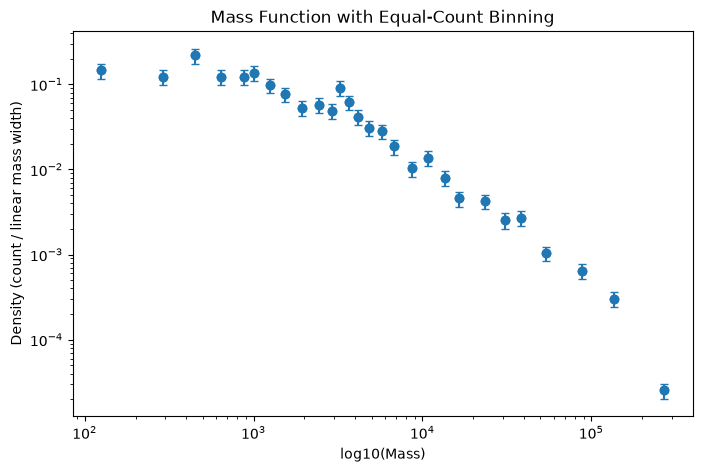

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

# Load CSV
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
#df = pd.read_csv("FGN_13CO_037_047_vrms_3_masses_SNR0_plusleaves.csv")
#df = df[df['final_distance'] > 10 ]
#df = df[df['final_distance'] > 2]
#df = df[np.abs(df['v_cen']) > 10000]

col_name = "M_Sol_X 13CO 1-0" #This is for complete catalogue


# Filter positive masses
values = df_2[col_name]
values = values[values > 0].dropna().values

# Number of bins
N = len(values)
num_bins = math.ceil(2 * (N ** 0.4))   # same rule as before

# ----- 1. Sort values -----
sorted_vals = np.sort(values)

# ----- 2. Compute quantile bin edges (equal-count bins) -----
quantiles = np.linspace(0, 1, num_bins + 1)
bin_edges = np.quantile(sorted_vals, quantiles)

# Remove duplicate edges (can occur if many identical masses)
bin_edges = np.unique(bin_edges)

# Recompute num_bins in case duplicates removed
num_bins_actual = len(bin_edges) - 1

# ----- 3. Count values in each bin -----
counts = np.histogram(sorted_vals, bins=bin_edges)[0]

# ----- 4. Linear bin widths -----
bin_widths = bin_edges[1:] - bin_edges[:-1]

# ----- 5. Density = counts / linear width -----
density = counts / bin_widths
density_err = np.sqrt(counts) / bin_widths

# ----- 6. Show values inside each bin -----
bin_values = []  # list of arrays, one per bin

for i in range(num_bins_actual):
    left = bin_edges[i]
    right = bin_edges[i+1]

    # include left edge, exclude right edge (like numpy histogram)
    mask = (sorted_vals >= left) & (sorted_vals < right)
    vals_in_bin = sorted_vals[mask]

    # for the LAST bin, include the right edge too:
    if i == num_bins_actual - 1:
        mask = (sorted_vals >= left) & (sorted_vals <= right)
        vals_in_bin = sorted_vals[mask]

    bin_values.append(vals_in_bin)

# ----- 7. Median of each bin -----
bin_medians = np.array([np.median(vals) for vals in bin_values])
#print(bin_medians)

#bin_centers = 0.5*(bin_edges[:-1] + bin_edges[1:])
#bin_centers_log = np.log10(bin_centers)

bin_medians_log = np.log10(bin_medians)


# ----- 8. Scatter plot -----
plt.figure(figsize=(8,5))
plt.scatter(bin_medians, density)
#plt.plot(bin_centers, density)

plt.xlabel("log10(Mass)")
plt.ylabel("Density (count / linear mass width)")
plt.title("Mass Function with Equal-Count Binning")
plt.yscale('log')
plt.xscale('log')
plt.errorbar(
    bin_medians,
    density,
    yerr=density_err,
    fmt='o',
    capsize=3
)
plt.show()


In [59]:
df_2.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'pixel number 13CO 1-0', 'final_distance', 'distance_cm',
       'Mean_flux 13CO 1-0', 'density 13CO 1-0', 'M_Sol_X 13CO 1-0',
       'pixel number 13CO 1-0 LTE', 'LTE_Density 13O 1-0',
       'Mean_flux 13CO 1-0 LTE', 'M_Sol 13CO 1-0 LTE', 'pixel number 13CO 3-2',
       'Mean_flux 13CO 3-2', 'density 13CO 3-2', 'M_Sol_X 13CO 3-2',
       'pixel number 12CO 1-0', 'Mean_flux 12CO 1-0', 'X_density 12CO 1-0',
       'M_Sol_X 12CO 1-0', 'pixel number 12CO 3-2', 'Mean_flux 12CO 3-2',
       'X_density 12CO 3-2', 'M_Sol_X 12CO 3-2', 'pixel number 13CO 3-2 LTE',
       'LTE_Density 13CO 3-2', 'Mean_flux 13CO 3-2 LTE', 'M_Sol 13CO 3-2 LTE'],
      dtype='str')

DescribeResult(nobs=np.int64(710), minmax=(np.float64(0.3051569445929225), np.float64(2.02519268478348)), mean=np.float64(0.3700783725568089), variance=np.float64(0.007405391975024693), skewness=np.float64(11.011020350701965), kurtosis=np.float64(194.70848108672385))


<ErrorbarContainer object of 3 artists>

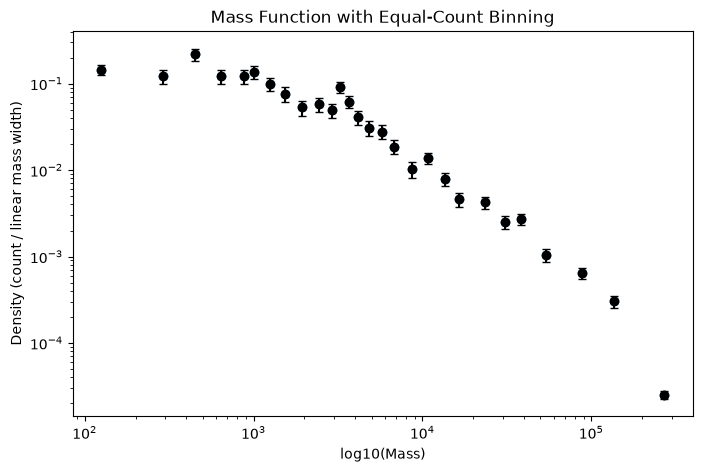

In [90]:
# Number of Monte Carlo realizations
n_mc = 1000

# Number of bins
n_bins = len(bin_edges) - 1

# Store every realization
density_mc = np.zeros((n_mc, n_bins))

W = df_2['Mean_flux 13CO 1-0']
d = df_2['final_distance']

sigma_values = np.sqrt(0.09 + (0.44/W) ** 2 + 4 * (0.3/d) ** 2)
print(stats.describe(sigma_values))
sigma_values = sigma_values * values

for k in range(n_mc):

    # Draw one realization of every cloud mass
    values_mc = np.random.normal(values, sigma_values)

    # Optional: remove any non-physical negative masses
    values_mc = values_mc[values_mc > 0]

    # Histogram using the ORIGINAL bin edges
    counts_mc, _ = np.histogram(values_mc, bins=bin_edges)

    # Density
    density_mc[k] = counts_mc / bin_widths

# Mean histogram
density_mean = density_mc.mean(axis=0)

# 1-sigma uncertainty
density_err = density_mc.std(axis=0)


plt.figure(figsize=(8,5))
plt.scatter(bin_medians, density)
plt.xlabel("log10(Mass)")
plt.ylabel("Density (count / linear mass width)")
plt.title("Mass Function with Equal-Count Binning")
plt.yscale('log')
plt.xscale('log')
plt.errorbar(
    bin_medians,
    density,
    yerr=density_err,
    fmt='o',
    color='k',
    capsize=3
)

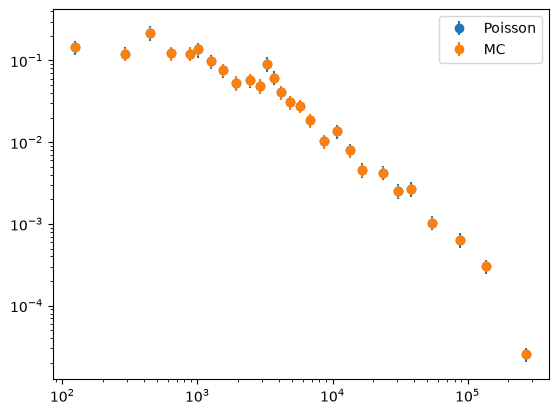

In [84]:
adpoisson_err = np.sqrt(counts) / bin_widths

plt.errorbar(
    bin_medians,
    density,
    yerr=poisson_err,
    fmt='o',
    label='Poisson'
)

plt.errorbar(
    bin_medians,
    density,
    yerr=density_err,
    fmt='o',
    label='MC'
)

plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.show()

In [93]:
poisson_err

array([2.85481103e-02, 2.43220924e-02, 4.38806771e-02, 2.38897950e-02,
       2.43445174e-02, 2.84736699e-02, 1.85525234e-02, 1.52947195e-02,
       1.05930701e-02, 1.12901443e-02, 9.78974831e-03, 1.87151569e-02,
       1.18887356e-02, 8.22873193e-03, 6.28579007e-03, 5.37615402e-03,
       3.73900732e-03, 2.05618033e-03, 2.68220332e-03, 1.58399190e-03,
       9.16685875e-04, 8.29307830e-04, 5.14946454e-04, 5.38435994e-04,
       1.99587959e-04, 1.28620907e-04, 6.04776247e-05, 4.96280683e-06])

Fitted parameters:
A = 2.3174e+04
a = -1.5663
χ^2 = 0.0130


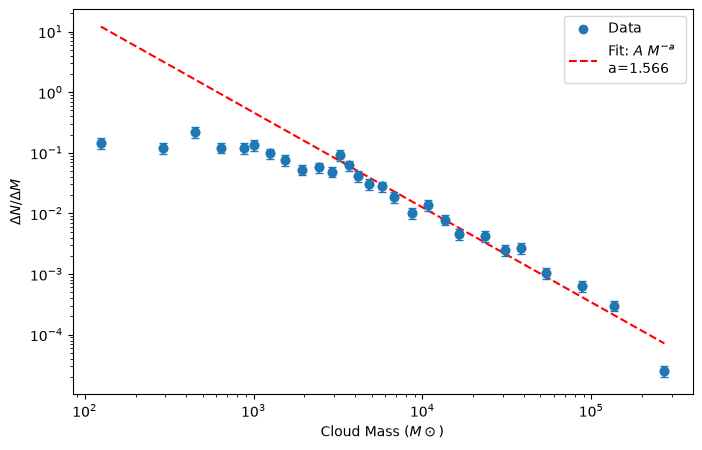

In [12]:
# Select last 17 points (starting from index 11)
#x_log = bin_centers_log[11:]

x_log = bin_medians_log[11:]  # This is for the entire dataset
y = density[11:]              # This is for the entire dataset

#x_log = bin_medians_log[4:]  # This is for the subset d > 10
#y = density[4:]              # This is for the subset d > 10

# Convert density to log10
y_log = np.log10(y)

# --- Linear fit: y_log = B - a * x_log ---
coeffs, cov = np.polyfit(x_log, y_log, 1, cov=True)

slope = coeffs[0]      # this equals (-a)
intercept = coeffs[1]  # this equals log10(A)

# Extract A and a
a = slope
A = 10**intercept

predicted_values = A * (10**x_log)**(a)
linear_x2 = np.sum((y - predicted_values)**2/predicted_values)

print("Fitted parameters:")
print(f"A = {A:.4e}")
print(f"a = {a:.4f}")
print(f"χ^2 = {linear_x2:.4f}")

# --- Plot data and fit ---
plt.figure(figsize=(8,5))


# Data points
#plt.scatter(bin_centers, density, label="Data")
plt.scatter(bin_medians, density, label="Data")

# Fit line in log-log space
#fit_y = A * (10**bin_centers_log)**(a)
#plt.plot(bin_centers, fit_y, label=f"Fit: $A*M^a$ \na={a:.3f}", linestyle="--")
fit_y = A * (10**bin_medians_log)**(a)
plt.plot(bin_medians, fit_y, label=f"Fit: $A\ M^{{-a}}$ \na={-a:.3f}", linestyle="--",color='red')

plt.xlabel(f"Cloud Mass $(M\odot)$")
#plt.ylabel("Density (count / linear mass width)")
plt.ylabel(f"$\Delta N /\Delta M$")
plt.yscale("log")
plt.xscale("log")
#plt.title("Power-law Fit to High-Mass Tail")
plt.legend()
plt.grid(True, which="both", ls="", alpha=0.6)
plt.errorbar(
    bin_medians,
    density,
    yerr=density_err,
    fmt='o',
    capsize=3
)
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/Power_law_completeness.png")
#plt.show()

In [9]:
m_err = np.sqrt(cov[0, 0])
b_err = np.sqrt(cov[1, 1])

m_err

np.float64(0.07310501526748275)


Fitted parameters:
A        = 1.6165e-01
mu       = 2.4582   (log10 of the peak)
M_peak   = 287.2205
sigma    = 0.6920   (width in dex)
χ^2 = 0.1027


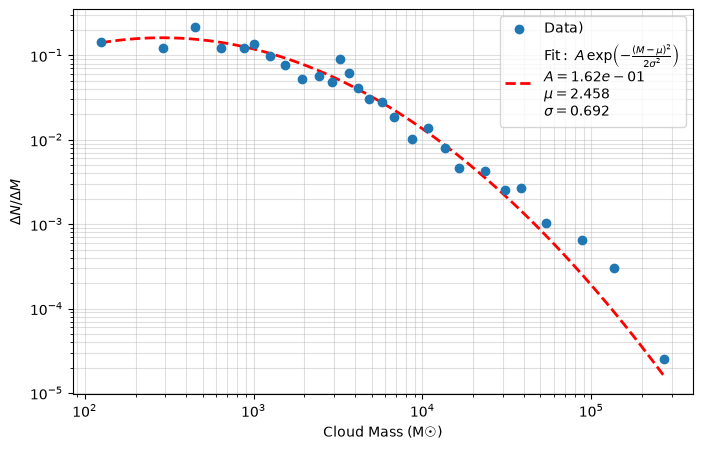

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ----------------------------
# Your x and y data
# ----------------------------
M = bin_medians         # linear mass values (bin centers)
dndm = density           # dN/dM values

# Keep valid data
valid = (M > 0) & (dndm > 0) & np.isfinite(dndm)
M = M[valid][0:]       # Testing the [4:], remove later, not part of the original code and not correct conceptually unless [0:]
dndm = dndm[valid][0:] # Testing the [4:], remove later, not part of the original code and not correct conceptually unless [0:]

# ----------------------------
# Model: dn/dm = A * exp( - (log10(M)-mu)^2 / (2*sigma^2) )
# ----------------------------
def lognormal_base10(M, A, mu, sigma):
    return A * np.exp(-(np.log10(M) - mu)**2 / (2 * sigma**2))


# ----------------------------
# Fit
# ----------------------------
p0 = [max(dndm), np.log10(np.median(M)), 0.5]  # reasonable guesses

params, cov = curve_fit(lognormal_base10, M, dndm, p0=p0, maxfev = 10000)

A_fit, mu_fit, sigma_fit = params
M_peak_fit = 10**mu_fit
dndm_calc = lognormal_base10(M, *params)
x2 = np.sum((dndm - dndm_calc)**2 / dndm_calc)

print("\nFitted parameters:")
print(f"A        = {A_fit:.4e}")
print(f"mu       = {mu_fit:.4f}   (log10 of the peak)")
print(f"M_peak   = {M_peak_fit:.4f}")
print(f"sigma    = {sigma_fit:.4f}   (width in dex)")
print(f"χ^2 = {x2:.4f}")

# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(8,5))

# data
plt.scatter(M, dndm, label="Data)", zorder=5)

# smooth model curve
M_smooth = np.logspace(np.log10(M.min()), np.log10(M.max()), 500)
fit_curve = lognormal_base10(M_smooth, *params)

label = (
    r"$\mathrm{Fit:}\ A\,\exp\!\left(-\frac{(M-\mu)^2}{2\sigma^2}\right)$" "\n"
    rf"$A = {A_fit:.2e}$" "\n"
    rf"$\mu = {mu_fit:.3f}$" "\n"
    rf"$\sigma = {sigma_fit:.3f}$"
)
plt.plot(
    M_smooth, fit_curve, 'r--', lw=2,
    label=label
)


plt.xscale("log") 
plt.yscale("log")

plt.xlabel("Cloud Mass (M☉)")
plt.ylabel(f"$\Delta N /\Delta M$")
#plt.title("Fit:  dn/dM = A exp[-(log10 M − μ)² / (2σ²)]")

plt.grid(True, which='both', alpha=0.4)
plt.legend()
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/Lognormal_completeness.png")
plt.show()

In [87]:
# This is just something to use when you use big distance code with clusters AND leaves, makes sure you have no rows with NaNs

df["density"] = df["density"].replace("nan", np.nan)
df_nonan = df[df["density"].notna()]
csv_output        = mult_path +f"{dataset}_{isotopologue}_{region}_vrms_3_masses_SNR{SNR_lim}_plusleaves.csv"
df_nonan.to_csv(csv_output, index= False)

KeyError: 'density'

Weighted fit: log(M) = 0.1119 * d + 3.0436


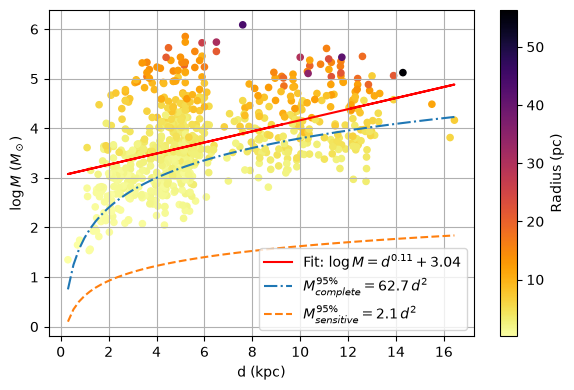

In [24]:
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

df['semi_major_deg']= df['major_arcsec'] / 3600  # Divide by 3600, those are semis!
df['semi_minor_deg']= df['minor_arcsec'] / 3600
df['semi_major_cm'] = df['semi_major_deg'] * df['distance_cm'] * np.pi / 180 * 2.354
df['semi_minor_cm'] = df['semi_minor_deg'] * df['distance_cm'] * np.pi / 180 * 2.354

rad_pc= (df['semi_major_cm']/3.086E18*df['semi_minor_cm']/3.086E18)**(1/2) / 2
df['radius(pc)']=rad_pc

# Extract and filter data
R = df['radius(pc)'].values
M = df['M_Sol_X 13CO 1-0'].values
d = df['final_distance'].values
mask = (R > 0) & (M > 0) & (d > 0)
R = R[mask]
M = M[mask]
d = d[mask]

logR = np.log10(R)
logM = np.log10(M)

# Define weights (e.g., directly or 1/W if you want inverse-distance weight)
weights = R  # or 1/W, or 1/W**2 depending on purpose

# Weighted polyfit
fit = np.polyfit(d, logM, 1)
a_fit, c_fit = fit

# Completeness limit
d_model = np.linspace(d.min(),d.max(), int(len(d)/10))
M_complete = 62.7 * d_model ** 2
log_M_complete = np.log10(M_complete)

# Sensitivity
M_sens = 2.1 * d_model *2
log_M_sens = np.log10(M_sens)

print(f"Weighted fit: log(M) = {a_fit:.4f} * d + {c_fit:.4f}")

# Plot
plt.figure(figsize=(6, 4))
plt.scatter(d, logM, c=R, cmap='inferno_r', s=20)#, edgecolor='k')
plt.plot(d, a_fit * d + c_fit, color='red', label=fr'Fit: $\log M = d^{{{a_fit:.2f}}} + {c_fit:.2f}$')
plt.xlabel(r'd (kpc)')
plt.ylabel(r'$\log M$ ($M_\odot$)')
plt.grid(True)
plt.colorbar(label='Radius (pc)')
plt.plot(d_model, log_M_complete, linestyle = '-.', label=r'$M^{95\%}_{complete} = 62.7\, d^2$')
plt.plot(d_model, log_M_sens, linestyle = '--', label=r'$M^{95\%}_{sensitive} = 2.1\, d^2$')
plt.legend()
plt.tight_layout()
#plt.show()
#plt.savefig('/Users/kyriakos.trakakis/CHIMPS_FGN paper/FUGIN_13CO_Mass_distance_completeness.png')
#plt.savefig('/Users/kyriakos.trakakis/CHIMPS_FGN paper/FUGIN_13CO_Mass_distance_sensitivity.png')
#plt.savefig('/Users/kyriakos.trakakis/CHIMPS_FGN paper/FUGIN_13CO_Mass_distance_completeness_sensitivity.png')

In [ ]:
# Saves figure but does so cleverly so no overwriting the wrong stuff
# Loading and plotting moment maps and other plots

from astropy.io import fits
from matplotlib.ticker import MultipleLocator, FuncFormatter

# Load the FITS moment map
#

#
filename = 'FGN_037_047_13CO_23arcsec_aligned_mean_collapsed.fits'
file_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
fits_file = file_path + filename
fits_file = filename
hdu = fits.open(fits_file)[0]
data = hdu.data
header = hdu.header

destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
destination_name = filename.replace("fits", "png")

# This is for the colourbar
#vmax_99 = np.nanpercentile(data, 99.9) # It's a good idea to run this for one of the cubes then comment it out 
                                        # for the next ones so they are at the same scale. Usually run 17-27 first
name_parts = filename.split("_")
l1 = name_parts[1][1:3]
l1 = float(l1)

l2 = name_parts[2][1:3]
l2 = float(l2)
bmin, bmax = -0.5, 0.5

# Plot the moment map
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
img=ax.imshow(data, origin="lower", cmap="gray_r", extent=[l2, l1, bmin, bmax],vmin=0, vmax=vmax_99) # To remove the colourbar, remove img= and the next 2 lines
# cmap= gray_r for Michael

cbar = plt.colorbar(img, ax=ax, pad=0.02, fraction=0.01)  # pad adjusts spacing
cbar.set_label("Mean Intensity (K)", fontsize="x-small")  # Label for the colorbar

# Adjust axis limits and ticks
plt.xlim(l2, l1)
plt.ylim(bmin, bmax)
ax.xaxis.set_major_locator(MultipleLocator(1)) # set to 1 to display every 1 degree instead of 0.5
ax.yaxis.set_major_locator(MultipleLocator(0.5))
plt.xlabel("Galactic Longitude (deg)", fontsize= "x-small")
plt.ylabel("Galactic Latitude (deg)", fontsize= "x-small")
#plt.title("MST over Moment Map", fontsize="xx-large")
plt.tight_layout()
#plt.savefig(destination_path+destination_name,dpi=300,bbox_inches="tight",pad_inches=0.02)
plt.show()

In [ ]:
# Saves figure but does so cleverly so no overwriting the wrong stuff
# Copied and pasted from above to get the lv plot of ratio for 17-47

from astropy.io import fits
from matplotlib.ticker import MultipleLocator, FuncFormatter

# Load the FITS moment map
#

#
filename = 'FGN_017_047_12_13_ratio_23arcsec_aligned_threshed_lvmean_starlink.fits'
file_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
fits_file = file_path + filename
fits_file = filename
hdu = fits.open(fits_file)[0]
data = hdu.data
header = hdu.header

destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
destination_name = filename.replace("fits", "png")

# This is for the colourbar
vmin = np.nanpercentile(data, 1)
vmax = np.nanpercentile(data, 99.95)

name_parts = filename.split("_")
l1 = name_parts[1][1:3]
l1 = float(l1)

l2 = name_parts[2][1:3]
l2 = float(l2)
v1, v2 = 171, -66


fig, ax = plt.subplots(figsize=(12,9), dpi=450)

img = ax.imshow(
    data,
    origin='lower',
    cmap='gray_r',
    aspect='auto',
    vmin=vmin,
    vmax=vmax,
    extent=[
        l2,
        l1,
        v1,
        v2
    ],
)

cbar = plt.colorbar(img, ax=ax, pad=0.02, fraction=0.05)  # pad adjusts spacing
cbar.set_label("12CO/13CO Ratio", fontsize=12)  # Label for the colorbar

# Adjust axis limits and ticks
plt.xlim(l2, l1)
plt.ylim(v1, v2)
#ax.xaxis.set_major_locator(MultipleLocator(1)) # set to 1 to display every 1 degree instead of 0.5
#ax.yaxis.set_major_locator(MultipleLocator(0.5))
ax.set_ylabel("Velocity (km s$^{-1}$)")
ax.set_xlabel("Galactic Longitude (deg)")
#ax.invert_xaxis()
ax.invert_yaxis()
#plt.title("MST over Moment Map", fontsize="xx-large")
plt.tight_layout()
plt.savefig(destination_path+destination_name,dpi=300,bbox_inches="tight",pad_inches=0.02)
plt.show()

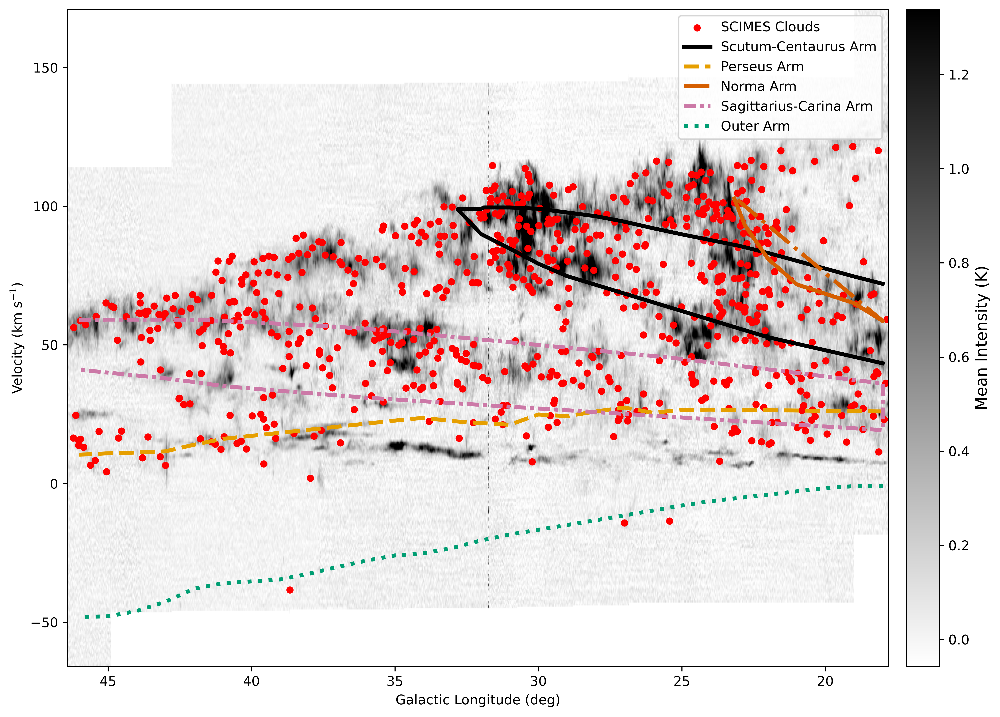

In [120]:
# Saves figure
# Overplots sources on the lv plot along with spiral arm locations from Reid 2019.

from astropy.io import fits
from matplotlib.ticker import MultipleLocator, FuncFormatter

# Load the FITS moment map
#

#
filename = 'FGN_017_047_13CO_23arcsec_aligned_lv.fits'
file_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
fits_file = file_path + filename
hdu = fits.open(fits_file)[0]
data = hdu.data
header = hdu.header

df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X_FUGIN_Master_mass_catalogue_complete_redist_272.csv')
l = df_2['x_cen']
v = df_2['v_cen'] / 1000
match = df_2['has_match']

arms_path = "/Users/kyriakos.trakakis/Downloads/Spiral_arms/"
nor = pd.read_csv(arms_path + "Norma_Arm.csv")
out = pd.read_csv(arms_path + "Outer_Arm.csv")
per = pd.read_csv(arms_path + "Perseus_Arm.csv")
sag = pd.read_csv(arms_path + "Sagittarius_Arm.csv")
sct = pd.read_csv(arms_path + "Scutum_Arm.csv")

nor = nor[(nor['l'] > l.min()) & (nor['l'] < l.max())] 
per = per[(per['l'] > l.min()) & (per['l'] < l.max())] 
sag = sag[(sag['l'] > l.min()) & (sag['l'] < l.max())] 
sct = sct[(sct['l'] > l.min()) & (sct['l'] < l.max())] 
out = out[(out['l'] > l.min()) & (out['l'] < l.max())] 

destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
destination_name = filename.replace("fits", "png")

l_axis = np.linspace(46.412615, 17.795012, np.shape(data)[1])
v_axis = np.linspace(171, -66, np.shape(data)[0])

# This is for the colourbar
vmin = np.nanpercentile(data, 5)
vmax = np.nanpercentile(data, 99.5)

name_parts = filename.split("_")
l1 = name_parts[1][1:3]
l1 = float(l1)

l2 = name_parts[2][1:3]
l2 = float(l2)
bmin, bmax = -0.5, 0.5

colors = [
    '#000000',  # black
    '#E69F00',  # orange
    '#D55E00',  # vermillion
    '#CC79A7',   # reddish purple
    '#009E73'  # bluish green
]

styles = [
    '-',                  # solid
    '--',                 # dashed
    '-.',                 # dash-dot
    (0, (3, 1, 1, 1)),     # dash-dot-dot
    ':'                  # dotted
]


fig, ax = plt.subplots(figsize=(12,9), dpi=450)

img = ax.imshow(
    data,
    origin='lower',
    cmap='gray_r',
    aspect='auto',
    vmin=vmin,
    vmax=vmax,
    extent=[
        l_axis[0],
        l_axis[-1],
        v_axis[0],
        v_axis[-1]
    ]
)
ax.scatter(
    l[~match],
    v[~match],
    s=16,
    color='blue',
    alpha=0.35,
    label = "No match"
)

#ax.scatter(
#    l,
#    v,
#    s=20,
#    color='red',
#    label = "SCIMES Clouds"
#)

#ax.scatter(
    l[match],
    v[match],
    s=28,
    color='red',
    edgecolor='black',
    linewidth=0.4,
    label='ATLASGAL match'
)

ax.plot(
    sct['l'],
    sct['v'],
    color=colors[0],
    linestyle = styles[0],
    linewidth=3,
    label='Scutum-Centaurus Arm'
)

ax.plot(
    per['l'],
    per['v'],
    color=colors[1],
    linestyle = styles[1],
    linewidth=3,
    label='Perseus Arm'
)

ax.plot(
    nor['l'],
    nor['v'],
    color=colors[2],
    linestyle = styles[2],
    linewidth=3,
    label='Norma Arm'
)

ax.plot(
    sag['l'],
    sag['v'],
    color=colors[3],
    linestyle = styles[3],
    linewidth=3,
    label='Sagittarius-Carina Arm'
)

ax.plot(
    out['l'],
    out['v'],
    color=colors[4],
    linestyle = styles[4],
    linewidth=3,
    label='Outer Arm'
)

cbar = plt.colorbar(
    img,
    ax=ax,
    pad=0.02,
    fraction=0.05
)

cbar.set_label(
    "Mean Intensity (K)",
    fontsize=12
)

ax.legend()
ax.set_ylabel("Velocity (km s$^{-1}$)")
ax.set_xlabel("Galactic Longitude (deg)")
ax.invert_yaxis()


plt.savefig(destination_path + "FGN_017_047_lv_plot_clouds_arms.png")

In [ ]:
## Using pvextractor to extract pv slice. Looks to be doing ok but you have to decide a "path" and a "width"
## Saves non-descriptive plot. Has issues, use the one below preferably.


from spectral_cube import SpectralCube
from pvextractor import Path, extract_pv_slice
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

filename = 'FGN_037_047_13CO_23arcsec_aligned.fits'
file_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
fits_file = file_path + filename
destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"


def extract_and_plot_pv_slice(fits_file, save_fits='Yes', show=True):
    """
    Extract and plot a PV slice using pvextractor and spectralcube.

    Parameters:
        fits_file (str): Path to the FITS file.
        save_fits (str): Path to save the extracted PV slice as a FITS file.
        show (bool): Whether to display the plot.

    Returns:
        None
    """
    # Load the spectral cube
    cube = SpectralCube.read(fits_file)

    # Define the PV slice path (straight line in this example)
    # Modify the coordinates as needed for your data
    path = Path(
    SkyCoord(
        l=[37, 47] * u.deg,
        b=[0, 0] * u.deg,
        frame="galactic"
    )
)

    # Extract the PV slice
    pv_slice = extract_pv_slice(cube, path)

    # Save the PV slice as a FITS file
    if save_fits:
        hdu = pv_slice  # `pv_slice` is already a PrimaryHDU object
        hdu.writeto(save_fits, overwrite=True)
        print(f"Saved PV FITS to: {save_fits}")

    # Plot the PV slice
    if show:
        # Create the WCS object from the PV slice header
        pv_wcs = WCS(pv_slice.header)

        # Plot the PV slice
        fig, ax = plt.subplots(figsize=(8, 6), dpi=200, subplot_kw={"projection": pv_wcs})
        im = ax.imshow(pv_slice.data, origin="lower", aspect="auto", cmap="inferno", vmax=1, vmin=-0.1)

        # Set axis labels
        ax.coords[0].set_axislabel("Galactic Longitude (deg)")
        ax.coords[1].set_axislabel("Velocity (km s$^{-1}$)")

        # Add a colorbar
        plt.colorbar(im, ax=ax, label="Intensity")

        # Display the plot
        plt.tight_layout()
        plt.show()

# Call the function
extract_and_plot_pv_slice(
    fits_file,
    save_fits=destination_path + "pv_slice.fits"
)

In [161]:
%history

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

# Load CSV
df = pd.read_csv("CHIMPS_X_FUGIN_Master_mass_catalogue_complete.csv")
#df = pd.read_csv("FGN_13CO_037_047_vrms_3_masses_SNR0_plusleaves.csv")
df = df[df['final_distance'] > 10 ]
#df = df[df['final_distance'] > 2]

col_name = "M_Sol_X 13CO 1-0" #This is for complete catalogue


# Filter positive masses
values = df[col_name]
values = values[values > 0].dropna().values

# Number of bins
N = len(values)
num_bins = math.ceil(2 * (N ** 0.4))   # same rule as before

# ----- 1. Sort values -----
sorted_vals = np.sort(values)

# ----- 2. Compute quantile bin edges (equal-count bins) -----
quantiles = np.linspace(0, 1, num_bins + 1)
bin_edges = np.quantile(sorted_vals, quantiles)

# Remove duplicate edges (can occur if many identical masses)
bin_edges = np.unique(bin_edges)

# Recompute num_bins in case duplicates removed
num_bins_actual = len(bin_edges) - 1

# ----- 3. Count values in each bin -----


Cube shape (v,b,l): 427, 608, 5715


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_32237/2005435935.py:59: RuntimeWarning: Mean of empty slice
  pv = np.nanmean(data, axis=1) if method == "average" else np.nansum(data, axis=1)


PV shape (velocity, position): (427, 5715)
lv
Saved PV FITS to: /Users/kyriakos.trakakis/CHIMPS_FGN paper/FGN_037_047_12_13_ratio_23arcsec_aligned_threshed_lv.fits


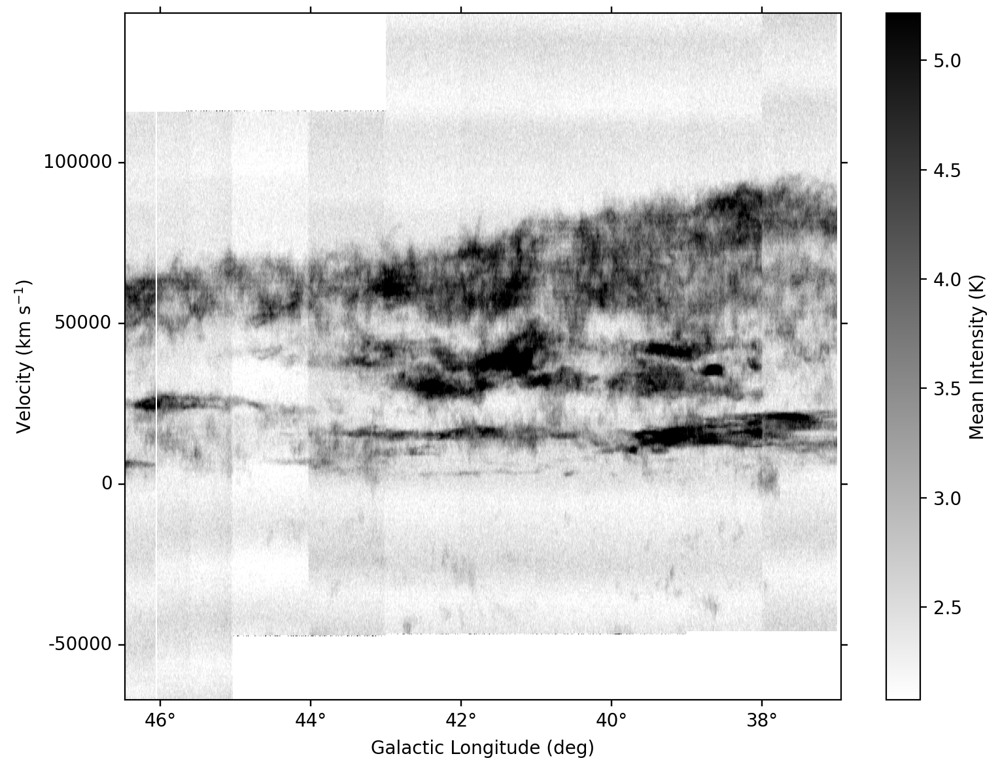

In [21]:
## Creates pv plot by averaging over a positional coordinate. Saves a plot with clever naming so it doesn't overwrite 
## wrong stuff. Specify "type" bv or lv. Good code, works well. Will try to expand below

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from mpl_toolkits.axes_grid1 import make_axes_locatable


#filename = 'FGN_037_047_13CO_23arcsec_aligned.fits'
filename = 'FGN_037_047_12_13_ratio_23arcsec_aligned_threshed.fits'
file_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
fits_file = file_path + filename
destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
type = "lv"


def make_pv_plot(
    fits_file,
    pv_type=type,            # "lv" or "bv"
    method="average",        # "average" or "integrate"
    show=True,
    save_fits=None,
    vmin=None,
    vmax=None
):
    """
    Create LV or BV PV diagrams from a (v, b, l) FITS cube.

    Assumed FITS axis order:
      AXIS1 = longitude
      AXIS2 = latitude
      AXIS3 = velocity

    NumPy data order:
      data[v, b, l]
    """

    # ------------------
    # Read cube
    # ------------------
    hdu = fits.open(fits_file)[0]
    data = hdu.data
    header = hdu.header

    if data.ndim != 3:
        raise ValueError("Input FITS file must be 3D")

    nv, nb, nl = data.shape
    print(f"Cube shape (v,b,l): {nv}, {nb}, {nl}")

    # ------------------
    # Collapse cube
    # ------------------
    with np.errstate(invalid="ignore"):
        if pv_type == "lv":
            # collapse latitude (b)
            pv = np.nanmean(data, axis=1) if method == "average" else np.nansum(data, axis=1)
            xlabel = "Galactic Longitude (deg)"
            x_axis = 1   # FITS axis
        elif pv_type == "bv":
            # collapse longitude (l)
            pv = np.nanmean(data, axis=2) if method == "average" else np.nansum(data, axis=2)
            xlabel = "Galactic Latitude (deg)"
            x_axis = 2   # FITS axis
        else:
            raise ValueError("pv_type must be 'lv' or 'bv'")

    cbar_label = "Mean Intensity (K)" if method == "average" else "Integrated Intensity (K)"
    print("PV shape (velocity, position):", pv.shape)
    print(pv_type)

    vmin = np.nanpercentile(pv, 5)
    vmax = np.nanpercentile(pv, 99)

    # ------------------
    # Build linear PV WCS
    # ------------------
    new_header = fits.Header()
    new_header["NAXIS"]  = 2
    new_header["NAXIS1"] = pv.shape[1]   # X axis
    new_header["NAXIS2"] = pv.shape[0]   # Y axis

    # X axis: longitude or latitude (LINEAR — NOT celestial)
    new_header["CTYPE1"] = header[f"CTYPE{x_axis}"].split("-")[0]
    new_header["CRVAL1"] = header[f"CRVAL{x_axis}"]
    new_header["CRPIX1"] = header[f"CRPIX{x_axis}"]
    new_header["CDELT1"] = header[f"CDELT{x_axis}"]
    new_header["CUNIT1"] = header.get(f"CUNIT{x_axis}", "deg")

    # Y axis: velocity (spectral, linear)
    new_header["CTYPE2"] = header.get("CTYPE3", "VELO-LSR")
    new_header["CRVAL2"] = header["CRVAL3"]
    new_header["CRPIX2"] = header["CRPIX3"]
    new_header["CDELT2"] = header["CDELT3"]
    new_header["CUNIT2"] = "km/s"

    # Spectral metadata
    for key in ["SPECSYS", "RESTFRQ"]:
        if key in header:
            new_header[key] = header[key]

    new_header["BTYPE"] = f"{pv_type.upper()} PV map ({method})"

    # ------------------
    # Save FITS
    # ------------------
    if save_fits:
        fits.writeto(save_fits, pv, new_header, overwrite=True)
        print(f"Saved PV FITS to: {save_fits}")

    # ------------------
    # Plot
    # ------------------
    if show:
        pv_wcs = WCS(new_header)

        fig, ax = plt.subplots(
            figsize=(8, 6),
            dpi=200,
            subplot_kw={"projection": pv_wcs}
        )

        im = ax.imshow(
            pv,
            origin="lower",
            aspect="auto",
            cmap="gray_r",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_xlabel(xlabel)
        ax.set_ylabel("Velocity (km s$^{-1}$)")
        ax.invert_yaxis()

        divider = make_axes_locatable(ax)
        plt.colorbar(im, ax=ax, label=cbar_label)

        plt.tight_layout()
     
        plt.savefig(f"{type}_plot")
        plt.show()

    return pv, new_header


# ------------------
# Example call
# ------------------
pv_name = filename.replace(".fits", "_"+type+".fits")
pv, hdr = make_pv_plot(
    fits_file,
    pv_type=type,
    method="average",
    save_fits=destination_path + pv_name
)


Cube shape (v,b,l): 438, 607, 5590


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91228/2069536605.py:65: RuntimeWarning: Mean of empty slice
  pv = np.nanmean(data, axis=1) if method == "average" else np.nansum(data, axis=1)


PV shape (velocity, position): (438, 5590)
lv


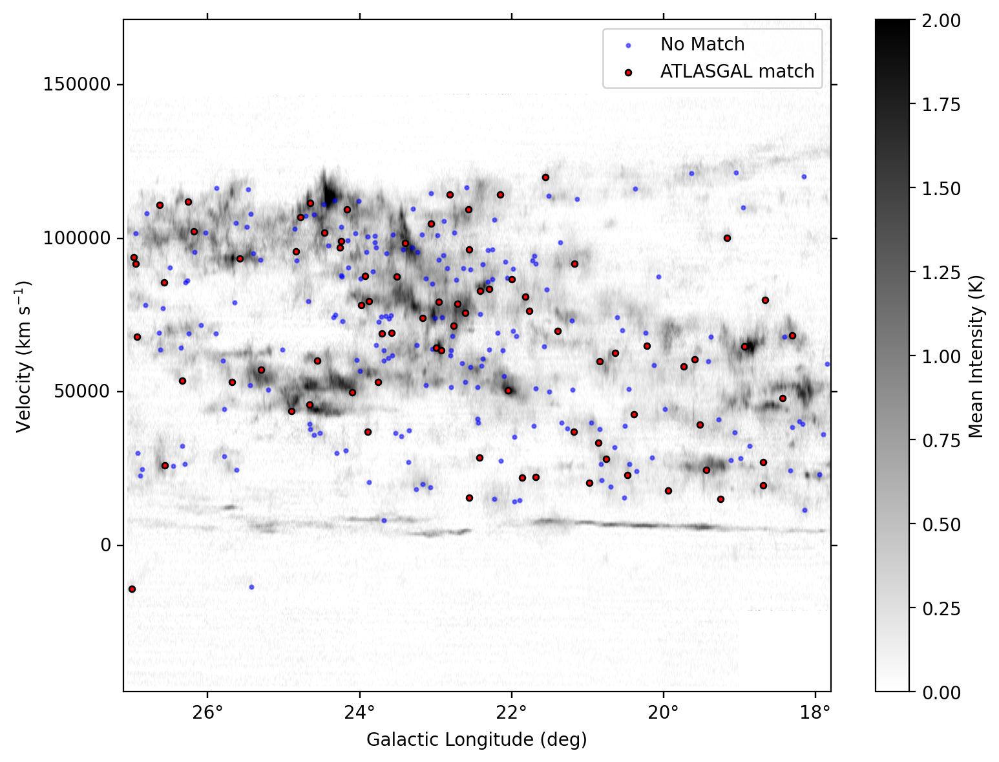

In [352]:
## Creates pv plot by averaging over a positional coordinate. Saves a plot with clever naming so it doesn't overwrite 
## wrong stuff. Specify "type" bv or lv. Same code as above but also plots clouds from the catalogue. Works!

l_bounds = [17,27]
region = f"0{l_bounds[0]}_0{l_bounds[1]}"
filename = f'FGN_{region}_13CO_23arcsec_aligned.fits'
file_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
fits_file = file_path + filename
destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
type = "lv"
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X_FUGIN_Master_mass_catalogue_complete_redist_272.csv')
l = df_2['x_cen']
v = df_2['v_cen']
match = df_2['has_match']


mask = (l < l_bounds[1]) & (l > l_bounds[0])

l = l[mask]
v = v[mask]
match = match[mask]



def make_pv_plot_with_points(
    fits_file,
    pv_type=type,            # "lv" or "bv"
    method="average",        # "average" or "integrate"
    show=True,
    save_fits=None,
    vmin=None,
    vmax=None
):
    """
    Create LV or BV PV diagrams from a (v, b, l) FITS cube.

    Assumed FITS axis order:
      AXIS1 = longitude
      AXIS2 = latitude
      AXIS3 = velocity

    NumPy data order:
      data[v, b, l]
    """

    # ------------------
    # Read cube
    # ------------------
    hdu = fits.open(fits_file)[0]
    data = hdu.data
    header = hdu.header

    if data.ndim != 3:
        raise ValueError("Input FITS file must be 3D")

    nv, nb, nl = data.shape
    print(f"Cube shape (v,b,l): {nv}, {nb}, {nl}")

    # ------------------
    # Collapse cube
    # ------------------
    with np.errstate(invalid="ignore"):
        if pv_type == "lv":
            # collapse latitude (b)
            pv = np.nanmean(data, axis=1) if method == "average" else np.nansum(data, axis=1)
            xlabel = "Galactic Longitude (deg)"
            x_axis = 1   # FITS axis
        elif pv_type == "bv":
            # collapse longitude (l)
            pv = np.nanmean(data, axis=2) if method == "average" else np.nansum(data, axis=2)
            xlabel = "Galactic Latitude (deg)"
            x_axis = 2   # FITS axis
        else:
            raise ValueError("pv_type must be 'lv' or 'bv'")

    cbar_label = "Mean Intensity (K)" if method == "average" else "Integrated Intensity (K)"
    print("PV shape (velocity, position):", pv.shape)
    print(pv_type)

    #vmin = np.nanpercentile(pv, 5)
    #vmax = np.nanpercentile(pv, 99)
    vmin = 0
    vmax = 2

    # ------------------
    # Build linear PV WCS
    # ------------------
    new_header = fits.Header()
    new_header["NAXIS"]  = 2
    new_header["NAXIS1"] = pv.shape[1]   # X axis
    new_header["NAXIS2"] = pv.shape[0]   # Y axis

    # X axis: longitude or latitude (LINEAR — NOT celestial)
    new_header["CTYPE1"] = header[f"CTYPE{x_axis}"].split("-")[0]
    new_header["CRVAL1"] = header[f"CRVAL{x_axis}"]
    new_header["CRPIX1"] = header[f"CRPIX{x_axis}"]
    new_header["CDELT1"] = header[f"CDELT{x_axis}"]
    new_header["CUNIT1"] = header.get(f"CUNIT{x_axis}", "deg")

    # Y axis: velocity (spectral, linear)
    new_header["CTYPE2"] = header.get("CTYPE3", "VELO-LSR")
    new_header["CRVAL2"] = header["CRVAL3"]
    new_header["CRPIX2"] = header["CRPIX3"]
    new_header["CDELT2"] = header["CDELT3"]
    new_header["CUNIT2"] = "km/s"

    # Spectral metadata
    for key in ["SPECSYS", "RESTFRQ"]:
        if key in header:
            new_header[key] = header[key]

    new_header["BTYPE"] = f"{pv_type.upper()} PV map ({method})"

    # ------------------
    # Save FITS
    # ------------------
    if save_fits:
        fits.writeto(save_fits, pv, new_header, overwrite=True)
        print(f"Saved PV FITS to: {save_fits}")

    # ------------------
    # Plot
    # ------------------
    if show:
        pv_wcs = WCS(new_header)

        fig, ax = plt.subplots(
            figsize=(8, 6),
            dpi=200,
            subplot_kw={"projection": pv_wcs}
        )

        im = ax.imshow(
            pv,
            origin="lower",
            aspect="auto",
            cmap="gray_r",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_xlabel(xlabel)
        ax.set_ylabel("Velocity (km s$^{-1}$)")
        ax.invert_yaxis()

        ax.scatter(
            l[~match],
            v[~match],
            s=4,
            color='blue',
            alpha=0.5,
            label = 'No Match',
            transform=ax.get_transform('world')
)

        ax.scatter(
            l[match],
            v[match],
            s=10,
            color='red',
            edgecolor='black',
            label = 'ATLASGAL match',
            transform=ax.get_transform('world')
)
        ax.legend()
        
        divider = make_axes_locatable(ax)
        plt.colorbar(im, ax=ax, label=cbar_label)

        plt.tight_layout()
        plt.savefig(f"{type}_plot")
        plt.show()

    return pv, new_header


# ------------------
# Example call
# ------------------
pv_name = filename.replace(".fits", "_"+type+".fits")
pv, hdr = make_pv_plot_with_points(
    fits_file,
    pv_type=type,
    method="average",
    save_fits = None
    #save_fits=destination_path + pv_name
)


Cube shape (v,b,l): 427, 608, 5715


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_4257/1601165411.py:63: RuntimeWarning: Mean of empty slice
  pv = np.nanmean(data, axis=2) if method == "average" else np.nansum(data, axis=2)


PV shape (velocity, position): (427, 608)
bv
Saved PV FITS to: /Users/kyriakos.trakakis/CHIMPS_FGN paper/FGN_037_047_13CO_23arcsec_aligned_bv.fits


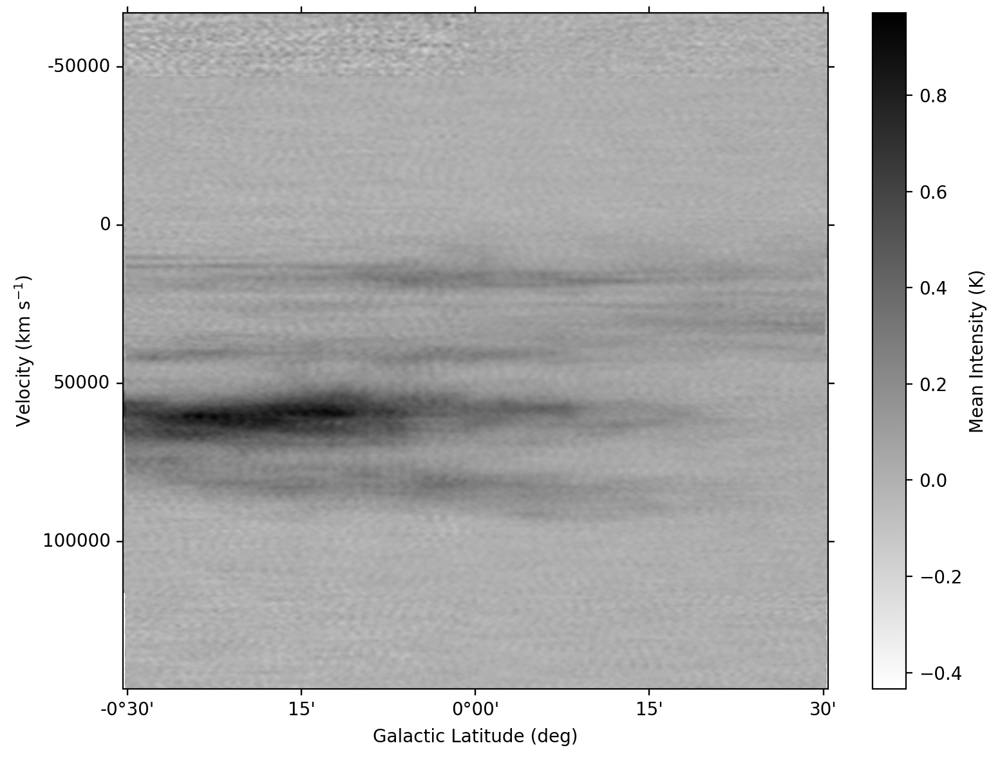

In [264]:
type = "bv"
pv_name = filename.replace(".fits", "_"+type+".fits")
pv, hdr = make_pv_plot(
    fits_file,
    pv_type=type,
    method="average",
    save_fits=destination_path + pv_name
)

In [275]:
df
df_Massive = df[df['M_Sol_X 13CO 1-0']>10**6]

In [284]:
df_Massive.sort_values('sigv_kms')

,Universal_ID,_idx,position_angle,v_cen,v_rms,x_cen,y_cen,sigv_kms,major_arcsec,minor_arcsec,...,M_Sol_X 12CO 3_2,pixel number 13CO 3-2 COLTE,COLTE_Density 13CO 3-2,Mean_flux 13CO 3-2 COLTE,M_Sol 13CO 3-2 COLTE,semi_major_deg,semi_minor_deg,semi_major_cm,semi_minor_cm,radius(pc)
467,468,12830,-177.8,45944.38,3.54,28.150,-0.364,1.77,835.2,254.4,...,369000.0,29646,7.060000e+19,1.81,145080.002993,0.116000,0.035333,1.749073e+20,5.327635e+19,31.280614
664,665,10115,-165.4,18006.90,3.96,38.524,-0.087,1.98,831.4,672.7,...,206000.0,10751,1.730000e+19,0.74,33852.001391,0.115472,0.093431,1.707906e+20,1.381896e+20,49.782148
243,244,16041,172.0,24592.14,5.43,19.434,0.086,2.71,618.4,439.5,...,1210000.0,39243,9.730000e+19,2.43,279929.999113,0.085889,0.061042,1.535006e+20,1.090936e+20,41.933281
381,382,7400,175.9,77779.60,6.33,28.384,-0.033,3.17,1083.3,510.9,...,224000.0,98603,2.390000e+20,1.59,70122.002140,0.150458,0.070958,8.592408e+19,4.052304e+19,19.121085
575,576,2399,-176.3,63715.22,6.69,38.319,-0.243,3.35,746.8,248.7,...,316000.0,21378,4.540000e+19,1.77,60542.999357,0.103722,0.034542,1.261384e+20,4.200673e+19,23.587785
544,545,425,-175.8,81939.82,7.07,38.585,-0.105,3.54,1413.0,487.6,...,255000.0,28419,6.350000e+19,1.08,38781.001680,0.196250,0.067722,1.620651e+20,5.592566e+19,30.849945
592,593,3185,50.9,60212.94,7.10,44.370,-0.152,3.55,889.7,376.8,...,511000.0,38277,5.720000e+19,1.58,52916.998453,0.123569,0.052333,1.253984e+20,5.310791e+19,26.444149
33,34,2783,178.6,93466.72,7.60,25.575,-0.174,3.80,681.9,380.8,...,1040000.0,56111,1.280000e+20,3.27,192510.002106,0.094708,0.052889,1.225695e+20,6.844769e+19,29.680744
579,580,2581,178.4,60269.68,7.79,45.415,0.128,3.90,898.7,373.0,...,694000.0,35721,9.250000e+19,4.72,94859.998226,0.124819,0.051806,1.328207e+20,5.512644e+19,27.727899
113,114,8069,-174.8,69874.28,8.36,21.395,-0.040,4.18,655.0,322.3,...,521000.0,24323,3.470000e+19,1.43,63984.002173,0.090972,0.044764,1.304422e+20,6.418552e+19,29.650474


In [26]:
df_2.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'pixel number 13CO 1-0', 'final_distance', 'distance_cm',
       'Mean_flux 13CO 1-0', 'density 13CO 1-0', 'M_Sol_X 13CO 1-0',
       'pixel number 13CO 1-0 LTE', 'LTE_Density 13O 1-0',
       'Mean_flux 13CO 1-0 LTE', 'M_Sol 13CO 1-0 LTE', 'pixel number 13CO 3-2',
       'Mean_flux 13CO 3-2', 'density 13CO 3-2', 'M_Sol_X 13CO 3-2',
       'pixel number 12CO 1-0', 'Mean_flux 12CO 1-0', 'X_density 12CO 1-0',
       'M_Sol_X 12CO 1-0', 'pixel number 12CO 3-2', 'Mean_flux 12CO 3-2',
       'X_density 12CO 3-2', 'M_Sol_X 12CO 3-2', 'pixel number 13CO 3-2 LTE',
       'LTE_Density 13CO 3-2', 'Mean_flux 13CO 3-2 LTE', 'M_Sol 13CO 3-2 LTE'],
      dtype='str')

In [31]:
df_2['diameter(pc)'] = df_2['radius(pc)'] * 2

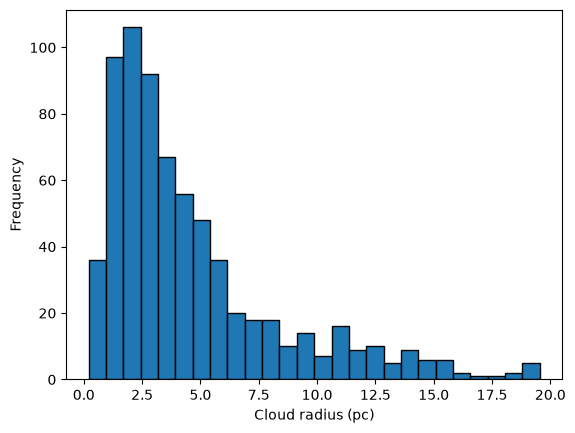

In [9]:
df_smaller = df_2[df_2['radius(pc)']<20]
destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"

plt.hist(df_smaller['radius(pc)'], bins = int(np.round(np.sqrt(len(df_smaller)))), edgecolor='k')
plt.xlabel('Cloud radius (pc)')
plt.ylabel('Frequency')
plt.savefig(destination_path + "radii_histogram<20.png")

In [40]:
df[df['radius(pc)']>40].sort_values(by='radius(pc)')

,Universal_ID,_idx,position_angle,v_cen,v_rms,x_cen,y_cen,sigv_kms,major_arcsec,minor_arcsec,...,M_Sol_X 12CO 3-2,pixel number 13CO 3-2 LTE,LTE_Density 13CO 3-2,Mean_flux 13CO 3-2 LTE,M_Sol 13CO 3-2 LTE,semi_major_deg,semi_minor_deg,semi_major_cm,semi_minor_cm,radius(pc)
572,573,2207,178.1,63248.68,9.60,42.124,-0.262,4.80,1376.5,508.2,...,1.972876e+05,44316,6.630000e+19,1.30,21713.304721,0.382361,0.141167,2.136468e+20,7.887782e+19,42.065858
293,294,1460,179.8,99800.78,11.94,33.293,0.030,5.97,1615.3,200.4,...,2.521545e+05,42507,9.760000e+19,2.85,69699.708155,0.448694,0.055667,3.705361e+20,4.597006e+19,42.291873
256,257,16390,76.2,22163.27,4.23,21.679,0.063,2.12,327.5,219.7,...,1.319142e+05,5382,6.730000e+18,1.49,21930.437768,0.090972,0.061028,1.603430e+20,1.075644e+20,42.556252
669,670,10697,162.6,14266.75,4.11,41.267,-0.083,2.06,412.5,254.0,...,9.432446e+04,5171,6.430000e+18,0.91,14873.613734,0.114583,0.070556,1.699466e+20,1.046459e+20,43.213699
668,669,10605,176.3,16917.98,6.01,40.955,0.085,3.00,578.2,205.9,...,1.002781e+05,5846,6.260000e+18,0.84,13462.248927,0.160611,0.057194,2.302952e+20,8.200930e+19,44.532600
673,674,10824,-165.1,16128.88,3.75,41.779,0.052,1.87,416.1,313.8,...,2.474850e+05,10397,1.390000e+19,1.47,29530.094421,0.115583,0.087167,1.638318e+20,1.235530e+20,46.103068
285,286,897,-172.0,97178.49,8.39,27.614,0.053,4.20,1313.8,453.4,...,4.447725e+05,80755,1.470000e+20,2.21,86418.952790,0.364944,0.125944,2.728864e+20,9.417470e+19,51.947204
54,55,4296,-152.9,91807.13,5.83,21.172,-0.076,2.92,586.0,458.5,...,1.716052e+05,8777,2.840000e+19,1.92,47986.403433,0.162778,0.127361,2.066510e+20,1.616885e+20,59.232813
544,545,425,-175.8,81939.82,7.07,38.585,-0.105,3.54,1413.0,487.6,...,2.976824e+05,28419,6.350000e+19,1.08,45272.240343,0.392500,0.135444,3.241302e+20,1.118513e+20,61.699890
661,662,9630,138.9,28733.37,3.31,42.148,0.189,1.65,1029.8,336.9,...,7.646352e+04,1027,1.570000e+18,1.61,2822.729614,0.286056,0.093583,3.749082e+20,1.226515e+20,69.486916


1220466.063


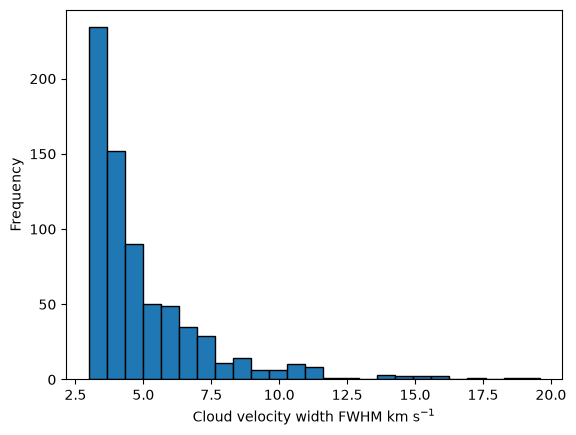

In [20]:
destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

sig_v = df_2['sigv_kms']
v_fwhm = sig_v * 2.354

v_fwhm = v_fwhm[v_fwhm < 20]

log = False


if log == True:
    
    bins = np.logspace(
        np.log10(v_fwhm.min()),
        np.log10(v_fwhm.max()),
        int(np.sqrt(len(v_fwhm)))
)
    plt.hist(v_fwhm, bins=bins, edgecolor='k')
    plt.xscale('log')

    plt.xlabel('Cloud velocity width (km/s)')
    plt.ylabel('Frequency')
else:
    bins = np.linspace(
        v_fwhm.min(),
        v_fwhm.max(),
        int(np.sqrt(len(v_fwhm)))
)
    plt.hist(v_fwhm, bins=bins, edgecolor='k')

    plt.xlabel(r'Cloud velocity width FWHM km s$^{-1}$')
    plt.ylabel('Frequency')
print(m.max())

#plt.savefig(destination_path + "fwhm_v_histogram.png")

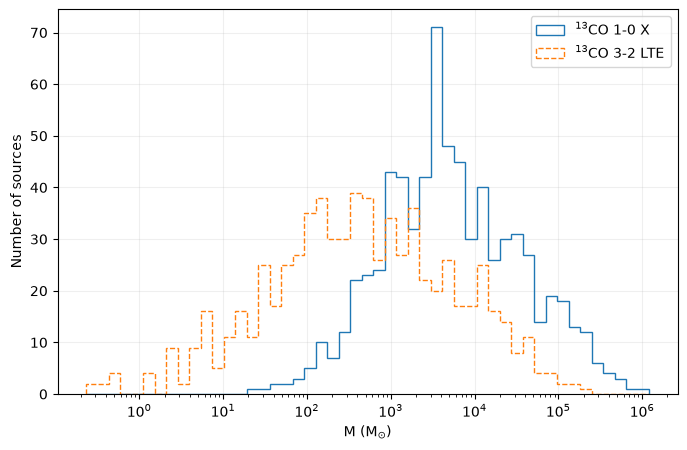

In [6]:
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
m = df_2['M_Sol_X 13CO 1-0'].dropna()

mode = 5

M2 = {
    1: df_2['M_Sol 13CO 1-0 LTE'].dropna(),
    2: df_2['M_Sol_X 13CO 3-2'].dropna(),
    3: df_2['M_Sol_X 12CO 1-0'].dropna(),
    4: df_2['M_Sol_X 12CO 3-2'].dropna(),
    5: df_2['M_Sol 13CO 3-2 LTE'].dropna()
}

m2 = M2[mode]
m2 = m2[m2>0]

Mmin = min(m.min(), m2.min())
Mmax = max(m.max(), m2.max())

bins = np.logspace(
    np.log10(Mmin),
    np.log10(Mmax),
    50
)
    
plt.figure(figsize=(8,5))

labl = {
    1: "$^{13}$CO 1-0 LTE",
    2: "$^{13}$CO 3-2 X",
    3: "$^{12}$CO 1-0 X",
    4: "$^{12}$CO 3-2 X",
    5: "$^{13}$CO 3-2 LTE"
}
Label = labl[mode]

plt.hist(m, bins=bins, density=False, histtype='step', label = "$^{13}$CO 1-0 X")
plt.hist(m2, bins=bins, density=False, histtype='step', label = Label, linestyle = '--')

plt.xlabel("M (M$_{\odot}$)")
plt.ylabel("Number of sources")
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.2)

df_2.columns

saved_name = {
    1: destination_path + 'Mass_comparison_histogram_13CO_1-0_LTE.png',
    2: destination_path + 'Mass_comparison_histogram_13CO_3-2_X.png',
    3: destination_path + 'Mass_comparison_histogram_12CO_1-0_X.png',
    4: destination_path + 'Mass_comparison_histogram_12CO_3-2_X.png',
    5: destination_path + 'Mass_comparison_histogram_13CO_3-2_LTE.png'
}

#plt.savefig(saved_name[mode])

1220466.063


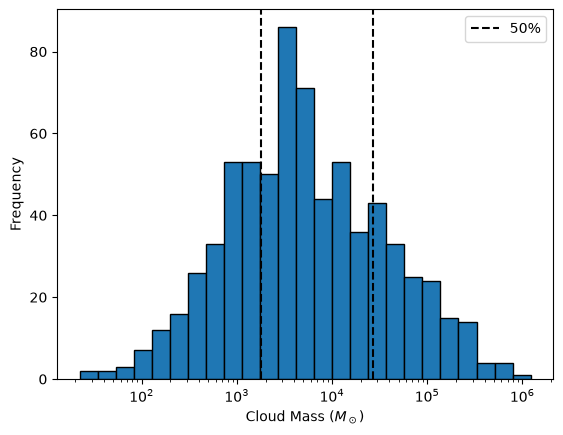

In [179]:
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
#df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/Mopra_Cloud_Mass_Catalogue_Fullinfo.csv')


m = df_2['M_Sol_X 13CO 1-0'].dropna()
#m = df_2['M_pixel_Sol'][df_2['M_pixel_Sol']<10000000].dropna()

bins = np.logspace(
    np.log10(m.min()),
    np.log10(m.max()),
    int(np.sqrt(len(m)))
)

plt.hist(m, bins=bins, edgecolor='k')
plt.xscale('log')

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')
#plt.axvline(1800, color='k', ls='--', label='50%')
#plt.axvline(27000, color='k', ls='--')

#plt.axvline(1100, color='r', ls='--', label='68%')
#plt.axvline(53000, color='r', ls='--')

#plt.axvline(190, color='g', ls='--', label='95%')
#plt.axvline(310000, color='g', ls='--')

plt.legend()

print(m.max())

#plt.savefig(destination_path + "Mass_histogram.png")
#plt.savefig("/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/Mass_histogram.png")

In [381]:
bins

array([1.03000000e+02, 1.59313015e+02, 2.46413949e+02, 3.81135429e+02,
       5.89512954e+02, 9.11816371e+02, 1.41033219e+03, 2.18140071e+03,
       3.37403421e+03, 5.21871420e+03, 8.07193295e+03, 1.24850871e+04,
       1.93110376e+04, 2.98689284e+04, 4.61991169e+04, 7.14574816e+04,
       1.10525309e+05, 1.70952624e+05, 2.64417261e+05, 4.08981661e+05,
       6.32583510e+05, 9.78434818e+05, 1.51337282e+06, 2.34077658e+06,
       3.62054538e+06, 5.60000000e+06])

In [382]:
bin_medians

array([3.895e+02, 9.000e+02, 1.350e+03, 1.945e+03, 2.650e+03, 3.150e+03,
       3.800e+03, 4.640e+03, 5.820e+03, 7.380e+03, 8.760e+03, 9.830e+03,
       1.110e+04, 1.275e+04, 1.480e+04, 1.775e+04, 2.080e+04, 2.620e+04,
       3.285e+04, 4.100e+04, 5.210e+04, 7.195e+04, 9.560e+04, 1.260e+05,
       1.835e+05, 3.230e+05, 5.910e+05, 1.640e+06])

Best-fit parameters: c = 1.0227, a = 0.5371


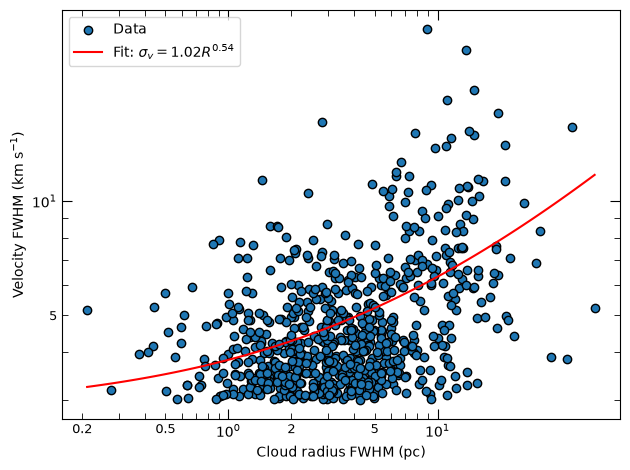

In [22]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker



# Define the model: power law
def power_law(R, c, a, b):
    return c * R**a + b

# Fit the model
popt, pcov = curve_fit(power_law, df_2['radius(pc)'], df_2['sigv_kms']*2.354)
c_fit, a_fit, b_fit = popt

# Print results
print(f"Best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}")

# Plot the data and the fit
R_fit = np.logspace(np.log10(min(R)), np.log10(max(R)), 100)
s_fit = power_law(R_fit, c_fit, a_fit, b_fit)


plt.scatter(
    df_2['radius(pc)'],
    df_2['sigv_kms'] * 2.354,
    edgecolor='k',
    label = 'Data'
)
plt.plot(R_fit, s_fit, label=fr'Fit: $\sigma_v = {c_fit:.2f} R^{{{a_fit:.2f}}}$', color='red')

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Cloud radius FWHM (pc)')
plt.ylabel('Velocity FWHM (km s$^{-1}$)')

ax = plt.gca()

# --- Major ticks (decades)
ax.xaxis.set_major_locator(ticker.LogLocator(base=10))
ax.yaxis.set_major_locator(ticker.LogLocator(base=10))

# --- Minor ticks (2–9 per decade)
subs = np.arange(2, 10) * 0.1
ax.xaxis.set_minor_locator(ticker.LogLocator(base=10, subs=subs))
ax.yaxis.set_minor_locator(ticker.LogLocator(base=10, subs=subs))

# --- Label ONLY selected minor ticks (2 and 5)
def minor_log_formatter(val, pos):
    decade = 10 ** np.floor(np.log10(val))
    mantissa = val / decade
    if np.isclose(mantissa, 2) or np.isclose(mantissa, 5):
        return f"{val:g}"
    return ""

ax.xaxis.set_minor_formatter(ticker.FuncFormatter(minor_log_formatter))
ax.yaxis.set_minor_formatter(ticker.FuncFormatter(minor_log_formatter))

# --- Tick appearance
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.tick_params(which='major', length=7)
ax.tick_params(which='minor', length=4, labelsize=9)
plt.legend()
plt.tight_layout()
#plt.show()
#plt.savefig(destination_path + "radius-velocity_relation.png")

In [397]:
df_2.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'pixel number 13CO 1-0', 'final_distance', 'distance_cm',
       'Mean_flux 13CO 1-0', 'density 13CO 1-0', 'M_Sol_X 13CO 1-0',
       'pixel number 13CO 1-0 LTE', 'LTE_Density 13O 1-0',
       'Mean_flux 13CO 1-0 LTE', 'M_Sol 13CO 1-0 LTE', 'pixel number 13CO 3-2',
       'Mean_flux 13CO 3-2', 'density 13CO 3-2', 'M_Sol_X 13CO 3-2',
       'pixel number 12CO 1-0', 'Mean_flux 12CO 1-0', 'X_density 12CO 1-0',
       'M_Sol_X 12CO 1-0', 'pixel number 12CO 3-2', 'Mean_flux 12CO 3-2',
       'X_density 12CO 3-2', 'M_Sol_X 12CO 3-2', 'pixel number 13CO 3-2 LTE',
       'LTE_Density 13CO 3-2', 'Mean_flux 13CO 3-2 LTE', 'M_Sol 13CO 3-2 LTE'],
      dtype='object')

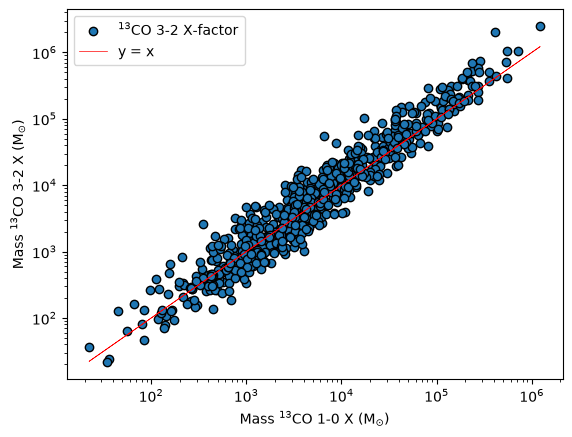

In [38]:
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

mass_options = {
    2: {
        "column": "M_Sol 13CO 1-0 LTE",
        "label": r"$^{13}$CO 1-0 LTE",
        "axlabel": 'Mass $^{13}$CO 1-0 LTE (M$_{\odot}$)',
        "title": destination_path + 'Mass_comparison_13CO_10_LTE.png'
    },
    3: {
        "column": "M_Sol_X 13CO 3-2",
        "label": r"$^{13}$CO 3-2 X-factor",
        "axlabel": 'Mass $^{13}$CO 3-2 X (M$_{\odot}$)',
        "title": destination_path + 'Mass_comparison_13CO_32_X.png'
    },
    4: {
        "column": "M_Sol_X 12CO 1-0",
        "label": r"$^{12}$CO 1-0 X-factor",
        "axlabel": 'Mass $^{12}$CO 1-0 X (M$_{\odot}$)',
        "title": destination_path + 'Mass_comparison_12CO_10_X.png'
    },
    5: {
        "column": "M_Sol_X 12CO 3-2",
        "label": r"$^{12}$CO 3-2 X-factor",
        "axlabel": 'Mass $^{12}$CO 3-2 X (M$_{\odot}$)',
        "title":destination_path + 'Mass_comparison_12CO_32_X.png'
    },
    6: {
        "column": "M_Sol 13CO 3-2 LTE",
        "label": r"$^{13}$CO 3-2 LTE",
        "axlabel": 'Mass $^{13}$CO 3-2 LTE (M$_{\odot}$)',
        "title": destination_path + 'Mass_comparison_13CO_32_LTE.png'
    }
}

mode = 3
m_choice     = df_2[mass_options[mode]["column"]].dropna()
label_choice = mass_options[mode]["label"]
axlabel      = mass_options[mode]["axlabel"]

plt.scatter(
    df_2['M_Sol_X 13CO 1-0'],
    m_choice,
    edgecolor='k',
    label = label_choice)
plt.plot(
    df_2['M_Sol_X 13CO 1-0'],
    df_2['M_Sol_X 13CO 1-0'],
    color='red',
    label = 'y = x',
    linewidth = 0.5
)

plt.xlabel('Mass $^{13}$CO 1-0 X (M$_{\odot}$)')
plt.ylabel(axlabel)
plt.xscale('log')
plt.yscale('log')
plt.legend()

file_title = mass_options[mode]["title"]
plt.savefig(file_title)

In [433]:
df

,Universal_ID,_idx,position_angle,v_cen,v_rms,x_cen,y_cen,sigv_kms,major_arcsec,minor_arcsec,...,Mean_flux 13CO 3-2 COLTE,M_Sol 13CO 3-2 COLTE,semi_major_deg,semi_minor_deg,semi_major_cm,semi_minor_cm,radius(pc),radius_pc,diameter_pc,w
0,1,23,-153.3,121215.69,4.18,19.636,0.061,2.09,463.3,185.4,...,1.64,16926.000696,0.064347,0.025750,7.53e+19,3.01e+19,15.436152,15.436152,30.872304,73.254057
1,2,58,51.3,120036.92,2.85,21.553,-0.113,1.43,146.5,86.1,...,3.61,4296.599803,0.020347,0.011958,1.99e+19,1.17e+19,4.934719,4.934719,9.869438,69.046730
2,3,71,159.8,121537.93,4.02,19.045,0.101,2.01,425.0,93.3,...,0.44,389.669990,0.059028,0.012958,6.95e+19,1.52e+19,10.544709,10.544709,21.089418,74.620314
3,4,187,164.3,116577.30,5.12,22.590,0.349,2.56,120.9,87.9,...,0.53,53.010001,0.016792,0.012208,1.94e+19,1.41e+19,5.347155,5.347155,10.694311,66.200912
4,5,336,166.5,116260.00,4.73,20.375,-0.108,2.37,407.0,276.7,...,1.35,6891.300073,0.056528,0.038431,6.68e+19,4.54e+19,17.847156,17.847156,35.694313,70.051677
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
705,706,3338,143.4,-14152.03,3.12,26.999,-0.073,1.56,223.3,74.6,...,1.52,4529.100000,0.031014,0.010361,6.09e+19,2.04e+19,11.415549,11.415549,22.831098,25.233802
706,707,90,-138.0,86917.52,5.24,36.882,0.311,2.62,249.3,152.1,...,0.69,1116.000000,0.034625,0.021125,2.35e+19,1.43e+19,5.944713,5.944713,11.889425,46.722381
707,708,269,170.7,79983.36,3.29,36.915,-0.095,1.64,494.0,228.1,...,1.45,9765.000000,0.068611,0.031681,5.05e+19,2.33e+19,11.10978,11.10978,22.219559,45.337503
708,709,963,78.2,48941.35,6.00,37.015,0.140,3.00,122.5,90.5,...,0.37,32.271000,0.017014,0.012569,6.32e+18,4.67e+18,1.7604,1.7604,3.520799,39.002934


In [429]:
a1, a2, a3 = 1.0077, 0.0394, 0.0071  # Brand & Blitz (1993)
theta0 = 236.0                      # km/s
R0 = 8.15                           # kpc
omega0 = theta0 / R0
dtor = np.pi / 180

df['w'] = omega0 * ((a1 * (df['R_GC']/R0)**(a2 - 1)) + a3 * (R0 / df['R_GC']))

In [430]:
df['w']

0      73.254057
1      69.046730
2      74.620314
3      66.200912
4      70.051677
         ...    
705    25.233802
706    46.722381
707    45.337503
708    39.002934
709    32.033936
Name: w, Length: 710, dtype: float64

In [486]:
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,vcens,major_arcsec,minor_arcsec,parent,ancestor,n_leaves,structure_type,idx,has_match,AGAL_distance
0,23,10475.909224,24269.0,77.527642,31.026817,-153.318727,49.045244,121215.685783,4.176112,19.635815,...,121215.685783,463.305187,185.416255,-1,23,24,b'T',23,False,0
1,58,1536.908736,5938.0,24.507076,14.399873,51.275414,18.785600,120036.921631,2.850359,21.552562,...,120036.921631,146.454286,86.053638,-1,58,7,b'T',58,True,7.7
2,71,4837.554092,8140.0,71.125798,15.617113,159.755314,33.328360,121537.933089,4.018101,19.044805,...,121537.933089,425.047767,93.327866,-1,71,9,b'T',71,False,0
3,187,1296.271476,2454.0,20.229093,14.713691,164.251155,17.252380,116577.304637,5.119977,22.590175,...,116577.304637,120.889057,87.929017,530,1237,2,b'B',187,False,0
4,336,13732.885823,24540.0,68.101413,46.302853,166.537991,56.154160,116259.995189,4.733358,20.374814,...,116259.995189,406.974042,276.705851,-1,336,25,b'T',336,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,17078,197.635684,833.0,8.003735,5.669891,145.157247,6.736491,15425.480599,3.404084,22.563021,...,15425.480599,47.830319,33.883271,-1,17078,2,b'T',17078,True,1.8
275,17214,675.087334,1093.0,15.281590,10.143632,129.741682,12.450334,14227.532304,2.686744,21.960101,...,14227.532304,91.322779,60.618346,-1,17214,3,b'T',17214,False,0
276,17265,2377.670032,4958.0,35.662080,15.309005,105.325872,23.365594,11456.539999,2.900702,18.139931,...,11456.539999,213.116593,91.486615,-1,17265,4,b'T',17265,False,0
277,18484,509.281916,848.0,17.192379,6.801808,168.816038,10.813845,-13507.983000,3.043780,25.425653,...,-13507.983000,102.741658,40.647602,-1,18484,3,b'T',18484,False,0


In [470]:
df_37_47 = df

In [480]:
df_27_37 = df

In [487]:
df_17_27 = df

In [516]:
df_17_47 = pd.concat([df_17_27, df_27_37, df_37_47], ignore_index=True)

In [517]:
df_17_47

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,structure_type,idx,has_match,AGAL_distance,R_GC,d_near,d_far,distance,dist_method,distance_flag
0,23,10475.909224,24269.0,77.527642,31.026817,-153.318727,49.045244,121215.685783,4.176112,19.635815,...,b'T',23,False,0,3.15,6.119828e+00,9.232297,9.232297,0,far
1,58,1536.908736,5938.0,24.507076,14.399873,51.275414,18.785600,120036.921631,2.850359,21.552562,...,b'T',58,True,7.7,3.35,6.077234e+00,9.083115,9.083115,0,far
2,71,4837.554092,8140.0,71.125798,15.617113,159.755314,33.328360,121537.933089,4.018101,19.044805,...,b'T',71,False,0,3.09,6.130485e+00,9.277337,9.277337,0,far
3,187,1296.271476,2454.0,20.229093,14.713691,164.251155,17.252380,116577.304637,5.119977,22.590175,...,b'B',187,False,0,3.50,5.960006e+00,9.089673,9.089673,0,far
4,336,13732.885823,24540.0,68.101413,46.302853,166.537991,56.154160,116259.995189,4.733358,20.374814,...,b'T',336,False,0,3.30,5.955301e+00,9.324919,9.324919,0,far
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
706,12141,567.253429,1208.0,15.347724,8.486629,-162.642490,11.412731,8330.096988,2.804845,45.444871,...,b'T',12141,False,0,7.86,4.215271e-01,11.014475,11.014475,0,far
707,12177,254.995263,684.0,8.642020,6.775150,-169.320296,7.651861,6563.560679,2.799835,43.002422,...,b'T',12177,False,0,7.92,3.185738e-01,11.602022,11.602022,0,far
708,12298,474.617002,1448.0,13.795119,7.899869,60.867831,10.439331,4315.068291,3.558471,45.050410,...,b'T',12298,False,0,8.04,1.567846e-01,11.358928,11.358928,0,far
709,12332,8475.918332,12112.0,72.261278,26.932905,105.763377,44.115826,1887.388250,3.939025,37.945349,...,b'T',12332,False,0,8.15,1.634296e-13,12.854327,12.854327,0,far


In [518]:
df_17_47.to_csv('CHIMPS_X_FUGIN_Master_mass_catalogue_Kinematic_distances.csv')

In [515]:
df_17_27 = df

In [514]:
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,structure_type,idx,has_match,AGAL_distance,R_GC,d_near,d_far,distance,dist_method,distance_flag
0,23,10475.909224,24269.0,77.527642,31.026817,-153.318727,49.045244,121215.685783,4.176112,19.635815,...,b'T',23,False,0,3.15,6.119828,9.232297,9.232297,0,far
1,58,1536.908736,5938.0,24.507076,14.399873,51.275414,18.785600,120036.921631,2.850359,21.552562,...,b'T',58,True,7.7,3.35,6.077234,9.083115,9.083115,0,far
2,71,4837.554092,8140.0,71.125798,15.617113,159.755314,33.328360,121537.933089,4.018101,19.044805,...,b'T',71,False,0,3.09,6.130485,9.277337,9.277337,0,far
3,187,1296.271476,2454.0,20.229093,14.713691,164.251155,17.252380,116577.304637,5.119977,22.590175,...,b'B',187,False,0,3.50,5.960006,9.089673,9.089673,0,far
4,336,13732.885823,24540.0,68.101413,46.302853,166.537991,56.154160,116259.995189,4.733358,20.374814,...,b'T',336,False,0,3.30,5.955301,9.324919,9.324919,0,far
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,17078,197.635684,833.0,8.003735,5.669891,145.157247,6.736491,15425.480599,3.404084,22.563021,...,b'T',17078,True,1.8,7.00,1.263527,13.788909,1.263527,0,near
275,17214,675.087334,1093.0,15.281590,10.143632,129.741682,12.450334,14227.532304,2.686744,21.960101,...,b'T',17214,False,0,7.06,1.190428,13.927015,1.190428,0,near
276,17265,2377.670032,4958.0,35.662080,15.309005,105.325872,23.365594,11456.539999,2.900702,18.139931,...,b'T',17265,False,0,7.09,1.124553,14.365491,1.124553,0,near
277,18484,509.281916,848.0,17.192379,6.801808,168.816038,10.813845,-13507.983000,3.043780,25.425653,...,b'T',18484,False,0,9.56,-1.536000,16.257238,16.257238,2,far


In [535]:
path = Path(
    SkyCoord(
        l=[37, 47] * u.deg,
        b=[0, 0] * u.deg,
        frame="galactic"
    )
)
cube = SpectralCube.read(fits_file)

In [536]:
pv_slice = extract_pv_slice(cube, path)

In [537]:
pv_slice

In [538]:
fits_file

'/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_047_13CO_23arcsec_aligned.fits'

In [141]:
from numpy.random import *

help(np.random.rand)

Help on built-in function rand:

rand(...) method of numpy.random.mtrand.RandomState instance
    rand(d0, d1, ..., dn)
    
    Random values in a given shape.
    
    .. note::
        This is a convenience function for users porting code from Matlab,
        and wraps `random_sample`. That function takes a
        tuple to specify the size of the output, which is consistent with
        other NumPy functions like `numpy.zeros` and `numpy.ones`.
    
    Create an array of the given shape and populate it with
    random samples from a uniform distribution
    over ``[0, 1)``.
    
    Parameters
    ----------
    d0, d1, ..., dn : int, optional
        The dimensions of the returned array, must be non-negative.
        If no argument is given a single Python float is returned.
    
    Returns
    -------
    out : ndarray, shape ``(d0, d1, ..., dn)``
        Random values.
    
    See Also
    --------
    random
    
    Examples
    --------
    >>> np.random.rand(3,2)
    arra

## Test 1: Randomly assigned distance solutions

In [88]:
assign = rand(710)
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
df_2['dist_assign']=assign

In [89]:
mH2            = 1.67 * 2.72 * pow(10,-24)
Msol           = 2 * pow(10,33)
pixel_area_arc = pow(1.66*3.6,2)
arc_2_sr       = pow(np.pi/180/3600,2)
pixel_size_sr  = pixel_area_arc * arc_2_sr
X_factor       = 6.52 * pow(10,20)
constants      = mH2 / Msol * pixel_size_sr * X_factor * (3.086 * pow(10,21)) ** 2

In [90]:
## This will assign distance solutions, near or far, randomly. Ignores AGAL distances. 
## 0.637 accounts for the ratio of near/far solutions in the original 710 sources
## 452 were near and 258 were far. Adjust limit as you see fit.

rand_mass = np.zeros(len(df_2))
for i in range(len(df_2)):
    if df_2['d_near'][i] == 0:
        rand_mass[i] = constants * df_2['d_far'][i] ** 2 * df_2['Mean_flux 13CO 1-0'][i] * df_2['pixel number 13CO 1-0'][i]
    elif df_2['dist_assign'][i] < 0.637:
 #   elif df['dist_assign'][i] < 0.5:
        rand_mass[i] = constants * df_2['d_near'][i] ** 2 * df_2['Mean_flux 13CO 1-0'][i] * df_2['pixel number 13CO 1-0'][i]
    else:
        rand_mass[i] = constants * df_2['d_far'][i] ** 2 * df_2['Mean_flux 13CO 1-0'][i] * df_2['pixel number 13CO 1-0'][i]

In [91]:
df_2.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'pixel number 13CO 1-0', 'final_distance', 'distance_cm',
       'Mean_flux 13CO 1-0', 'density 13CO 1-0', 'M_Sol_X 13CO 1-0',
       'pixel number 13CO 1-0 LTE', 'LTE_Density 13O 1-0',
       'Mean_flux 13CO 1-0 LTE', 'M_Sol 13CO 1-0 LTE', 'pixel number 13CO 3-2',
       'Mean_flux 13CO 3-2', 'density 13CO 3-2', 'M_Sol_X 13CO 3-2',
       'pixel number 12CO 1-0', 'Mean_flux 12CO 1-0', 'X_density 12CO 1-0',
       'M_Sol_X 12CO 1-0', 'pixel number 12CO 3-2', 'Mean_flux 12CO 3-2',
       'X_density 12CO 3-2', 'M_Sol_X 12CO 3-2', 'pixel number 13CO 3-2 LTE',
       'LTE_Density 13CO 3-2', 'Mean_flux 13CO 3-2 LTE', 'M_Sol 13CO 3-2 LTE',
       'dist_assign'],
      dtype='str')

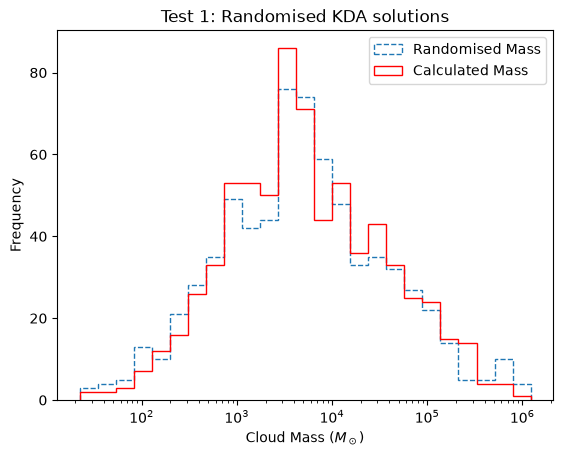

In [96]:
bins_rand = np.logspace(
    np.log10(rand_mass.min()),
    np.log10(rand_mass.max()),
    int(np.sqrt(len(rand_mass)))
)

plt.hist(rand_mass, bins=bins, histtype = 'step', linestyle ='--', label = "Randomised Mass")
plt.xscale('log')

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')

m = df_2['M_Sol_X 13CO 1-0'].dropna()

bins = np.logspace(
    np.log10(m.min()),
    np.log10(m.max()),
    int(np.sqrt(len(m)))
)

plt.hist(m, bins=bins, histtype='step', color = 'red', label ="Calculated Mass")
plt.title("Test 1: Randomised KDA solutions")
plt.legend()
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/distances_vs_random_KDA_distances_Mass_histogram_64.png")

In [93]:
distance_flags = []
for i in range(len(df_2)):
    if df_2['distance'][i] == df_2['d_far'][i]:
        distance_flags.append('far')
    else:
        distance_flags.append('near')
df_2['distance_flag'] = distance_flags
df_2[df_2['distance_flag']=='near']

,Universal_ID,_idx,position_angle,v_cen,v_rms,x_cen,y_cen,sigv_kms,major_arcsec,minor_arcsec,...,pixel number 12CO 3-2,Mean_flux 12CO 3-2,X_density 12CO 3-2,M_Sol_X 12CO 3-2,pixel number 13CO 3-2 LTE,LTE_Density 13CO 3-2,Mean_flux 13CO 3-2 LTE,M_Sol 13CO 3-2 LTE,dist_assign,distance_flag
5,6,457,-174.7,109390.44,12.66,24.166,0.194,6.33,1083.1,484.1,...,122293,16.30,6.850000e+21,1.969491e+05,76187,1.930000e+20,4.00,42090.406070,0.425183,near
8,9,844,176.1,102309.37,13.29,26.185,-0.018,6.64,1393.2,740.3,...,256155,14.70,6.170000e+21,1.657682e+06,133214,2.200000e+20,2.67,214961.716738,0.274236,near
11,12,1178,-156.4,115901.74,3.16,25.464,-0.357,1.58,291.3,70.8,...,5541,10.59,4.450000e+21,1.634335e+04,2205,2.150000e+18,1.54,1324.978541,0.598453,near
12,13,1214,-171.2,116325.91,3.60,25.881,0.069,1.80,45.0,38.2,...,581,6.95,2.920000e+21,1.140532e+03,205,1.330000e+17,0.93,82.884120,0.220211,near
13,14,1248,48.7,111185.86,5.10,24.476,-0.296,2.55,95.1,45.0,...,1834,10.97,4.610000e+21,5.136481e+03,1202,1.280000e+18,1.98,721.442060,0.428297,near
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
702,703,2357,-166.6,67966.90,2.63,26.933,-0.335,1.31,298.3,127.6,...,10737,5.76,2.300000e+21,7.552961e+03,4991,1.210000e+19,2.71,3430.702146,0.154645,near
703,704,2563,155.8,63341.24,2.80,27.038,-0.088,1.40,112.1,73.7,...,3073,3.67,1.470000e+21,1.154541e+03,370,3.490000e+17,0.60,83.053391,0.293777,near
706,707,90,-138.0,86917.52,5.24,36.882,0.311,2.62,249.3,152.1,...,8836,2.57,1.030000e+21,4.716223e+03,3138,2.710000e+18,0.69,1302.798283,0.435577,near
707,708,269,170.7,79983.36,3.29,36.915,-0.095,1.64,494.0,228.1,...,25821,6.64,2.660000e+21,4.190901e+04,16420,2.000000e+19,1.45,11399.484979,0.100897,near


True
True
KstestResult(statistic=np.float64(0.038028169014084505), pvalue=np.float64(0.683985127059257), statistic_location=np.float64(834.0732197413948), statistic_sign=np.int8(-1))


Text(0.5, 1.0, 'Test 1: Randomised KDA solutions')

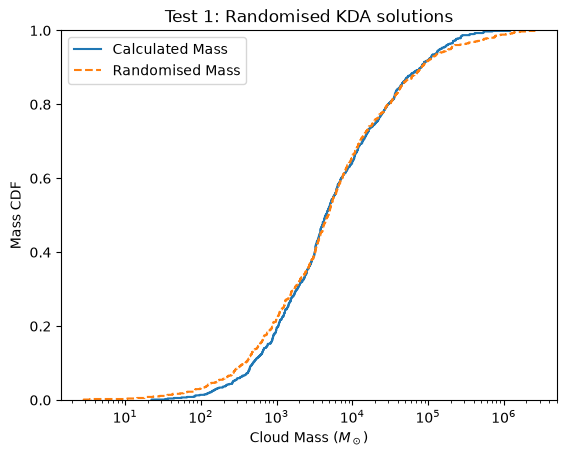

In [97]:
from scipy import stats
from scipy.stats import ks_2samp
import seaborn as sns

print(stats.kstest(m, stats.norm.cdf) == stats.ks_1samp(m, stats.norm.cdf))  # True
print(stats.kstest(m, rand_mass) == stats.ks_2samp(m, rand_mass))                            # True
print(stats.kstest(m, rand_mass))

ax = sns.ecdfplot(
    m,
    log_scale=True,
    label='Calculated Mass',
    linestyle='-'
)

sns.ecdfplot(
    rand_mass,
    log_scale=True,
    label='Randomised Mass',
    linestyle='--',
    ax=ax
)

plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel("Mass CDF")
plt.title("Test 1: Randomised KDA solutions")
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/distances_vs_random_KDA_distances_KStest_64.png")

## Test 2: Randomising assigned distances

In [110]:
assigned_distances = df_2['final_distance'].values

In [111]:
rand_mass_2 = np.zeros(len(df_2))

for i in range(len(df_2)):
    rand_dist = np.random.choice(assigned_distances)
    rand_mass_2[i] = constants * rand_dist ** 2 * df_2['Mean_flux 13CO 1-0'][i] * df_2['pixel number 13CO 1-0'][i]

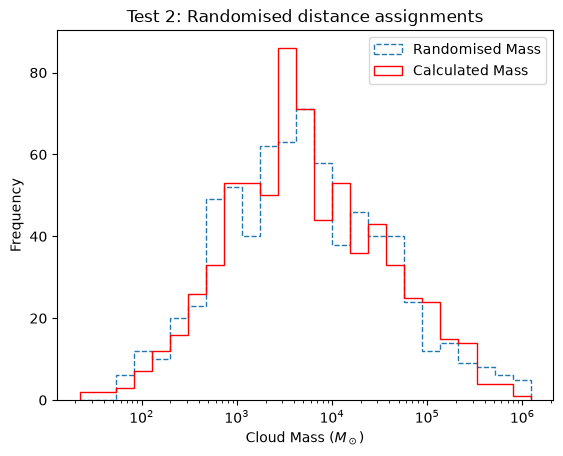

In [114]:
bins_rand_2 = np.logspace(
    np.log10(rand_mass_2.min()),
    np.log10(rand_mass_2.max()),
    int(np.sqrt(len(rand_mass_2)))
)

plt.hist(rand_mass_2, bins=bins, histtype='step', linestyle='--', label = "Randomised Mass")
plt.xscale('log')

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')

m = df_2['M_Sol_X 13CO 1-0'].dropna()

bins = np.logspace(
    np.log10(m.min()),
    np.log10(m.max()),
    int(np.sqrt(len(m)))
)

plt.hist(m, bins=bins, histtype='step', color = 'red', label = "Calculated Mass")
plt.title("Test 2: Randomised distance assignments")
plt.legend()
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/distances_vs_randomised_distances_Mass_histogram.png")

True
True
KstestResult(statistic=np.float64(0.03943661971830986), pvalue=np.float64(0.6392483603642096), statistic_location=np.float64(869.8094547159972), statistic_sign=np.int8(-1))


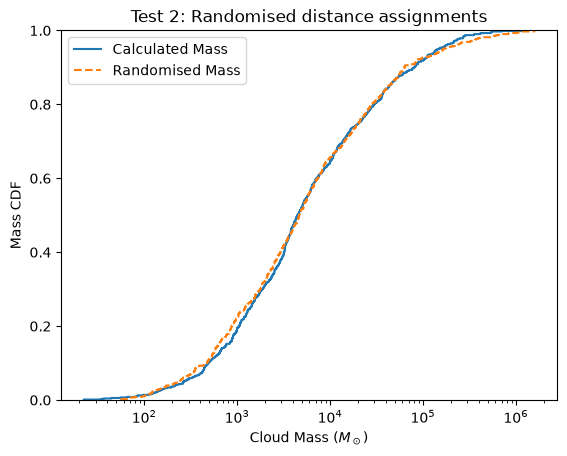

In [115]:
print(stats.kstest(m, stats.norm.cdf) == stats.ks_1samp(m, stats.norm.cdf))  # True
print(stats.kstest(m, rand_mass_2) == stats.ks_2samp(m, rand_mass_2))                            # True
print(stats.kstest(m, rand_mass_2))

ax = sns.ecdfplot(
    m,
    log_scale=True,
    label='Calculated Mass',
    linestyle='-'
)

sns.ecdfplot(
    rand_mass_2,
    log_scale=True,
    label='Randomised Mass',
    linestyle='--',
    ax=ax
)

plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
plt.title("Test 2: Randomised distance assignments")
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/distances_vs_randomised_distances_KStest.png")

## Test 3: Uniformly spaced distances

In [116]:
linear_distances = np.linspace(df_2['final_distance'].min(),df_2['final_distance'].max(),len(df_2))
rand_mass_3 = np.zeros(len(df_2))
for i in range(len(df_2)):
    rand_mass_3[i] = constants * linear_distances[i] ** 2 * df_2['Mean_flux 13CO 1-0'][i] * df_2['pixel number 13CO 1-0'][i]

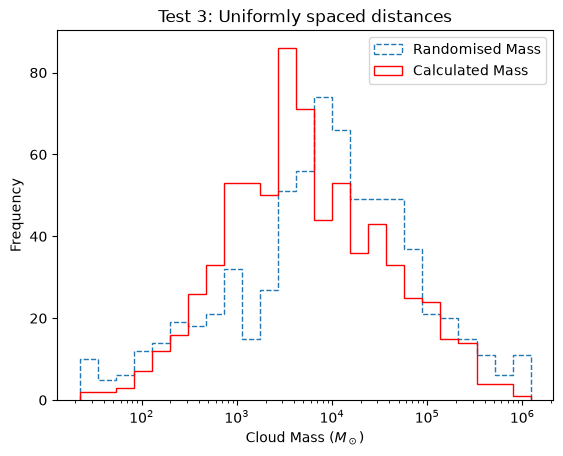

In [118]:
bins_rand_3 = np.logspace(
    np.log10(rand_mass_3.min()),
    np.log10(rand_mass_3.max()),
    int(np.sqrt(len(rand_mass_3)))
)

plt.hist(rand_mass_3, bins=bins, histtype='step', linestyle='--', label = "Randomised Mass")
plt.xscale('log')

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')

m = df_2['M_Sol_X 13CO 1-0'].dropna()

bins = np.logspace(
    np.log10(m.min()),
    np.log10(m.max()),
    int(np.sqrt(len(m)))
)

plt.hist(m, bins=bins, histtype='step', color = 'red', label = "Calculated Mass")
plt.title("Test 3: Uniformly spaced distances")
plt.legend()
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/distances_vs_uniform_distances_Mass_histogram.png")

True
True
KstestResult(statistic=np.float64(0.1732394366197183), pvalue=np.float64(1.0154235130082622e-09), statistic_location=np.float64(6400.814074), statistic_sign=np.int8(1))


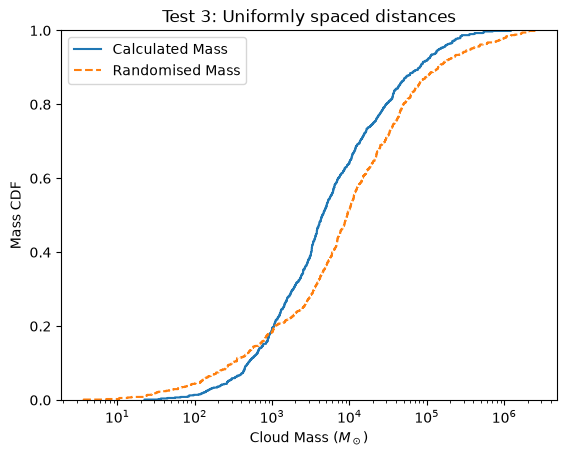

In [119]:
print(stats.kstest(m, stats.norm.cdf) == stats.ks_1samp(m, stats.norm.cdf))  # True
print(stats.kstest(m, rand_mass_3) == stats.ks_2samp(m, rand_mass_3))                            # True
print(stats.kstest(m, rand_mass_3))

ax = sns.ecdfplot(
    m,
    log_scale=True,
    label='Calculated Mass',
    linestyle='-'
)

sns.ecdfplot(
    rand_mass_3,
    log_scale=True,
    label='Randomised Mass',
    linestyle='--',
    ax=ax
)

plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
plt.title("Test 3: Uniformly spaced distances")
#plt.savefig("/Users/kyriakos.trakakis/CHIMPS_FGN paper/distances_vs_uniform_distances_KStest.png")

## Power law for 6 masses at once

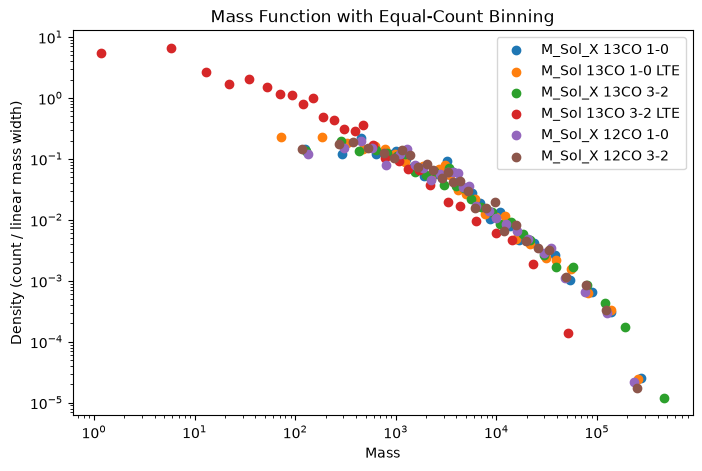

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

# Load CSV
df = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

# ---- List your 6 columns here ----
#columns = [
#    "M_Sol_X 13CO 1-0",
#    "M_Sol 13CO 1-0 LTE",
#    "M_Sol_X 13CO 3-2",
#    "M_Sol_X 12CO 1-0",
#    "M_Sol_X 12CO 3-2",
#    "M_Sol 13CO 3-2 LTE"
#]

#start_indices = [
#    11,  # 13CO 1-0 X
#    12,  # 13CO 1-0 LTE
#    11,  # 13CO 3-2 X
#    12,  # 12CO 1-0 X
#    6,   # 12CO 3-2 X
#    13   # 13CO 3-2 LTE
#]

columns = [
    'M_Sol_X 13CO 1-0',
    'M_Sol 13CO 1-0 LTE',
    'M_Sol_X 13CO 3-2',
    'M_Sol 13CO 3-2 LTE',
    'M_Sol_X 12CO 1-0',
    'M_Sol_X 12CO 3-2'
]

start_indices = [
    11,
    12,
    11,
    13,
    12,
    6
]
    

def equal_count_mass_function(values):

    values = values[values > 0].dropna().values
    N = len(values)
    num_bins = math.ceil(2 * (N ** 0.4))

    sorted_vals = np.sort(values)

    # Quantile bin edges
    quantiles = np.linspace(0, 1, num_bins + 1)
    bin_edges = np.quantile(sorted_vals, quantiles)
    bin_edges = np.unique(bin_edges)

    num_bins_actual = len(bin_edges) - 1

    counts = np.histogram(sorted_vals, bins=bin_edges)[0]
    bin_widths = bin_edges[1:] - bin_edges[:-1]
    density = counts / bin_widths

    # Compute bin medians
    bin_values = []
    for i in range(num_bins_actual):
        left = bin_edges[i]
        right = bin_edges[i+1]

        mask = (sorted_vals >= left) & (sorted_vals < right)
        if i == num_bins_actual - 1:
            mask = (sorted_vals >= left) & (sorted_vals <= right)

        bin_values.append(sorted_vals[mask])

    bin_medians = np.array([np.median(vals) for vals in bin_values])

    return bin_medians, density


# ---- Plot all columns ----
plt.figure(figsize=(8,5))

for col in columns:
    medians, density = equal_count_mass_function(df[col])
    plt.scatter(medians, density, label=col)

plt.xscale('log')
plt.yscale('log')
plt.xlabel("Mass")
plt.ylabel("Density (count / linear mass width)")
plt.title("Mass Function with Equal-Count Binning")
plt.legend()
plt.show()


Column: X factor 13CO 1-0
A = 2.3174e+04
a = -1.5663 ± 0.0731
χ² = 0.0130

Column: LTE 13CO 1-0
A = 1.3249e+04
a = -1.5161 ± 0.0831
χ² = 0.0102

Column: X factor 13CO 3-2
A = 1.2536e+04
a = -1.5016 ± 0.0723
χ² = 0.0109

Column: LTE 13CO 3-2
A = 1.5664e+03
a = -1.3905 ± 0.0757
χ² = 0.0719

Column: X factor 12CO 1-0
A = 4.7548e+04
a = -1.6437 ± 0.0913
χ² = 0.0107

Column: X factor 12CO 3-2
A = 4.7473e+03
a = -1.4217 ± 0.0747
χ² = 0.0832


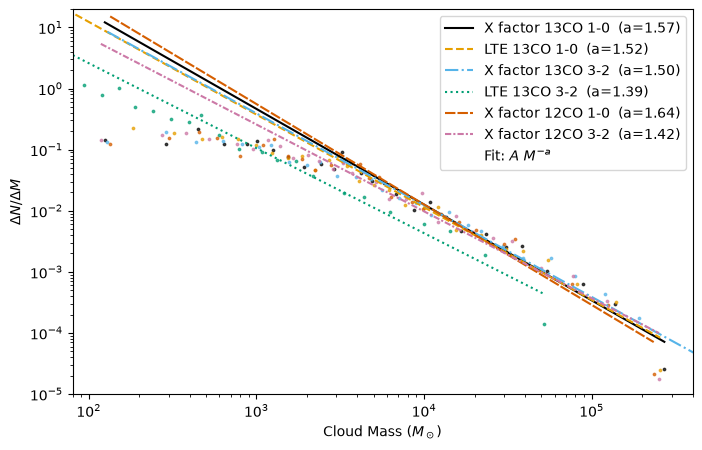

In [12]:
plt.figure(figsize=(8,5))

#col_labels = [
#    "M X 13CO 1-0",
#    "M LTE 13CO 1-0",
#    "M X 13CO 3-2",
#    "M X 12CO 1_0",
#    "M X 12CO 3_2",
#    "M LTE 13CO 3-2"
#]

col_labels = [
    'X factor 13CO 1-0',
    'LTE 13CO 1-0',
    'X factor 13CO 3-2',
    'LTE 13CO 3-2',
    'X factor 12CO 1-0',
    'X factor 12CO 3-2'
]

colors = [
    '#000000',  # black
    '#E69F00',  # orange
    '#56B4E9',  # sky blue
    '#009E73',  # bluish green
    '#D55E00',  # vermillion
    '#CC79A7'   # reddish purple
]

styles = [
    '-',                  # solid
    '--',                 # dashed
    '-.',                 # dash-dot
    ':',                  # dotted
    (0, (5, 1)),          # long dash
    (0, (3, 1, 1, 1))     # dash-dot-dot
]

for i in range(len(columns)):

    col = columns[i]
    col_label = col_labels[i]

    bin_medians, density = equal_count_mass_function(df[col])

    bin_medians_log = np.log10(bin_medians)

    # ---- Select high-mass tail ----
    start_index = start_indices[i]   # change if needed
   # start_index = 11 # original input fit for 13CO 1-0 X
    x_log = bin_medians_log[start_index:]
    y = density[start_index:]
    y_log = np.log10(y)

    # ---- Fit in log-log space ----
    coeffs, cov = np.polyfit(x_log, y_log, 1, cov=True)
    slope = coeffs[0]
    intercept = coeffs[1]

    m_err = np.sqrt(cov[0, 0])
    b_err = np.sqrt(cov[1, 1])


    a = slope
    A = 10**intercept

    # ---- Predicted values ----
    fit_y = A * (10**bin_medians_log)**(a)

    # ---- χ² (linear space) ----
    predicted_tail = A * (10**x_log)**(a)
    chi2 = np.sum((y - predicted_tail)**2 / predicted_tail)

    print(f"\nColumn: {col_label}")
    print(f"A = {A:.4e}")
    print(f"a = {a:.4f} ± {m_err:.4f}")
    print(f"χ² = {chi2:.4f}")

    # ---- Plot ----
    plt.scatter(bin_medians, density, alpha=0.7, s=3, color = colors[i])
    plt.plot(bin_medians, fit_y,
             linestyle=styles[i], color=colors[i],
             label=f"{col_label}  (a={-a:.2f})")


plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Cloud Mass $(M_\odot)$")
plt.ylim([0.00001, 20])
plt.xlim([80, 400000])
plt.ylabel(r"$\Delta N / \Delta M$")
plt.plot([], [], ' ', label='Fit: $A\ M^{-a}$')
plt.legend()
plt.grid(True, which="both", ls="", alpha=0.6)
#plt.savefig(destination_path + "6_power_laws.png")


Column: M_Sol_X 13CO 1-0
A      = 1.1974e-01
mu     = 2.5885
M_peak = 387.7477
sigma  = 0.6920
χ²     = 0.0760

Column: M_Sol 13CO 1-0 LTE
A      = 2.3255e-01
mu     = 1.9683
M_peak = 92.9652
sigma  = 0.8666
χ²     = 0.0463

Column: M_Sol_X 13CO 3-2
A      = 1.6384e-01
mu     = 2.4229
M_peak = 264.8185
sigma  = 0.6702
χ²     = 0.0642

Column: M_Sol_X 12CO 1-0
A      = 1.1708e-01
mu     = 2.6617
M_peak = 458.9292
sigma  = 0.6507
χ²     = 0.0675

Column: M_Sol_X 12CO 3-2
A      = 1.7145e-01
mu     = 2.4472
M_peak = 280.0399
sigma  = 0.6767
χ²     = 0.0397

Column: M_Sol 13CO 3-2 LTE
A      = 6.0553e+00
mu     = 0.3380
M_peak = 2.1778
sigma  = 0.7920
χ²     = 7.3489


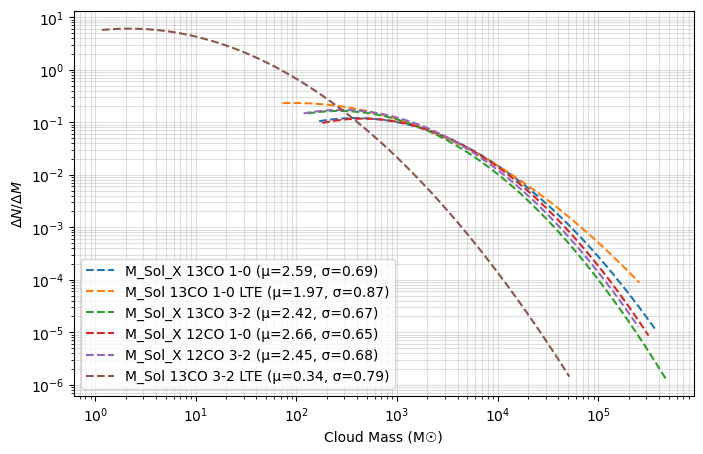

In [108]:
from scipy.optimize import curve_fit

# ---- Lognormal model ----
def lognormal_base10(M, A, mu, sigma):
    return A * np.exp(-(np.log10(M) - mu)**2 / (2 * sigma**2))


plt.figure(figsize=(8,5))

for col in columns:

    bin_medians, density = equal_count_mass_function(df[col])

    # Keep valid data
    valid = (bin_medians > 0) & (density > 0) & np.isfinite(density)
    M = bin_medians[valid]
    dndm = density[valid]

    # ---- Initial guess ----
    p0 = [max(dndm), np.log10(np.median(M)), 0.5]

    try:
        params, cov = curve_fit(lognormal_base10, M, dndm, p0=p0, maxfev=10000)
    except RuntimeError:
        print(f"Fit failed for {col}")
        continue

    A_fit, mu_fit, sigma_fit = params
    M_peak_fit = 10**mu_fit

    dndm_calc = lognormal_base10(M, *params)
    chi2 = np.sum((dndm - dndm_calc)**2 / dndm_calc)

    print(f"\nColumn: {col}")
    print(f"A      = {A_fit:.4e}")
    print(f"mu     = {mu_fit:.4f}")
    print(f"M_peak = {M_peak_fit:.4f}")
    print(f"sigma  = {sigma_fit:.4f}")
    print(f"χ²     = {chi2:.4f}")

    # ---- Plot data ----
   # plt.scatter(M, dndm, alpha=0.6)

    # ---- Smooth curve ----
    M_smooth = np.logspace(np.log10(M.min()), np.log10(M.max()), 500)
    fit_curve = lognormal_base10(M_smooth, *params)

    plt.plot(
        M_smooth, fit_curve, '--',
        label=f"{col} (μ={mu_fit:.2f}, σ={sigma_fit:.2f})"
    )


plt.xscale("log")
plt.yscale("log")
plt.xlabel("Cloud Mass (M☉)")
plt.ylabel(r"$\Delta N / \Delta M$")
plt.grid(True, which='both', alpha=0.4)
plt.legend()
plt.show()

In [19]:
df.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'pixel number 13CO 1-0', 'final_distance', 'distance_cm',
       'Mean_flux 13CO 1-0', 'density 13CO 1-0', 'M_Sol_X 13CO 1-0',
       'pixel number 13CO 1-0 COLTE', 'COLTE_Density 13O 1-0',
       'Mean_flux 13CO 1-0 COLTE', 'M_Sol 13CO 1-0 COLTE',
       'pixel number 13CO 3-2', 'Mean_flux 13CO 3-2', 'density 13CO 3-2',
       'M_Sol_X 13CO 3-2', 'pixel number 12CO 1_0', 'Mean_flux 12CO 1_0',
       'X_density 12CO 1_0', 'M_Sol_X 12CO 1_0', 'pixel number 12CO 3_2',
       'Mean_flux 12CO 3_2', 'X_density 12CO 3_2', 'M_Sol_X 12CO 3_2',
       'pixel number 13CO 3-2 COLTE', 'COLTE_Density 13CO 3-2',
       'Mean_flux 13CO 3-2 COLTE', 'M_Sol 13CO 3-2 COLTE'],
      dtype='object')

In [4]:
help(np.polyfit)

Help on _ArrayFunctionDispatcher in module numpy:

polyfit(x, y, deg, rcond=None, full=False, w=None, cov=False)
    Least squares polynomial fit.
    
    .. note::
       This forms part of the old polynomial API. Since version 1.4, the
       new polynomial API defined in `numpy.polynomial` is preferred.
       A summary of the differences can be found in the
       :doc:`transition guide </reference/routines.polynomials>`.
    
    Fit a polynomial ``p(x) = p[0] * x**deg + ... + p[deg]`` of degree `deg`
    to points `(x, y)`. Returns a vector of coefficients `p` that minimises
    the squared error in the order `deg`, `deg-1`, ... `0`.
    
    The `Polynomial.fit <numpy.polynomial.polynomial.Polynomial.fit>` class
    method is recommended for new code as it is more stable numerically. See
    the documentation of the method for more information.
    
    Parameters
    ----------
    x : array_like, shape (M,)
        x-coordinates of the M sample points ``(x[i], y[i])``.
    y 

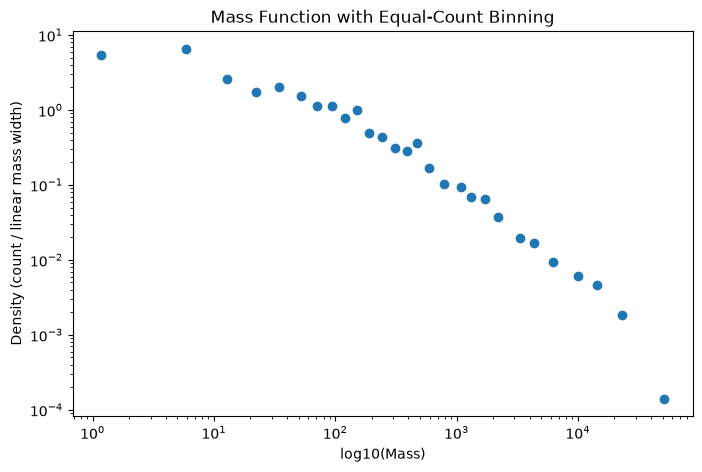

In [48]:
import math

# Load CSV
df = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
#df = pd.read_csv("FGN_13CO_037_047_vrms_3_masses_SNR0_plusleaves.csv")
#df = df[df['final_distance'] > 10 ]
#df = df[df['final_distance'] > 2]
#df = df[np.abs(df['v_cen']) > 10000]

col_name = "M_Sol 13CO 3-2 LTE" #This is for complete catalogue


# Filter positive masses
values = df[col_name]
values = values[values > 0].dropna().values

# Number of bins
N = len(values)
num_bins = math.ceil(2 * (N ** 0.4))   # same rule as before

# ----- 1. Sort values -----
sorted_vals = np.sort(values)

# ----- 2. Compute quantile bin edges (equal-count bins) -----
quantiles = np.linspace(0, 1, num_bins + 1)
bin_edges = np.quantile(sorted_vals, quantiles)

# Remove duplicate edges (can occur if many identical masses)
bin_edges = np.unique(bin_edges)

# Recompute num_bins in case duplicates removed
num_bins_actual = len(bin_edges) - 1

# ----- 3. Count values in each bin -----
counts = np.histogram(sorted_vals, bins=bin_edges)[0]

# ----- 4. Linear bin widths -----
bin_widths = bin_edges[1:] - bin_edges[:-1]

# ----- 5. Density = counts / linear width -----
density = counts / bin_widths

# ----- 6. Show values inside each bin -----
bin_values = []  # list of arrays, one per bin

for i in range(num_bins_actual):
    left = bin_edges[i]
    right = bin_edges[i+1]

    # include left edge, exclude right edge (like numpy histogram)
    mask = (sorted_vals >= left) & (sorted_vals < right)
    vals_in_bin = sorted_vals[mask]

    # for the LAST bin, include the right edge too:
    if i == num_bins_actual - 1:
        mask = (sorted_vals >= left) & (sorted_vals <= right)
        vals_in_bin = sorted_vals[mask]

    bin_values.append(vals_in_bin)

# ----- 7. Median of each bin -----
bin_medians = np.array([np.median(vals) for vals in bin_values])
#print(bin_medians)

#bin_centers = 0.5*(bin_edges[:-1] + bin_edges[1:])
#bin_centers_log = np.log10(bin_centers)

bin_medians_log = np.log10(bin_medians)


# ----- 8. Scatter plot -----
plt.figure(figsize=(8,5))
plt.scatter(bin_medians, density)
#plt.plot(bin_centers, density)

plt.xlabel("log10(Mass)")
plt.ylabel("Density (count / linear mass width)")
plt.title("Mass Function with Equal-Count Binning")
plt.yscale('log')
plt.xscale('log')
plt.show()

In [111]:
redist = pd.read_csv("/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X_FUGIN_Master_mass_catalogue_complete_redist.csv")  # Example CSV

expect = [2399, 3185, 2783, 2581, 8069, 15106, 3128, 5293, 9279, 12240, 1581]

for idx_val in expect:
    mask = redist['_idx'] == idx_val

    redist.loc[mask, 'mass_mod'] = (
        redist.loc[mask, 'd_near'] /
        redist.loc[mask, 'final_distance']
    )

    redist.loc[mask, 'M_Sol_X 13CO 1-0'] = (
        redist.loc[mask, 'M_Sol_X 13CO 1-0'] *
        redist.loc[mask, 'mass_mod'] ** 2
    )

    redist.loc[mask, 'final_distance'] = (
        redist.loc[mask, 'final_distance'] *
        redist.loc[mask, 'mass_mod']
    )

    redist.loc[mask, 'distance_cm'] = (
        redist.loc[mask, 'distance_cm'] *
        redist.loc[mask, 'mass_mod']
    )

    redist.loc[mask, 'M_Sol 13CO 1-0 COLTE'] = (
        redist.loc[mask, 'M_Sol 13CO 1-0 COLTE'] *
        redist.loc[mask, 'mass_mod'] ** 2
    )

    redist.loc[mask, 'M_Sol_X 13CO 3-2'] = (
        redist.loc[mask, 'M_Sol_X 13CO 3-2'] *
        redist.loc[mask, 'mass_mod'] ** 2
    )

    redist.loc[mask, 'M_Sol_X 12CO 1_0'] = (
        redist.loc[mask, 'M_Sol_X 12CO 1_0'] *
        redist.loc[mask, 'mass_mod'] ** 2
    )

    redist.loc[mask, 'M_Sol_X 12CO 3_2'] = (
        redist.loc[mask, 'M_Sol_X 12CO 3_2'] *
        redist.loc[mask, 'mass_mod'] ** 2
    )

    redist.loc[mask, 'M_Sol 13CO 3-2 COLTE'] = (
        redist.loc[mask, 'M_Sol 13CO 3-2 COLTE'] *
        redist.loc[mask, 'mass_mod'] ** 2
    )

KeyError: 'M_Sol_X 12CO 1_0'

In [57]:
redist ## pre-2.72

,Universal_ID,_idx,position_angle,v_cen,v_rms,x_cen,y_cen,sigv_kms,major_arcsec,minor_arcsec,...,M_Sol_X 12CO 1_0,pixel number 12CO 3_2,Mean_flux 12CO 3_2,X_density 12CO 3_2,M_Sol_X 12CO 3_2,pixel number 13CO 3-2 COLTE,COLTE_Density 13CO 3-2,Mean_flux 13CO 3-2 COLTE,M_Sol 13CO 3-2 COLTE,mass_mod
0,1.0,23.0,-153.3,121215.69,4.18,19.636,0.061,2.09,463.3,185.4,...,83600.0,24256.0,5.09,2.140000e+21,68700.0,8192.0,1.370000e+19,1.64,16926.000,NaN
1,2.0,58.0,51.3,120036.92,2.85,21.553,-0.113,1.43,146.5,86.1,...,27300.0,5920.0,11.39,4.780000e+21,26100.0,2664.0,5.010000e+18,3.61,4297.000,NaN
2,3.0,71.0,159.8,121537.93,4.02,19.045,0.101,2.01,425.0,93.3,...,14400.0,8006.0,1.95,8.200000e+20,8780.0,410.0,3.130000e+17,0.44,390.000,NaN
3,4.0,187.0,164.3,116577.30,5.12,22.590,0.349,2.56,120.9,87.9,...,5040.0,2423.0,2.24,9.400000e+20,2930.0,48.0,4.430000e+16,0.53,53.000,NaN
4,5.0,336.0,166.5,116260.00,4.73,20.375,-0.108,2.37,407.0,276.7,...,74000.0,24519.0,3.40,1.430000e+21,47400.0,2718.0,5.480000e+18,1.35,6891.000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
706,707.0,90.0,-138.0,86917.52,5.24,36.882,0.311,2.62,249.3,152.1,...,5960.0,8836.0,2.57,1.030000e+21,4040.0,3138.0,2.710000e+18,0.69,1116.000,NaN
707,708.0,269.0,170.7,79983.36,3.29,36.915,-0.095,1.64,494.0,228.1,...,48300.0,25821.0,6.64,2.660000e+21,35900.0,16420.0,2.000000e+19,1.45,9765.000,NaN
708,709.0,963.0,78.2,48941.35,6.00,37.015,0.140,3.00,122.5,90.5,...,742.0,3077.0,3.23,1.290000e+21,533.0,553.0,2.590000e+17,0.37,32.271,NaN
709,710.0,1523.0,47.4,14676.76,3.02,36.903,0.178,1.51,269.8,146.3,...,18000.0,9740.0,1.17,4.680000e+20,10400.0,716.0,4.490000e+17,0.27,957.900,NaN


In [58]:
redist['M_Sol_X 13CO 1-0'] = redist['M_Sol_X 13CO 1-0'] * 2.72 / 2.33
redist['M_Sol_X 13CO 3-2'] = redist['M_Sol_X 13CO 3-2'] * 2.72 / 2.33
redist['M_Sol_X 12CO 1_0'] = redist['M_Sol_X 12CO 1_0'] * 2.72 / 2.33
redist['M_Sol_X 12CO 3_2'] = redist['M_Sol_X 12CO 3_2'] * 2.72 / 2.33
redist['M_Sol 13CO 1-0 COLTE'] = redist['M_Sol 13CO 1-0 COLTE'] * 2.72 / 2.33
redist['M_Sol 13CO 3-2 COLTE'] = redist['M_Sol 13CO 3-2 COLTE'] * 2.72 / 2.33

In [59]:
redist

,Universal_ID,_idx,position_angle,v_cen,v_rms,x_cen,y_cen,sigv_kms,major_arcsec,minor_arcsec,...,M_Sol_X 12CO 1_0,pixel number 12CO 3_2,Mean_flux 12CO 3_2,X_density 12CO 3_2,M_Sol_X 12CO 3_2,pixel number 13CO 3-2 COLTE,COLTE_Density 13CO 3-2,Mean_flux 13CO 3-2 COLTE,M_Sol 13CO 3-2 COLTE,mass_mod
0,1.0,23.0,-153.3,121215.69,4.18,19.636,0.061,2.09,463.3,185.4,...,97593.133047,24256.0,5.09,2.140000e+21,80199.141631,8192.0,1.370000e+19,1.64,19759.107296,NaN
1,2.0,58.0,51.3,120036.92,2.85,21.553,-0.113,1.43,146.5,86.1,...,31869.527897,5920.0,11.39,4.780000e+21,30468.669528,2664.0,5.010000e+18,3.61,5016.240343,NaN
2,3.0,71.0,159.8,121537.93,4.02,19.045,0.101,2.01,425.0,93.3,...,16810.300429,8006.0,1.95,8.200000e+20,10249.613734,410.0,3.130000e+17,0.44,455.278970,NaN
3,4.0,187.0,164.3,116577.30,5.12,22.590,0.349,2.56,120.9,87.9,...,5883.605150,2423.0,2.24,9.400000e+20,3420.429185,48.0,4.430000e+16,0.53,61.871245,NaN
4,5.0,336.0,166.5,116260.00,4.73,20.375,-0.108,2.37,407.0,276.7,...,86386.266094,24519.0,3.40,1.430000e+21,55333.905579,2718.0,5.480000e+18,1.35,8044.429185,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
706,707.0,90.0,-138.0,86917.52,5.24,36.882,0.311,2.62,249.3,152.1,...,6957.596567,8836.0,2.57,1.030000e+21,4716.223176,3138.0,2.710000e+18,0.69,1302.798283,NaN
707,708.0,269.0,170.7,79983.36,3.29,36.915,-0.095,1.64,494.0,228.1,...,56384.549356,25821.0,6.64,2.660000e+21,41909.012876,16420.0,2.000000e+19,1.45,11399.484979,NaN
708,709.0,963.0,78.2,48941.35,6.00,37.015,0.140,3.00,122.5,90.5,...,866.197425,3077.0,3.23,1.290000e+21,622.214592,553.0,2.590000e+17,0.37,37.672584,NaN
709,710.0,1523.0,47.4,14676.76,3.02,36.903,0.178,1.51,269.8,146.3,...,21012.875536,9740.0,1.17,4.680000e+20,12140.772532,716.0,4.490000e+17,0.27,1118.235193,NaN


In [54]:
redist.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'pixel number 13CO 1-0', 'final_distance', 'distance_cm',
       'Mean_flux 13CO 1-0', 'density 13CO 1-0', 'M_Sol_X 13CO 1-0',
       'pixel number 13CO 1-0 COLTE', 'COLTE_Density 13O 1-0',
       'Mean_flux 13CO 1-0 COLTE', 'M_Sol 13CO 1-0 COLTE',
       'pixel number 13CO 3-2', 'Mean_flux 13CO 3-2', 'density 13CO 3-2',
       'M_Sol_X 13CO 3-2', 'pixel number 12CO 1_0', 'Mean_flux 12CO 1_0',
       'X_density 12CO 1_0', 'M_Sol_X 12CO 1_0', 'pixel number 12CO 3_2',
       'Mean_flux 12CO 3_2', 'X_density 12CO 3_2', 'M_Sol_X 12CO 3_2',
       'pixel number 13CO 3-2 COLTE', 'COLTE_Density 13CO 3-2',
       'Mean_flux 13CO 3-2 COLTE', 'M_Sol 13CO 3-2 COLTE', 'mass_mod'],
      dtype='object')

In [55]:
redist['M_Sol_X 13CO 1-0']

0      534537.559399
1      127589.024595
2       95612.224166
3       30704.091954
4      342040.402592
           ...      
706     31658.623310
707    291132.063601
708      3213.588899
709    112793.788576
710              NaN
Name: M_Sol_X 13CO 1-0, Length: 711, dtype: float64

In [61]:
redist.to_csv("/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X_FUGIN_Master_mass_catalogue_complete_redist_272.csv", index= False)

In [22]:
mass = df_2['M_Sol_X 13CO 1-0']
distance_cm = df_2['final_distance'] * 3.086 * pow(10,21)

semi_major_deg= df_2['major_arcsec'] / 3600  # Divide by 3600 to turns out these are semis!
semi_minor_deg= df_2['minor_arcsec'] / 3600
semi_major_cm = semi_major_deg * distance_cm * np.pi / 180 * 2.354
semi_minor_cm = semi_minor_deg * distance_cm * np.pi / 180 * 2.354


rad_pc= (semi_major_cm/3.086E18*semi_minor_cm/3.086E18)**(1/2)
surface_density = mass / np.pi / rad_pc ** 2

In [27]:
rad_pc.min()

0.4225735266812106

(array([205., 202., 123.,  55.,  33.,  30.,  19.,  18.,   4.,   8.]),
 array([ 0.21128676,  2.14421662,  4.07714647,  6.01007632,  7.94300618,
         9.87593603, 11.80886588, 13.74179573, 15.67472559, 17.60765544,
        19.54058529]),
 <BarContainer object of 10 artists>)

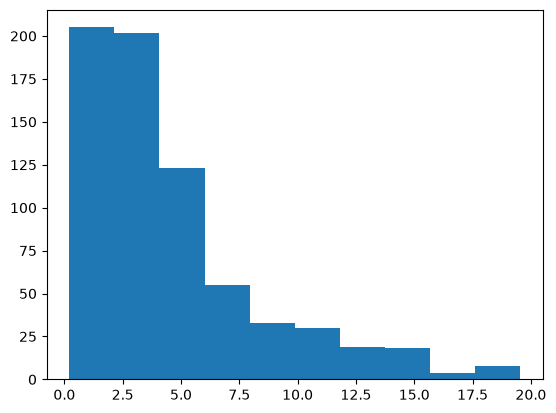

In [51]:
plt.hist(rad_pc[rad_pc<20])

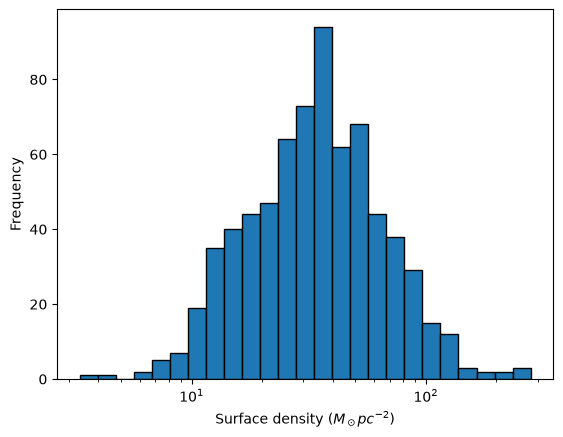

In [23]:
destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"

bins = np.logspace(
    np.log10(surface_density.min()),
    np.log10(surface_density.max()),
    int(np.sqrt(len(surface_density)))
)

plt.hist(surface_density, bins=bins, edgecolor='k')
plt.xscale('log')

plt.xlabel(r'Surface density ($M_\odot pc^{-2}$)')
plt.ylabel('Frequency')

plt.savefig(destination_path + "Surface_density_histogram_new.png")

In [21]:
params = {
    'Mass': m,
    'Radius (pc)': rad_pc,
    'Velocity width': v_fwhm ,
    'Surface density': surface_density
}

# build table
stats_table = pd.DataFrame({
    'Mean':   [np.nanmean(v) for v in params.values()],
    'Median': [np.nanmedian(v) for v in params.values()],
    'Max':    [np.nanmax(v) for v in params.values()],
    'Min':    [np.nanmin(v) for v in params.values()],
    'Std':    [np.nanstd(v) for v in params.values()],
}, index=params.keys())

print(stats_table.round(2))

                     Mean   Median         Max    Min       Std
Mass             29852.17  4460.67  1220466.06  22.32  81792.36
Radius (pc)         10.23     6.96      112.66   0.42     10.61
Velocity width       4.98     4.20       19.59   2.99      2.32
Surface density     42.10    34.52      279.70   3.33     32.04


11.29


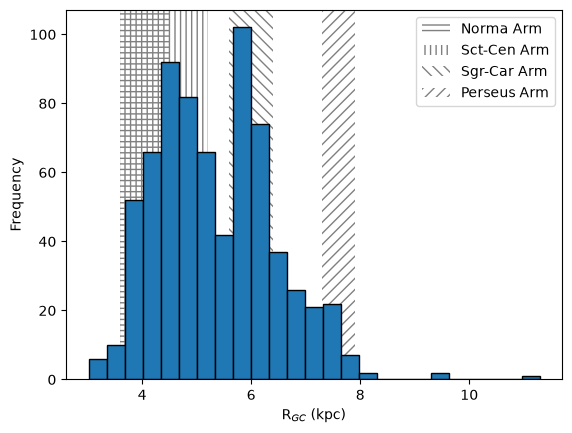

In [53]:
#destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
df = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
#df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/Mopra_Cloud_Mass_Catalogue_Fullinfo.csv')



d = df_2['R_GC'][df_2['R_GC']<100].dropna()

bins = np.linspace(
    d.min(),
    d.max(),
    int(np.sqrt(len(d)))
)

plt.hist(d, bins=bins, edgecolor='k')
#plt.xscale('log')

plt.xlabel(r'R$_{GC}$ (kpc)')
plt.ylabel('Frequency')
#plt.xlim([0,13])
plt.axvspan(3.6, 4.5, facecolor='none',
            edgecolor='gray', hatch='---',
            linewidth=0, zorder=0, label = 'Norma Arm')
plt.axvspan(3.6, 5.2, facecolor='none',
            edgecolor='gray', hatch='|||',
            linewidth=0, zorder=0, label = 'Sct-Cen Arm')
plt.axvspan(5.6, 6.4, facecolor='none',
            edgecolor='gray', hatch='\\\\\\',
            linewidth=0, zorder=0, label = 'Sgr-Car Arm')
plt.axvspan(7.3, 7.9, facecolor='none',
            edgecolor='gray', hatch='///',
            linewidth=0, zorder=0, label = "Perseus Arm")
plt.legend()


print(d.max())

#plt.savefig(destination_path + "RGC_histogram_shaded.png")
#plt.savefig("/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/RGC_histogram_shaded.png")

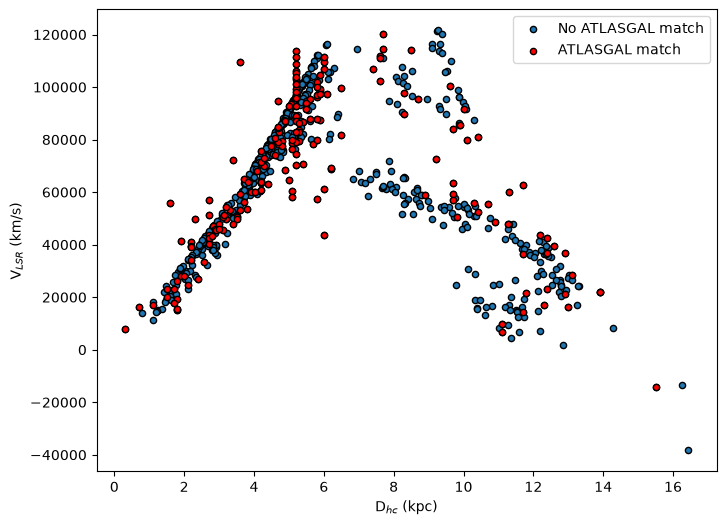

In [140]:
df = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

d = df_2['final_distance']
v = df_2['v_cen']

# mask
match = df_2['has_match'] == True

plt.figure(figsize=(8,6))

# all points
plt.scatter(
    d,
    v,
    edgecolor='k',
    s=20,
    #alpha=0.5,
    label='No ATLASGAL match'
)

# highlighted matched points
plt.scatter(
    d[match],
    v[match],
    color='red',
    edgecolor='k',
    s=20,
    label='ATLASGAL match'
)

plt.xlabel(r'D$_{hc}$ (kpc)')
plt.ylabel(r'V$_{LSR}$ (km/s)')

plt.legend()

#plt.savefig(destination_path + 'Rotation_curve.png', dpi=300, bbox_inches='tight')

plt.show()

In [141]:
v_tang = np.zeros(len(df_2))
w_w0 = np.zeros(len(df_2))
d_tang = np.zeros(len(df_2))

#l = df_2[x_cen]

def sine(angle):
    return np.sin(angle*np.pi/180)

a1 = 1.0077
a2 = 0.0394
a3 = 0.0071

for i in range(len(df_2)):
    w_w0[i] = a1 * np.abs(sine(df_2['x_cen'][i])) ** (a2 - 1) + a3 / np.abs(sine(df_2['x_cen'][i]))
    v_tang[i] = (w_w0[i] - 1) * 220 * sine(df_2['x_cen'][i]) * 1000
    d_tang[i] = 8.5 * sine(df_2['x_cen'][i])

In [142]:
count = 0
for i in range(len(df_2)):
    if np.abs(df['v_cen'][i] - v_tang[i]) < 10000:
        if abs(d_tang[i]-df_2['final_distance'][i]) > 1:
            count = count + 1

print(count/len(df_2))
print(count)

0.08732394366197183
62


KstestResult(statistic=np.float64(0.06619718309859154), pvalue=np.float64(0.08907399283549436), statistic_location=np.float64(3115.8592274678113), statistic_sign=np.int8(-1))


Text(0.5, 1.0, 'Mass correlation, pre-voxel equalisation')

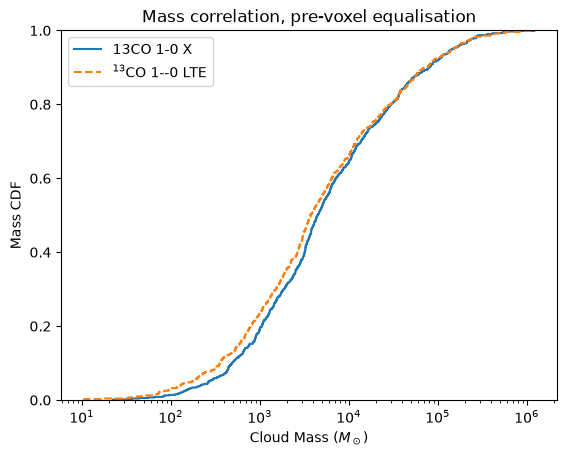

In [31]:
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
m = df_2['M_Sol_X 13CO 1-0'].dropna()

mass_options = {
    2: {
        "column": "M_Sol 13CO 1-0 LTE",
        "label": r"$^{13}$CO 1--0 LTE",
        "pixels": "pixel number 13CO 1-0 LTE"
    },
    3: {
        "column": "M_Sol_X 13CO 3-2",
        "label": r"$^{13}$CO 3--2 X-factor",
        "pixels": "pixel number 13CO 3-2"
    },
    4: {
        "column": "M_Sol_X 12CO 1-0",
        "label": r"$^{12}$CO 1--0 X-factor",
        "pixels": "pixel number 12CO 1-0"
    },
    5: {
        "column": "M_Sol_X 12CO 3-2",
        "label": r"$^{12}$CO 3--2 X-factor",
        "pixels": "pixel number 12CO 3-2"
    },
    6: {
        "column": "M_Sol 13CO 3-2 LTE",
        "label": r"$^{13}$CO 3--2 LTE",
        "pixels": "pixel number 13CO 3-2 LTE"
    }
}

selection = 2
m2 = df_2[mass_options[selection]["column"]].dropna()
label = mass_options[selection]["label"]

m = df_2['M_Sol_X 13CO 1-0'].dropna()
#pixel_correction = df_2[mass_options[selection]["pixels"]].dropna() / df_2["pixel number 13CO 1-0"]
#m = m* pixel_correction


print(stats.kstest(m, m2))

ax = sns.ecdfplot(
    m,
    log_scale=True,
    label='13CO 1-0 X',
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label=label,
    linestyle='--',
    ax=ax
)

plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
plt.title("Mass correlation, pre-voxel equalisation")

In [155]:
m_sort = np.array(m)
m_sort.sort()

In [156]:
n = len(m_sort)
m_sort[int(n/2)-1]

np.float64(4444.088148)

In [165]:
lim = 50


buff = int(lim*n/200)


print(m_sort[int(n/2-lim*n/200)])
print(int(n/2-lim*n/200))
print(m_sort[int(n/2)+buff-1])
print(int(n/2+lim*n/200))

1386.29037
177
20164.22222
532


In [339]:
m_sort[354]

5999.519

In [366]:
q16, q84 = np.percentile(m, [16, 84])

In [367]:
q16

1176.9802

In [368]:
q84

53082.31399999998

In [354]:
help(np.percentile)

Help on _ArrayFunctionDispatcher in module numpy:

percentile(a, q, axis=None, out=None, overwrite_input=False, method='linear', keepdims=False, *, interpolation=None)
    Compute the q-th percentile of the data along the specified axis.
    
    Returns the q-th percentile(s) of the array elements.
    
    Parameters
    ----------
    a : array_like of real numbers
        Input array or object that can be converted to an array.
    q : array_like of float
        Percentage or sequence of percentages for the percentiles to compute.
        Values must be between 0 and 100 inclusive.
    axis : {int, tuple of int, None}, optional
        Axis or axes along which the percentiles are computed. The
        default is to compute the percentile(s) along a flattened
        version of the array.
    
        .. versionchanged:: 1.9.0
            A tuple of axes is supported
    out : ndarray, optional
        Alternative output array in which to place the result. It must
        have the 

In [51]:
df_2.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'pixel number 13CO 1-0', 'final_distance', 'distance_cm',
       'Mean_flux 13CO 1-0', 'density 13CO 1-0', 'M_Sol_X 13CO 1-0',
       'pixel number 13CO 1-0 LTE', 'LTE_Density 13O 1-0',
       'Mean_flux 13CO 1-0 LTE', 'M_Sol 13CO 1-0 LTE', 'pixel number 13CO 3-2',
       'Mean_flux 13CO 3-2', 'density 13CO 3-2', 'M_Sol_X 13CO 3-2',
       'pixel number 12CO 1-0', 'Mean_flux 12CO 1-0', 'X_density 12CO 1-0',
       'M_Sol_X 12CO 1-0', 'pixel number 12CO 3-2', 'Mean_flux 12CO 3-2',
       'X_density 12CO 3-2', 'M_Sol_X 12CO 3-2', 'pixel number 13CO 3-2 LTE',
       'LTE_Density 13CO 3-2', 'Mean_flux 13CO 3-2 LTE', 'M_Sol 13CO 3-2 LTE'],
      dtype='str')

In [55]:
Mass_ratio_corrected = df_2['M_Sol_X 13CO 1-0'] / df_2['M_Sol 13CO 3-2 LTE'] / df_2['pixel number 13CO 1-0'] * df_2['pixel number 13CO 3-2 LTE']

8.814952959177019


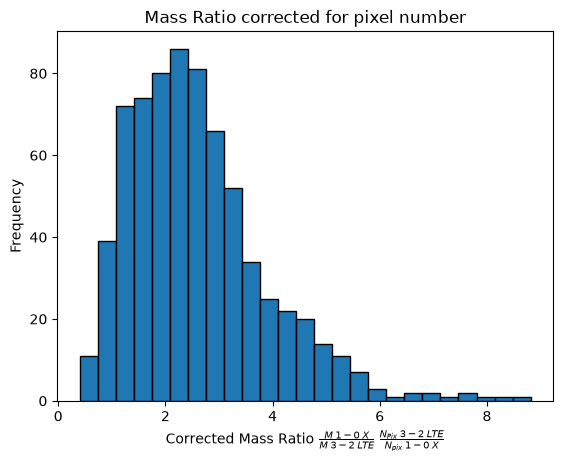

In [65]:
bins = np.linspace(
    Mass_ratio_corrected.min(),
    Mass_ratio_corrected.max(),
    int(np.sqrt(len(Mass_ratio_corrected)))
)

plt.hist(Mass_ratio_corrected, bins=bins, edgecolor='k')
#plt.xscale('log')

plt.xlabel(r'Modified_FGN_mass_13_3-2_LTE_voxels.pngMass Ratio $\frac{M\;1-0\;X}{M\;3-2\;LTE} \;\frac{N_{Pix}\;3-2\;LTE}{N_{pix}\;1-0\;X}$')
plt.ylabel('Frequency')
plt.title(r'Mass Ratio corrected for pixel number')

print(Mass_ratio_corrected.max())
#plt.savefig(destination_path +'13CO_3-2_LTE_Mass_ratio_corrected.png')

2.8639230613245004


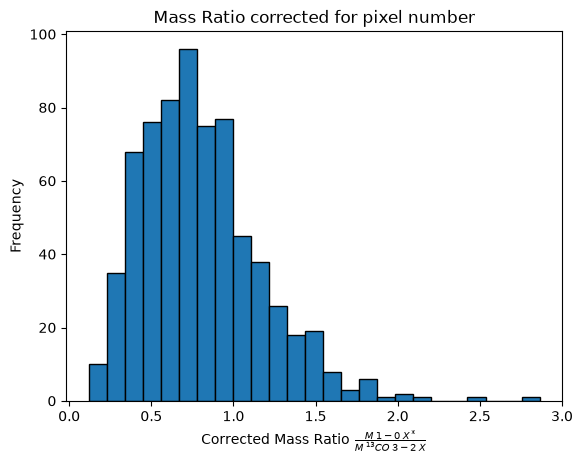

In [35]:
df_3 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_13CO_017_047_X-factor_masses_3-2_13_voxels.CSV')
#equal_ratio = df_3['M_pixel_Sol'] / df_3['M_COLTE_Sol_CO'] / 930000

matched = (
    df_3[['_idx', 'x_cen', 'M_pixel_Sol']]
    .merge(
        df_2[['_idx', 'x_cen', 'M_Sol_X 13CO 3-2']],
        on=['_idx', 'x_cen'],
        how='inner',
        validate='one_to_one'   # optional but recommended
    )
)

#matched['equal_ratio'] = (
#    matched['M_pixel_Sol']/
#    matched['M_Sol_X 13CO 3-2']
#)

equal_ratio = matched['M_pixel_Sol'] / matched['M_Sol_X 13CO 3-2']
equal_ratio = equal_ratio[equal_ratio<3]

bins = np.linspace(
    equal_ratio.min(),
    equal_ratio.max(),
    int(np.sqrt(len(equal_ratio)))
)


plt.hist(equal_ratio, bins=bins, edgecolor='k')
#plt.xscale('log')

plt.xlabel(r'Corrected Mass Ratio $\frac{M\;1-0\;X^*}{M\;^{13}CO\;3-2\;X}$')
plt.ylabel('Frequency')
plt.title(r'Mass Ratio corrected for pixel number')

print(equal_ratio.max())
#plt.savefig(destination_path +'13CO_1-0_X_13_1-0_LTE_voxels.png')

KstestResult(statistic=np.float64(0.08869814020028613), pvalue=np.float64(0.008152555634931223), statistic_location=np.float64(3110.0), statistic_sign=np.int8(1))


Text(0, 0.5, 'Mass CDF')

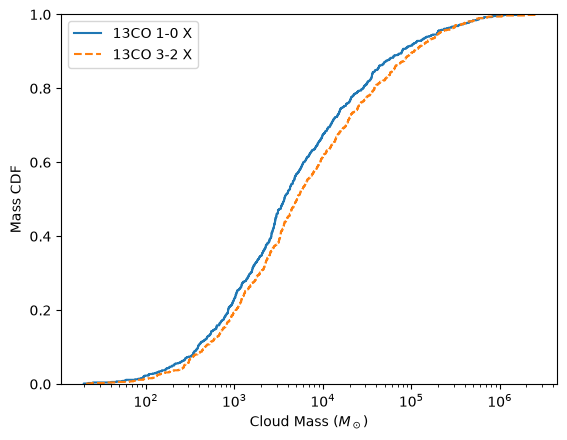

In [36]:
m = matched['M_pixel_Sol'].dropna()

m2 = matched['M_Sol_X 13CO 3-2'].dropna()
#pixel_correction = df_2[mass_options[selection]["pixels"]].dropna() / df_2["pixel number 13CO 1-0"]
#m = m* pixel_correction

#m = df_3['M_pixel_Sol'].dropna()
#m2 = df_3['M_COLTE_Sol_CO'].dropna() * 930000  # this is used in COLTE runs to replicate the notes in journal, see 13/07 for details.

print(stats.kstest(m, m2))

ax = sns.ecdfplot(
    m,
    log_scale=True,
    label='13CO 1-0 X',
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label="13CO 3-2 X",
    linestyle='--',
    ax=ax
)

plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
#plt.title('
#plt.savefig(destination_path + "12CO_3-2_X_mass_corrected_KSTest.png")

In [206]:
len(matched)

699

In [217]:
df_3.columns

Index(['Universal_ID', '_idx', 'area_ellipse', 'area_exact', 'major_sigma',
       'minor_sigma', 'position_angle', 'radius', 'v_cen', 'v_rms', 'x_cen',
       'y_cen', 'radius_arcsec', 'sigv_kms', 'xcens', 'ycens', 'vcens',
       'major_arcsec', 'minor_arcsec', 'parent', 'ancestor', 'n_leaves',
       'structure_type', 'idx', 'has_match', 'AGAL_distance', 'R_GC', 'd_near',
       'd_far', 'distance', 'dist_method', 'distance_flag', 'final_distance',
       'total_flux', 'pixel_number', 'COLTE_Density', 'distance_cm',
       'Mean_flux', 'density', 'semi_major_deg', 'semi_minor_deg',
       'semi_major_cm', 'semi_minor_cm', 'NH2_ellipse', 'M_ellipse_g',
       'angular_size_sr', 'area_cm2_pixel_method', 'NH2_pixel', 'M_pixel_g',
       'M_ellipse_Sol', 'M_pixel_Sol', 'M_COLTE_Sol_CO'],
      dtype='str')

In [246]:
matched.columns

Index(['_idx', 'x_cen', 'M_pixel_Sol', 'M_Sol 13CO 3-2 LTE', 'equal_ratio'], dtype='str')

m = 0.9265327525797216*m2 + 0.3450266792950709
2.964856043237911
KstestResult(statistic=np.float64(0.06619718309859154), pvalue=np.float64(0.08907399283549436), statistic_location=np.float64(3115.8592274678113), statistic_sign=np.int8(-1))


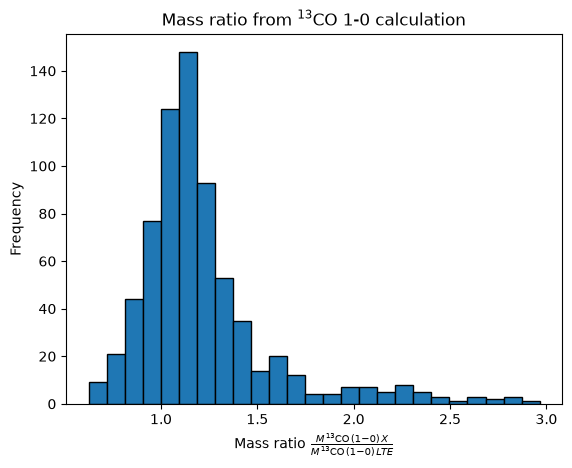

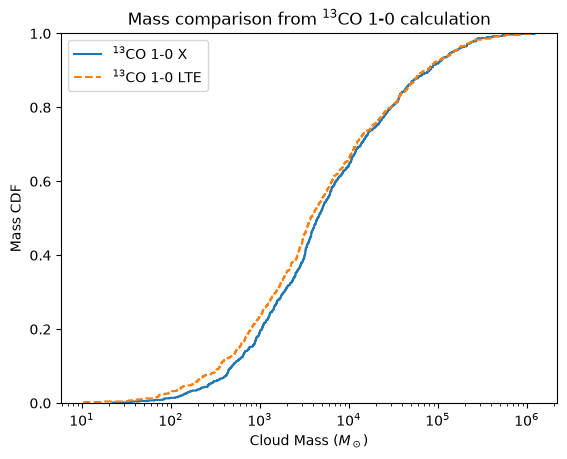

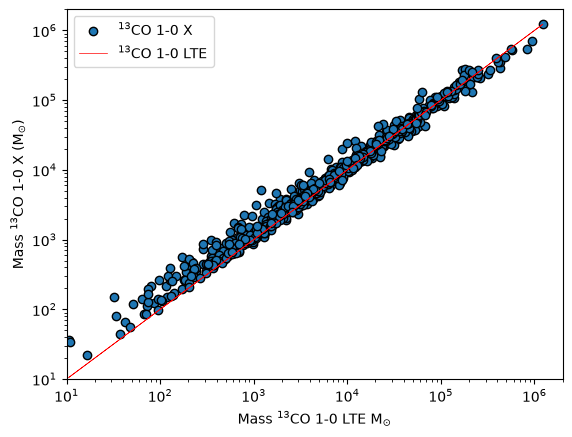

In [105]:
## Comparing to 13CO 1-0 X from original catalogue, no pixel changes. This is the "catalogue" statistic in Raf
## notes of 13/07/2026 and the old statistic in the 13CO 1-0 comparison at the start of 13/07/2026.
## JUST the statistics, NOT the plots! I don't think these plots exist anywhere.
## Cell 1


destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')
saveplot = False

mode = 2


m = df_2['M_Sol_X 13CO 1-0'].dropna()


m2_col = {
    1: "M_Sol_X 13CO 1-0",
    2: "M_Sol 13CO 1-0 LTE",
    3: 'M_Sol 13CO 3-2 LTE',
    4: 'M_Sol_X 12CO 1-0',
    5: 'M_Sol_X 13CO 3-2',
    6: 'M_Sol_X 12CO 3-2'
}

m2 = df_2[m2_col[mode]].dropna()
mask = (m>0) & (m2 >0)

m  = m[mask]
m2 = m2[mask]

coeffs = np.polyfit(np.log10(m2), np.log10(m), 1)
slope = coeffs[0]
intercept = coeffs[1]
print(f"m = {slope}*m2 + {intercept}")


equal_ratio = m / m2
equal_ratio = equal_ratio[equal_ratio<3]

bins = np.linspace(
    equal_ratio.min(),
    equal_ratio.max(),
    int(np.sqrt(len(equal_ratio)))
)


plt.hist(equal_ratio, bins=bins, edgecolor='k')
#plt.xscale('log')

xlabel = {
    1: r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}$",
    2: r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,LTE}$",
    3: r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(3\!-\!2)\,LTE}$",
    4: r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{12}\mathrm{CO}\,(1\!-\!0)\,X}$",
    5: r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(3\!-\!2)\,X}$",
    6: r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{12}\mathrm{CO}\,(3\!-\!2)\,X}$",
}


plt.xlabel(f'Mass ratio {xlabel[mode]}')
plt.ylabel('Frequency')
plt.title(r'Mass ratio from $^{13}$CO 1-0 calculation')


print(equal_ratio.max())


plottitles = {
    1 : destination_path +'13CO_1-0_X_13CO_1-0_X.png',
    2 : destination_path +'13CO_1-0_X_13CO_1-0_LTE.png',
    3 : destination_path +'13CO_1-0_X_13CO_3-2_LTE.png',
    4 : destination_path +'13CO_1-0_X_12CO_1-0_X.png',
    5 : destination_path +'13CO_1-0_X_13CO_3-2_X.png',
    6 : destination_path +'13CO_1-0_X_12CO_3-2_X.png'
}

if saveplot == True:
    plt.savefig(plottitles[mode])

print(stats.kstest(m, m2))

labels = {
    1 : r"$^{13}$CO 1-0 X",
    2 : r"$^{13}$CO 1-0 LTE",
    3 : r"$^{13}$CO 3-2 LTE",
    4 : r"$^{12}$CO 1-0 X",
    5 : r"$^{13}$CO 3-2 X",
    6 : r"$^{12}$CO 3-2 X"
}

axlabels = {
    1 : r"Mass $^{13}$CO 1-0 X M$_{\odot}$",
    2 : r"Mass $^{13}$CO 1-0 LTE M$_{\odot}$",
    3 : r"Mass $^{13}$CO 3-2 LTE M$_{\odot}$",
    4 : r"Mass $^{12}$CO 1-0 X M$_{\odot}$",
    5 : r"Mass $^{13}$CO 3-2 X M$_{\odot}$",
    6 : r"Mass $^{12}$CO 3-2 X M$_{\odot}$"
}

KStitles = {
    1 : destination_path + "13CO_1-0_X_KSTest.png",
    2 : destination_path + "13CO_1-0_LTE_KSTest.png",
    3 : destination_path + "13CO_3-2_LTE_KSTest.png",
    4 : destination_path + "12CO_1-0_X_KSTest.png",
    5 : destination_path + "13CO_3-2_X_KSTest.png",
    6 : destination_path + "12CO_3-2_X_KSTest.png"
}

scattertitles = {
    1 : destination_path + "Mass_comparison_13CO_10_X.png",
    2 : destination_path + "Mass_comparison_13CO_10_LTE.png",
    3 : destination_path + "Mass_comparison_13CO_32_LTE.png",
    4 : destination_path + "Mass_comparison_12CO_10_X.png",
    5 : destination_path + "Mass_comparison_13CO_32_X.png",
    6 : destination_path + "Mass_comparison_12CO_32_X.png"
}
      
plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label=labels[1],
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label=labels[mode],
    linestyle='--',
    ax=ax
)
plt.title(r'Mass comparison from $^{13}$CO 1-0 calculation')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
axlabel = axlabels[mode]

if saveplot == True:
    plt.savefig(KStitles[mode])

plt.figure()
plt.scatter(
    m2,
    m,
    edgecolor='k',
    label = labels[1])
plt.plot(
    m2,
    m2,
    color='red',
    label = labels[mode],
    linewidth = 0.5
)
plt.ylabel('Mass $^{13}$CO 1-0 X (M$_{\odot}$)')
plt.xlabel(axlabel)
plt.xscale('log')
plt.yscale('log')
plt.xlim([10, 2000000])
plt.ylim([10, 2000000])
plt.legend()
if saveplot == True:
    plt.savefig(scattertitles[mode])

## Cell 1

2.110244626382027
KstestResult(statistic=np.float64(0.027777777777777776), pvalue=np.float64(0.9547329670769064), statistic_location=np.float64(35713.24114), statistic_sign=np.int8(-1))
m = 1.0161788176798345*m2 + -0.04276713421938109


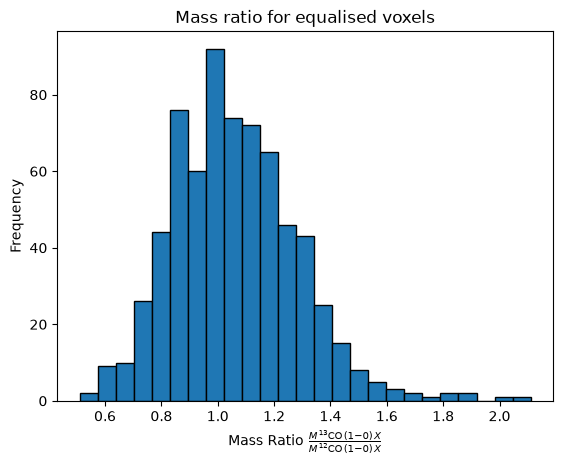

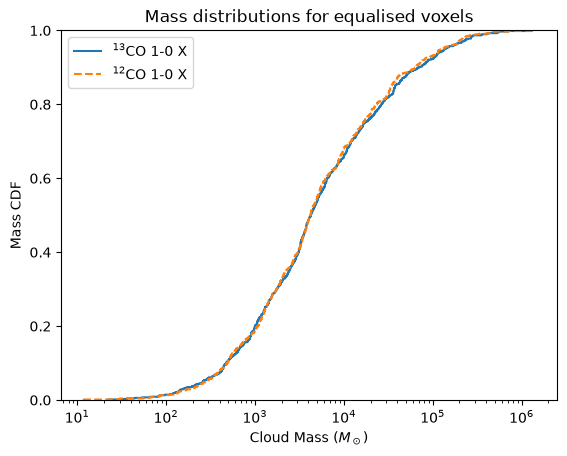

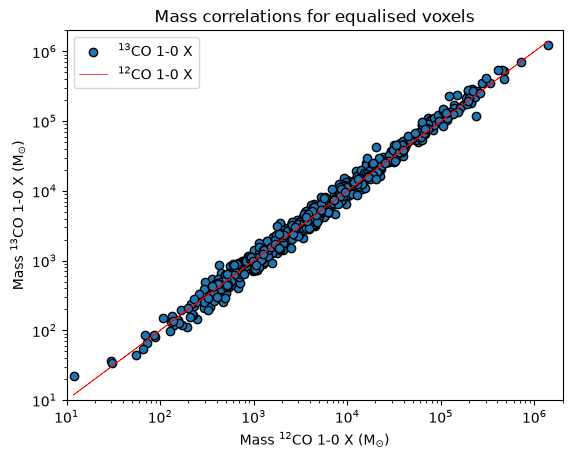

In [55]:
## Comparing to 13CO 1-0 X with specified voxels. This should be plots and new statistics from 13/07/2026
## These plots appear on the paper
## This is comparing columns from the catalogue with FGN 13CO mass calculated with reduced voxels.
## Full region, no Raf test or anything
# Cell 2

destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
saveplot = False

df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv')

mass_options = {
    1 : {
        "m2_col": "M_Sol_X 13CO 1-0",
        "df3": "CHIMPS_X2_FUGIN_Master_mass_catalogue_complete_redist_272_ratio326.csv",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}$",
        "plottitles": destination_path +'Modified_FGN_mass_13_1-0_X_voxels.png',
        "labels": r"$^{13}$CO 1-0 X",
        "axlabel": 'Mass $^{13}$CO 1-0 X (M$_{\odot}$)',
        "KStitles": destination_path + "Corrected_FGN_mass_13CO_1-0_X_KSTest.png",
        "title":destination_path + 'Mass_comparison_13CO_10_X_equal_voxels.png'
    },
    
    2 : {
        "m2_col": "M_Sol 13CO 1-0 LTE",
        "df3": "FGN_13CO_017_047_X-factor_masses_1-0_COLTE_voxels.csv",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,LTE}$",
        "plottitles": destination_path +'Modified_FGN_mass_13_1-0_LTE_voxels.png',
        "labels": r"$^{13}$CO 1-0 LTE",
        "axlabel": 'Mass $^{13}$CO 1-0 LTE (M$_{\odot}$)',
        "KStitles": destination_path + "Corrected_FGN_mass_13CO_1-0_LTE_KSTest.png",
        "title":destination_path + 'Mass_comparison_13CO_10_LTE_equal_voxels.png'
    },
    3 : {
        "m2_col": "M_Sol 13CO 3-2 LTE",
        "df3": "FGN_13CO_017_047_X-factor_masses_3-2_COLTE_voxels.csv",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(3\!-\!2)\,LTE}$",
        "plottitles": destination_path +'Modified_FGN_mass_13_3-2_LTE_voxels.png',
        "labels": r"$^{13}$CO 3-2 LTE",
        "axlabel": 'Mass $^{13}$CO 3-2 LTE (M$_{\odot}$)',
        "KStitles": destination_path + "Corrected_FGN_mass_13CO_3-2_LTE_KSTest.png",
        "title":destination_path + 'Mass_comparison_13CO_32_LTE_equal_voxels.png'
    },
    4 : {
        "m2_col": "M_Sol_X 12CO 1-0",
        "df3": "FGN_13CO_017_047_X-factor_masses_1-0_12_voxels.csv",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{12}\mathrm{CO}\,(1\!-\!0)\,X}$",
        "plottitles": destination_path +'Modified_FGN_mass_12_1-0_X_voxels.png',
        "labels": r"$^{12}$CO 1-0 X",
        "axlabel": 'Mass $^{12}$CO 1-0 X (M$_{\odot}$)',
        "KStitles": destination_path + "Corrected_FGN_mass_12CO_1-0_X_KSTest.png",
        "title":destination_path + 'Mass_comparison_12CO_10_X_equal_voxels.png'
    },
    5 : {
        "m2_col": "M_Sol_X 13CO 3-2",
        "df3": "FGN_13CO_017_047_X-factor_masses_3-2_13_voxels.csv",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(3\!-\!2)\,X}$",
        "plottitles": destination_path +'Modified_FGN_mass_13_3-2_X_voxels.png',
        "labels": r"$^{13}$CO 3-2 X",
        "axlabel": 'Mass $^{13}$CO 3-2 X (M$_{\odot}$)',
        "KStitles": destination_path + "Corrected_FGN_mass_13CO_3-2_X_KSTest.png",
        "title":destination_path + 'Mass_comparison_13CO_32_X_equal_voxels.png'
    },
    6 : {
        "m2_col": "M_Sol_X 12CO 3-2",
        "df3": "FGN_13CO_017_047_X-factor_masses_3-2_12_voxels.csv",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{12}\mathrm{CO}\,(3\!-\!2)\,X}$",
        "plottitles": destination_path +'Modified_FGN_mass_12_3-2_X_voxels.png',
        "labels": r"$^{12}$CO 3-2 X",
        "axlabel": 'Mass $^{12}$CO 3-2 X (M$_{\odot}$)',
        "KStitles": destination_path + "Corrected_FGN_mass_12CO_3-2_X_KSTest.png",
        "title":destination_path + 'Mass_comparison_12CO_32_X_equal_voxels.png'
    },
}


mode = 4

df_3 = pd.read_csv(f"/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/{mass_options[mode]['df3']}")

matched = (
    df_3[['_idx', 'x_cen', 'M_pixel_Sol']]
    .merge(
        df_2[['_idx', 'x_cen', mass_options[mode]['m2_col']]],
        on=['_idx', 'x_cen'],
        how='inner',
        validate='one_to_one'   # optional but recommended
    )
)


m = matched['M_pixel_Sol'].dropna()

m2 = matched[mass_options[mode]['m2_col']].dropna()

mask = (m>0) & (m2 >0)

m  = m[mask]
m2 = m2[mask]


equal_ratio = m / m2
if mode == 3:
    mask2 = (equal_ratio<10)
else:
    mask2 = (equal_ratio<3)

equal_ratio = equal_ratio[mask2]
m = m[mask2]
m2 = m2[mask2]


bins = np.linspace(
    equal_ratio.min(),
    equal_ratio.max(),
    int(np.sqrt(len(equal_ratio)))
)


plt.hist(equal_ratio, bins=bins, edgecolor='k')
#plt.xscale('log')


plt.xlabel(f'Mass Ratio {mass_options[mode]["xlabel"]}')
plt.ylabel('Frequency')
plt.title(r'Mass ratio for equalised voxels')

print(equal_ratio.max())

if saveplot == True:
    plt.savefig(mass_options[mode]['plottitles'])

print(stats.kstest(m, m2))

coeffs = np.polyfit(np.log10(m2), np.log10(m), 1)
slope = coeffs[0]
intercept = coeffs[1]
print(f"m = {slope}*m2 + {intercept}")


plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label=mass_options[1]['labels'],
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label=mass_options[mode]['labels'],
    linestyle='--',
    ax=ax
)
plt.title('Mass distributions for equalised voxels')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
if saveplot == True:
    plt.savefig(mass_options[mode]['KStitles'])


label_choice = mass_options[mode]["labels"]
axlabel      = mass_options[mode]["axlabel"]

plt.figure()
plt.scatter(
    m2,
    m,
    edgecolor='k',
    label = mass_options[1]['labels'])
plt.plot(
    m2,
    m2,
    color='red',
    label = label_choice,
    linewidth = 0.5
)
plt.ylabel('Mass $^{13}$CO 1-0 X (M$_{\odot}$)')
plt.xlabel(axlabel)
plt.xscale('log')
plt.xlim([10, 2000000])
plt.ylim([10, 2000000])
plt.yscale('log')
plt.title('Mass correlations for equalised voxels')
plt.legend()

file_title = mass_options[mode]["title"]
if saveplot == True:
    plt.savefig(mass_options[mode]['title'])

## Cell 2

In [15]:
matched['ratio'] = matched['M_pixel_Sol'] / matched['M_Sol_X 12CO 3-2'] 

top15 = matched.sort_values('ratio', ascending=False).head(15)
y = top15

In [16]:
y = np.log10(m2)
y_fit = slope*np.log10(m) + intercept
SS_res = np.sum((y - y_fit)**2)
SS_tot = np.sum((y - np.mean(y))**2)

R2 = 1 - SS_res / SS_tot

In [17]:
R2

np.float64(0.9498554588990495)

In [5]:
df_3 = df_2[df_2['x_cen']>27]
print(df_3['M_Sol_X 13CO 1-0'].sum())
print(df_3['M_Sol_X 13CO 3-2'].sum())
print(df_3['M_Sol 13CO 1-0 LTE'].sum())

13369184.07487748
18697321.65782694
13903019.684873156


In [4]:
print(df_2['M_Sol_X 13CO 1-0'].sum())
print(df_2['M_Sol 13CO 1-0 LTE'].sum())
print(df_2['M_Sol 13CO 3-2 LTE'].sum())
print(df_2['M_Sol_X 12CO 1-0'].sum())
print(df_2['M_Sol_X 13CO 3-2'].sum())
print(df_2['M_Sol_X 12CO 3-2'].sum())

21195038.310392074
21503084.941869825
3719861.0679580495
19441460.75515142
32760241.308615558
19139225.447073672


In [90]:
print(m.sum())
print(m2.sum())

20310830.3
17896919.37250422


In [95]:
peak_df = pd.read_csv('FGN_027_parallel_peaks.csv')
peaks = peak_df['peak_value']

table   = Table.read("FGN_027_13CO_23arcsec_aligned_SNR_min_del_2_parallel_clusters_table.fits", format='fits')
df_4    = table.to_pandas()
rad_arc = np.sqrt(df_4['major_arcsec']*df_4['minor_arcsec']) * 2.354
dv      = df_4['sigv_kms'] * 2.354
flux    = df_4['flux'] / 2

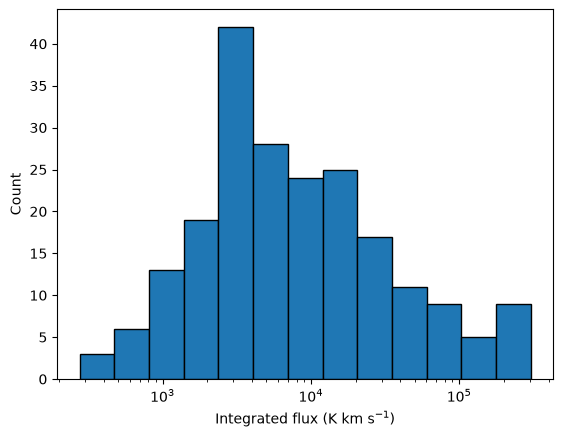

In [101]:
bins = np.logspace(
    np.log10(flux.min()),
    np.log10(flux.max()),
    int(np.sqrt(len(flux)))
)

plt.hist(flux, bins=bins, edgecolor='k')
plt.xscale('log')

plt.xlabel(r"Integrated flux (K km s$^{-1})$")
plt.ylabel('Count')
plt.savefig(destination_path + "FGN_027_13CO_23arcsec_aligned_integrated_flux_histogram.png")

In [89]:
flux.min()

552.1686353683472

In [90]:
flux.max()

605594.5792365074

In [130]:
print("Mean: ", np.nanmean(equal_ratio))
print("Median: ", np.nanmedian(equal_ratio))
print("Max: ", np.nanmax(equal_ratio))
print("Min: ", np.nanmin(equal_ratio))
print("Sigma: ", np.nanstd(equal_ratio))

Mean:  2.3179604948181534
Median:  1.9957041956567578
Max:  9.2116482608369
Min:  0.14185588235294116
Sigma:  1.4425188712845893


In [138]:
print(np.percentile(equal_ratio, 10))

0.8676313025210083
